# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

**Luật của "Mean" Connect 4 và các giả định của bài làm.** Mỗi lượt người chơi chọn **một** trong hai loại nước đi:

* **Thả quân** (`("drop", c)`): như Connect 4 thường – quân rơi xuống ô trống thấp nhất của cột `c`;
* **Chuyển quân** (`("move", cf, ct)`): lấy quân **ở hàng đáy của đối thủ** tại cột `cf`; các quân nằm trên nó trong cột đó **rơi xuống một ô**; rồi đặt quân vừa lấy vào cột `ct` bất kỳ (rơi xuống ô trống thấp nhất).

Đề bài để một số chi tiết mở, nên bài làm chọn và **giữ nhất quán** các quy ước sau cho cả hàm numpy, bitboard, môi trường và các tác tử:

1. **Quân được chuyển vẫn giữ màu của đối thủ** (đó là "quân của đối thủ"; người đi chỉ đổi vị trí của nó). Vì vậy nước chuyển quân *không thêm quân mới* nào vào bàn cờ.
2. **Chuyển quân không làm thay đổi bàn cờ** (cột `cf` chỉ toàn quân đối thủ rồi đặt lại đúng cột `cf`) bị loại khỏi tập hành động, tức là không có nước "bỏ lượt".
3. **Kết thúc ván:** sau mỗi nước đi, nếu *chỉ* người vừa đi có 4 quân liên tiếp thì người đó thắng; nếu *chỉ* đối thủ có 4 quân liên tiếp (do nước chuyển quân của mình làm quân của đối thủ rơi/đặt thành hàng) thì đối thủ thắng; nếu **cả hai** cùng có thì **hòa**; bàn cờ đầy (hết ô để thả quân) mà không ai thắng cũng **hòa**.
4. **Chống vòng lặp:** nước chuyển quân có thể đưa ván quay lại thế cờ cũ nên đồ thị trạng thái có **chu trình** và cây trò chơi **vô hạn**. Môi trường vì vậy tuyên bố **hòa** khi cùng một thế cờ (kèm người đến lượt) xuất hiện **lần thứ ba**, hoặc sau **200 nửa-nước**. Các thuật toán tìm kiếm không thể duyệt tới "cuối ván" nên luôn tìm tới một **độ sâu giới hạn** (horizon).
5. Vì nước chuyển quân không thêm quân, **số quân hai bên không còn xen kẽ cố định** và không thể suy ra người đến lượt từ bàn cờ; do đó mọi hàm nhận thêm tham số `player` (người đang đến lượt), đúng như chữ ký `agent(board, player)` của đề.

**Các thành phần của bài toán tìm kiếm** (bàn chuẩn 6 × 7, mảng numpy `hàng × cột`; `0` trống, `1` người 1 (Max, đỏ, đi trước), `-1` người −1 (Min, vàng); hàng 0 là hàng trên cùng):

| Thành phần | Mô tả | Hàm |
|---|---|---|
| **Trạng thái** | bàn cờ (mảng numpy) **cùng người đang đến lượt** | – |
| **Trạng thái đầu** | bàn cờ rỗng, người 1 đi | `initial_state(shape)` |
| **Hành động** | `("drop", c)` với mọi cột chưa đầy; `("move", cf, ct)` với mọi cột `cf` có quân đối thủ ở hàng đáy và mọi cột `ct` còn chỗ sau khi lấy quân đi | `actions(board, player)` |
| **Mô hình chuyển trạng thái** | thả quân, hoặc lấy quân đáy của đối thủ (cột đó rơi xuống một ô) rồi đặt quân đó (vẫn màu của đối thủ) vào cột `ct`; trả về bản sao | `result(board, player, action)` |
| **Kiểm tra kết thúc** | có người có 4 quân liên tiếp, hoặc bàn cờ đầy | `terminal(board)` |
| **Lợi ích** | +1 nếu chỉ `player` có 4 quân liên tiếp, −1 nếu chỉ đối thủ có, 0 nếu cả hai cùng có hoặc bàn đầy; `None` nếu chưa kết thúc | `utility(board, player)` |

In [1]:
# Your code/answer goes here.

import math, random, time, itertools, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MAX_PLIES = 200          # môi trường tuyên bố hòa sau số nửa-nước này (quy ước 4)

def initial_state(shape = (6, 7)):
    """Trạng thái đầu: bàn cờ rỗng (người 1 đi trước)."""
    return np.full(shape = shape, fill_value = 0)

def remove_bottom(board, col):
    """Bàn cờ sau khi bỏ quân ở hàng đáy của cột `col`: các quân phía trên rơi xuống một ô."""
    b = board.copy()
    b[1:, col] = board[:-1, col]
    b[0, col] = 0
    return b

def drop_actions(board):
    return [("drop", int(c)) for c in np.flatnonzero(board[0] == 0)]

def move_actions(board, player):
    """Chuyển quân: lấy quân đáy của đối thủ ở cột cf rồi đặt vào cột ct (cột phải còn chỗ SAU KHI lấy quân đi)."""
    rows, cols = board.shape
    acts = []
    for cf in range(cols):
        if board[rows - 1, cf] == -player:
            after = remove_bottom(board, cf)
            for ct in range(cols):
                if after[0, ct] != 0: continue                                    # cột đích đã đầy
                if ct == cf and not (board[:, cf] == player).any(): continue      # không làm thay đổi bàn cờ (quy ước 2)
                acts.append(("move", cf, ct))
    return acts

def actions(board, player = 1):
    """Mọi hành động hợp lệ của `player`: thả quân (cột chưa đầy) và chuyển quân. Trạng thái kết thúc không còn hành động nào
    (kể cả bàn đầy: ta coi là hòa dù về lý thuyết vẫn còn nước chuyển quân – quy ước 3)."""
    if terminal(board): return []
    return drop_actions(board) + move_actions(board, player)

def place(board, player, col):
    board[np.flatnonzero(board[:, col] == 0)[-1], col] = player

def result(board, player, action):
    """Mô hình chuyển trạng thái; trả về bản sao, không sửa bàn cờ gốc."""
    if action[0] == "drop":
        if board[0, action[1]] != 0: raise ValueError(f"cột {action[1]} đã đầy")
        b = board.copy(); place(b, player, action[1])
        return b
    _, cf, ct = action
    if board[board.shape[0] - 1, cf] != -player: raise ValueError(f"cột {cf} không có quân đối thủ ở hàng đáy")
    b = remove_bottom(board, cf)
    if b[0, ct] != 0: raise ValueError(f"cột đích {ct} đã đầy")
    place(b, -player, ct)                                                         # quân vẫn là của đối thủ (quy ước 1)
    return b

def has_four(board, p):
    """`p` có 4 quân liên tiếp (ngang, dọc, chéo) không? Dùng được cho bàn cờ kích thước bất kỳ."""
    b = (board == p)
    return bool((b[:, :-3] & b[:, 1:-2] & b[:, 2:-1] & b[:, 3:]).any() or (b[:-3, :] & b[1:-2, :] & b[2:-1, :] & b[3:, :]).any()
                or (b[:-3, :-3] & b[1:-2, 1:-2] & b[2:-1, 2:-1] & b[3:, 3:]).any() or (b[3:, :-3] & b[2:-1, 1:-2] & b[1:-2, 2:-1] & b[:-3, 3:]).any())

def utility(board, player = 1):
    """+1: chỉ `player` có 4 quân liên tiếp; −1: chỉ đối thủ có; 0: cả hai cùng có (quy ước 3) hoặc bàn đầy; None: chưa kết thúc."""
    a, b = has_four(board, player), has_four(board, -player)
    if a and not b: return +1
    if b and not a: return -1
    if a and b: return 0
    if (board[0] != 0).all(): return 0
    return None

def terminal(board):
    return utility(board, 1) is not None

# ---- thử nhanh: hai bên thả quân vào cột 3 và 4, rồi người 1 lấy quân đáy của người -1 (cột 4) đặt sang cột 6 ----
b = initial_state()
for who, act in ((1, ("drop", 3)), (-1, ("drop", 4)), (1, ("drop", 3)), (-1, ("drop", 4))):
    b = result(b, who, act)
print(b)
print("hành động của người 1:", actions(b, 1))
b2 = result(b, 1, ("move", 4, 6))
print("sau khi người 1 chuyển quân đáy của cột 4 sang cột 6 (quân -1 ở trên rơi xuống một ô, quân được chuyển vẫn là -1):")
print(b2)

[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  1 -1  0  0]
 [ 0  0  0  1 -1  0  0]]
hành động của người 1: [('drop', 0), ('drop', 1), ('drop', 2), ('drop', 3), ('drop', 4), ('drop', 5), ('drop', 6), ('move', 4, 0), ('move', 4, 1), ('move', 4, 2), ('move', 4, 3), ('move', 4, 5), ('move', 4, 6)]
sau khi người 1 chuyển quân đáy của cột 4 sang cột 6 (quân -1 ở trên rơi xuống một ô, quân được chuyển vẫn là -1):
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  1  0  0  0]
 [ 0  0  0  1 -1  0 -1]]


### Biểu diễn bitboard dùng bên trong các thuật toán tìm kiếm

Giao diện (`actions`, `result`, `utility`, tác tử `agent(board, player)`) dùng **mảng numpy** đúng như đề bài. Bên trong các tác tử, mỗi vị trí được đổi một lần sang **bitboard** (kỹ thuật của John Tromp, giống bài Connect 4): mỗi cột chiếm `rows + 1` bit (bit trên cùng là bit đệm), một vị trí là cặp số nguyên `(cur, opp)` = quân của người **đang đi** và quân của **đối thủ**. Với luật "Mean":

* **thả quân** vào cột `c`: ô mới là `(mask + bottom[c]) & col_mask[c]` với `mask = cur | opp`;
* **bỏ quân đáy của cột `cf`**: `(x & col_mask[cf]) >> 1` dịch cả cột xuống một ô (áp dụng cho cả hai bitboard) – chỉ ba phép toán bit, rồi đặt quân đã lấy vào cột `ct` như một nước thả quân;
* sau mỗi nước, tập "ô thắng" (`winning_cells`) cho biết ngay nước đi có tạo 4 quân liên tiếp cho ai không.

`MeanGeometry.children(cur, opp)` sinh **mọi** nước đi cùng vị trí kết quả (nhìn từ người đi tiếp theo) và giá trị kết thúc ván (nếu có). Ô code tiếp theo kiểm chứng nó với các hàm numpy ở trên.

In [2]:
popcount = int.bit_count if hasattr(int, "bit_count") else (lambda x: bin(x).count("1"))

class MeanGeometry:
    """Hằng số bit của bàn `rows x cols` (bố cục Tromp) và sinh nước đi cho luật "Mean"."""
    _cache = {}

    @classmethod
    def get(cls, rows, cols):
        if (rows, cols) not in cls._cache: cls._cache[(rows, cols)] = cls(rows, cols)
        return cls._cache[(rows, cols)]

    def __init__(self, rows, cols):
        self.rows, self.cols, self.cells = rows, cols, rows * cols
        self.H = H = rows + 1
        self.bottom = [1 << (c * H) for c in range(cols)]
        self.col_mask = [((1 << rows) - 1) << (c * H) for c in range(cols)]
        self.top = [1 << (c * H + rows - 1) for c in range(cols)]
        self.board_mask = sum(self.col_mask)
        self.bottom_row = sum(self.bottom)
        self.center_order = sorted(range(cols), key = lambda c: (abs(c - (cols - 1) / 2), c))
        mid = [cols // 2] if cols % 2 else [cols // 2 - 1, cols // 2]
        self.center_mask = sum(self.col_mask[c] for c in mid)
        self.windows = []                                   # mọi "cửa sổ" 4 ô thẳng hàng (dùng cho hàm heuristic)
        for dc, dk in ((0, 1), (1, 0), (1, 1), (1, -1)):
            for c in range(cols):
                for k in range(rows):
                    if 0 <= c + 3 * dc < cols and 0 <= k + 3 * dk < rows:
                        self.windows.append(sum(1 << ((c + j * dc) * H + k + j * dk) for j in range(4)))

    def to_bits(self, board, player):
        """(cur, opp): quân của `player` và quân của đối thủ."""
        cur = opp = 0
        for r, c in zip(*np.nonzero(board)):
            bit = 1 << (int(c) * self.H + (self.rows - 1 - int(r)))
            if board[r, c] == player: cur |= bit
            else: opp |= bit
        return cur, opp

    def to_board(self, cur, opp, player = 1):
        board = np.zeros((self.rows, self.cols), dtype = int)
        for c in range(self.cols):
            for k in range(self.rows):
                bit = 1 << (c * self.H + k)
                if cur & bit: board[self.rows - 1 - k, c] = player
                elif opp & bit: board[self.rows - 1 - k, c] = -player
        return board

    def is_win(self, pos):
        H = self.H
        m = pos & (pos >> H)
        if m & (m >> (2 * H)): return True
        m = pos & (pos >> (H - 1))
        if m & (m >> (2 * (H - 1))): return True
        m = pos & (pos >> (H + 1))
        if m & (m >> (2 * (H + 1))): return True
        m = pos & (pos >> 1)
        return bool(m & (m >> 2))

    def winning_cells(self, pos, mask):
        """Các ô trống mà nếu `pos` đặt quân vào thì có 4 quân liên tiếp."""
        H = self.H
        r = (pos << 1) & (pos << 2) & (pos << 3)
        for s in (H, H - 1, H + 1):
            p = (pos << s) & (pos << 2 * s)
            r |= p & (pos << 3 * s)
            r |= p & (pos >> s)
            p = (pos >> s) & (pos >> 2 * s)
            r |= p & (pos << s)
            r |= p & (pos >> 3 * s)
        return r & (self.board_mask ^ mask)

    def children(self, cur, opp, order = None):
        """Mọi nước đi của người đang đi (sở hữu `cur`). Mỗi phần tử: (hành động, cur_mới, opp_mới, giá trị cuối ván hoặc None).
        (cur_mới, opp_mới) là vị trí nhìn từ NGƯỜI ĐI TIẾP THEO; giá trị cuối ván (+1/0/-1) tính cho người vừa đi."""
        bottom, colm, top, bm = self.bottom, self.col_mask, self.top, self.board_mask
        order = range(self.cols) if order is None else order
        mask = cur | opp
        out = []
        cells = self.winning_cells(cur, mask)
        for c in order:                                             # --- thả quân
            if mask & top[c]: continue
            nb = (mask + bottom[c]) & colm[c]
            val = 1 if cells & nb else (0 if (mask | nb) == bm else None)
            out.append((("drop", c), opp, cur | nb, val))
        obottom = opp & self.bottom_row
        if obottom:
            for cf in order:                                        # --- chuyển quân đáy của đối thủ ở cột cf
                if not (obottom & bottom[cf]): continue
                cm = colm[cf]
                opp1 = (opp & ~cm) | (((opp & cm) >> 1) & cm)       # quân đối thủ còn lại trong cột rơi xuống
                cur1 = (cur & ~cm) | (((cur & cm) >> 1) & cm)       # quân của mình trong cột cũng rơi xuống
                mask1 = cur1 | opp1
                me_win, opp_has = self.is_win(cur1), self.is_win(opp1)
                ocells = self.winning_cells(opp1, mask1)
                for ct in order:
                    if mask1 & top[ct]: continue
                    if ct == cf and not (cur & cm): continue        # không làm thay đổi bàn cờ
                    nb = (mask1 + bottom[ct]) & colm[ct]
                    opp_win = opp_has or bool(ocells & nb)
                    val = (0 if opp_win else 1) if me_win else (-1 if opp_win else None)
                    out.append((("move", cf, ct), opp1 | nb, cur1, val))
        return out

In [3]:
def check_engine(shapes, games = 100, seed = 0, max_plies = 60):
    """Kiểm tra chéo bitboard với các hàm numpy trên các ván ngẫu nhiên: cùng tập hành động, cùng lợi ích, cùng bàn cờ kết quả."""
    rng = random.Random(seed)
    rows_out = []
    for shape in shapes:
        g = MeanGeometry.get(*shape)
        checked = n_moves = 0
        for _ in range(games):
            board, p = initial_state(shape), 1
            for _ in range(max_plies):
                if terminal(board): break
                cur, opp = g.to_bits(board, p)
                assert (g.to_board(cur, opp, p) == board).all()
                acts = actions(board, p)
                ch = g.children(cur, opp)
                assert sorted(a for a, *_ in ch) == sorted(acts), (shape, board, p)
                for a, nc, no, val in ch:
                    nxt = result(board, p, a)
                    assert utility(nxt, p) == val, (shape, board, p, a)
                    assert (g.to_board(nc, no, -p) == nxt).all(), (shape, board, p, a)
                    n_moves += 1
                board, p = result(board, p, rng.choice(acts)), -p
                checked += 1
        rows_out.append({"Kích thước (hàng x cột)": f"{shape[0]} x {shape[1]}", "Số vị trí đã kiểm tra": checked, "Số nước đi đã đối chiếu": n_moves, "Kết quả": "khớp hoàn toàn"})
    return pd.DataFrame(rows_out)

display(check_engine([(4, 4), (5, 6), (6, 7), (3, 9), (7, 5), (4, 7)], games = 60))

,Kích thước (hàng x cột),Số vị trí đã kiểm tra,Số nước đi đã đối chiếu,Kết quả
0,4 x 4,1096,9050,khớp hoàn toàn
1,5 x 6,1341,20616,khớp hoàn toàn
2,6 x 7,1443,27964,khớp hoàn toàn
3,3 x 9,1649,41795,khớp hoàn toàn
4,7 x 5,1293,15746,khớp hoàn toàn
5,4 x 7,1595,30896,khớp hoàn toàn


How big is the state space? Give an estimate and explain it.

In [4]:
# Your code/ answer goes here.

_SUP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")
def sci(x, digits = 2):
    """Số dạng a,b · 10ⁿ dùng trong các nhận xét."""
    m, e = f"{x:.{digits - 1}e}".split("e")
    return f"{m.replace('.', ',')} · 10{str(int(e)).translate(_SUP)}"

def state_bounds(rows, cols):
    """Hai cận trên cho số trạng thái (kèm người đến lượt, nên nhân 2)."""
    return 2 * 3 ** (rows * cols), 2 * (2 ** (rows + 1) - 1) ** cols      # mỗi ô 3 giá trị; có trọng lực: mỗi cột cao 0..rows, mỗi quân 2 màu

def balanced_bound(rows, cols):
    """Cận trên cho Connect 4 THƯỜNG (số quân hai bên chênh nhau tối đa 1): dùng để so sánh."""
    from math import comb
    N = [1] + [0] * (rows * cols)
    for _ in range(cols):
        new = [0] * (rows * cols + 1)
        for k, v in enumerate(N):
            if v:
                for h in range(rows + 1):
                    if k + h <= rows * cols: new[k + h] += v
        N = new
    return sum(N[k] * comb(k, (k + 1) // 2) for k in range(rows * cols + 1))

def reachable_states(rows, cols):
    """Duyệt theo chiều rộng (BFS) mọi trạng thái đạt được từ bàn rỗng: (số trạng thái, số trạng thái kết thúc, số cạnh chuyển trạng thái)."""
    g = MeanGeometry.get(rows, cols)
    seen, frontier, n_term, n_edges = {(0, 0)}, [(0, 0)], 0, 0
    while frontier:
        new = []
        for cur, opp in frontier:
            for a, nc, no, val in g.children(cur, opp):
                n_edges += 1
                if (nc, no) in seen: continue
                seen.add((nc, no))
                if val is None: new.append((nc, no))
                else: n_term += 1
        frontier = new
    return len(seen), n_term, n_edges

rows_out, fractions = [], []
for shape in [(3, 3), (4, 3), (3, 4), (5, 3), (4, 4)]:
    t0 = time.time()
    n, nt, ne = reachable_states(*shape)
    naive, gravity = state_bounds(*shape)
    fractions.append(n / gravity)
    rows_out.append({"Bàn cờ (hàng x cột)": f"{shape[0]} x {shape[1]}", "2·3^(số ô)": f"{naive:,}", "Cận có trọng lực": f"{gravity:,}", "Số trạng thái ĐẠT ĐƯỢC": f"{n:,}",
                     "Đạt được / cận": round(n / gravity, 2), "Trong đó kết thúc": f"{nt:,}", "Số nước TB mỗi trạng thái chưa kết thúc": round(ne / (n - nt), 1), "Thời gian (s)": round(time.time() - t0, 1)})
naive67, gravity67 = state_bounds(6, 7)
frac = float(np.mean(fractions[-3:]))                       # tỉ lệ "đạt được / cận" của các bàn lớn nhất đã đếm
est_states = frac * gravity67
STD_STATES_6x7 = 4_531_985_219_092                          # Connect 4 chuẩn (OEIS A212693), từ bài Connect 4
rows_out.append({"Bàn cờ (hàng x cột)": "6 x 7 (chuẩn)", "2·3^(số ô)": sci(naive67), "Cận có trọng lực": sci(gravity67), "Số trạng thái ĐẠT ĐƯỢC": f"≈ {sci(est_states)} (ước lượng)",
                 "Đạt được / cận": f"≈ {frac:.2f}", "Trong đó kết thúc": "–", "Số nước TB mỗi trạng thái chưa kết thúc": "–", "Thời gian (s)": "–"})
states_table = pd.DataFrame(rows_out)
display(states_table)
upper_ratio = (2 ** 7 - 1) ** 7 / balanced_bound(6, 7)        # cận có trọng lực / cận có cân bằng quân của Connect 4 thường

,Bàn cờ (hàng x cột),2·3^(số ô),Cận có trọng lực,Số trạng thái ĐẠT ĐƯỢC,Đạt được / cận,Trong đó kết thúc,Số nước TB mỗi trạng thái chưa kết thúc,Thời gian (s)
0,3 x 3,"39,366","6,750","3,311",0.49,448,3.9,0.0
1,4 x 3,"1,062,882","59,582","28,413",0.48,"6,769",4.5,0.2
2,3 x 4,"1,062,882","101,250","47,830",0.47,"7,439",5.9,0.3
3,5 x 3,"28,697,814","500,094","196,079",0.39,"47,287",4.8,1.1
4,4 x 4,"86,093,442","1,847,042","770,038",0.42,"273,054",7.0,4.9
5,6 x 7 (chuẩn),"2,2 · 10²⁰","1,1 · 10¹⁵","≈ 4,6 · 10¹⁴ (ước lượng)",≈ 0.43,–,–,–


In [5]:
display(Markdown(f"""
**Ước lượng số trạng thái (bàn chuẩn 6 × 7): cỡ {sci(est_states, 1)}** – khoảng **{est_states / STD_STATES_6x7:.0f} lần** nhiều hơn Connect 4 thường ({sci(STD_STATES_6x7)} vị trí).

Cách ước lượng:
1. Một trạng thái là bàn cờ cộng **người đến lượt**. Mỗi ô có 3 giá trị nên có tối đa 2 · 3⁴² ≈ {sci(naive67)} trạng thái; chặt hơn, do **trọng lực** mỗi cột chỉ cần chiều cao 0…6 và màu từng quân: 2 · 127⁷ ≈ {sci(gravity67)}.
2. Ở Connect 4 thường, hai người đặt quân xen kẽ nên số quân hai bên chênh nhau tối đa 1, giúp giảm cận đi khoảng {upper_ratio:.1f} lần. Ở bản "Mean" **ràng buộc này không còn**: nước chuyển quân không thêm quân nên số quân mỗi bên chênh nhau tùy ý (một người có thể liên tục chuyển quân trong khi người kia thả quân), và không thể suy ra người đến lượt từ bàn cờ.
3. Không thể dùng công thức đóng nên ta **đếm chính xác** (duyệt BFS) số trạng thái đạt được của các bàn nhỏ: chỉ **{min(fractions):.0%} – {max(fractions):.0%}** của cận có trọng lực là đạt được (phần còn lại không thể xuất hiện vì ván đã kết thúc khi có người đạt 4 quân liên tiếp). Nhân tỉ lệ ≈ {frac:.2f} của ba bàn lớn nhất với cận 6 × 7 cho ước lượng ≈ {sci(est_states)} – đây là **ngoại suy**, độ chính xác chỉ ở mức bậc độ lớn (tỉ lệ này có xu hướng giảm khi bàn lớn lên vì ngày càng nhiều vị trí không thể đạt được; ở Connect 4 thường 6 × 7 tỉ lệ so với cận có trọng lực chỉ là {STD_STATES_6x7 / 127 ** 7:.3f}).
4. Bảng cho thấy mỗi trạng thái chưa kết thúc của bàn 4 × 4 có trung bình {states_table.iloc[4]['Số nước TB mỗi trạng thái chưa kết thúc']} nước đi hợp lệ (tối đa 4 nước thả quân cộng các nước chuyển quân), trong khi Connect 4 thường chỉ có tối đa 4; đồ thị trạng thái còn **có chu trình**, nên khác Connect 4 thường, các vị trí không thể sắp xếp theo số quân.

**Ý nghĩa:** lưu mọi trạng thái (≈ {est_states * 8 / 1e12:.0f} TB nếu 8 byte/trạng thái) là không thể; thuật toán phải dựa trên tìm kiếm có giới hạn độ sâu và bảng chuyển vị kích thước có hạn.
"""))


**Ước lượng số trạng thái (bàn chuẩn 6 × 7): cỡ 5 · 10¹⁴** – khoảng **100 lần** nhiều hơn Connect 4 thường (4,5 · 10¹² vị trí).

Cách ước lượng:
1. Một trạng thái là bàn cờ cộng **người đến lượt**. Mỗi ô có 3 giá trị nên có tối đa 2 · 3⁴² ≈ 2,2 · 10²⁰ trạng thái; chặt hơn, do **trọng lực** mỗi cột chỉ cần chiều cao 0…6 và màu từng quân: 2 · 127⁷ ≈ 1,1 · 10¹⁵.
2. Ở Connect 4 thường, hai người đặt quân xen kẽ nên số quân hai bên chênh nhau tối đa 1, giúp giảm cận đi khoảng 7.5 lần. Ở bản "Mean" **ràng buộc này không còn**: nước chuyển quân không thêm quân nên số quân mỗi bên chênh nhau tùy ý (một người có thể liên tục chuyển quân trong khi người kia thả quân), và không thể suy ra người đến lượt từ bàn cờ.
3. Không thể dùng công thức đóng nên ta **đếm chính xác** (duyệt BFS) số trạng thái đạt được của các bàn nhỏ: chỉ **39% – 49%** của cận có trọng lực là đạt được (phần còn lại không thể xuất hiện vì ván đã kết thúc khi có người đạt 4 quân liên tiếp). Nhân tỉ lệ ≈ 0.43 của ba bàn lớn nhất với cận 6 × 7 cho ước lượng ≈ 4,6 · 10¹⁴ – đây là **ngoại suy**, độ chính xác chỉ ở mức bậc độ lớn (tỉ lệ này có xu hướng giảm khi bàn lớn lên vì ngày càng nhiều vị trí không thể đạt được; ở Connect 4 thường 6 × 7 tỉ lệ so với cận có trọng lực chỉ là 0.009).
4. Bảng cho thấy mỗi trạng thái chưa kết thúc của bàn 4 × 4 có trung bình 7.0 nước đi hợp lệ (tối đa 4 nước thả quân cộng các nước chuyển quân), trong khi Connect 4 thường chỉ có tối đa 4; đồ thị trạng thái còn **có chu trình**, nên khác Connect 4 thường, các vị trí không thể sắp xếp theo số quân.

**Ý nghĩa:** lưu mọi trạng thái (≈ 3642 TB nếu 8 byte/trạng thái) là không thể; thuật toán phải dựa trên tìm kiếm có giới hạn độ sâu và bảng chuyển vị kích thước có hạn.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [6]:
# Your code/ answer goes here.

def knuth_estimate(rows, cols, depth, probes, seed = 0, relocate = True):
    """Ước lượng số nút của cây trò chơi CẮT Ở ĐỘ SÂU `depth` bằng phương pháp Knuth: đi một đường ngẫu nhiên từ gốc, gọi b_i là số nước đi
    hợp lệ tại độ sâu i thì  1 + b_0 + b_0 b_1 + ...  là ước lượng không chệch. `relocate = False` chỉ cho phép thả quân (Connect 4 thường)."""
    g = MeanGeometry.get(rows, cols)
    rng = random.Random(seed)
    total = total2 = 0.0
    for _ in range(probes):
        cur = opp = 0
        prod, est = 1, 1
        for ply in range(depth):
            ch = g.children(cur, opp)
            if not relocate: ch = [x for x in ch if x[0][0] == "drop"]
            prod *= len(ch); est += prod
            a, nc, no, val = ch[int(rng.random() * len(ch))]
            if val is not None: break                                     # nước đi dẫn tới trạng thái kết thúc
            cur, opp = nc, no
        total += est; total2 += est * est
    mean = total / probes
    return mean, math.sqrt(max(total2 / probes - mean * mean, 0) / probes)

def exact_tree_size(rows, cols, depth):
    """Số nút CHÍNH XÁC của cây cắt ở độ sâu `depth` (quy hoạch động: gộp các dãy nước đi dẫn tới cùng một vị trí)."""
    g = MeanGeometry.get(rows, cols)
    level, nodes = {(0, 0): 1}, 1
    for _ in range(depth):
        nxt = {}
        for (cur, opp), n in level.items():
            for a, nc, no, val in g.children(cur, opp):
                nodes += n
                if val is None: nxt[(nc, no)] = nxt.get((nc, no), 0) + n
        level = nxt
    return nodes

# 1) kiểm chứng phương pháp trên bàn 4 x 4 (đếm chính xác được tới độ sâu 6)
rows_out = []
for depth in (2, 4, 6):
    t0 = time.time()
    exact_n = exact_tree_size(4, 4, depth)
    est, se = knuth_estimate(4, 4, depth, 20000, seed = depth)
    rows_out.append({"Bàn": "4 x 4", "Độ sâu": depth, "Số nút CHÍNH XÁC": f"{exact_n:,}", "Ước lượng Knuth": f"{est:,.0f}", "Sai số chuẩn": f"{se:,.0f}",
                     "|ước lượng - thật| / sai số chuẩn": round(abs(est - exact_n) / max(se, 1e-9), 1)})
check_table = pd.DataFrame(rows_out)
display(check_table)

# 2) bàn chuẩn 6 x 7: kích thước của cây cắt ở độ sâu D, so với Connect 4 thường (chỉ thả quân)
TREE_DEPTHS = [2, 4, 6, 8, 10, 12, 16, 20]
tree_mean, tree_std = {}, {}
rows_out = []
for D in TREE_DEPTHS:
    tree_mean[D], _ = knuth_estimate(6, 7, D, 10000, seed = D)
    tree_std[D], _ = knuth_estimate(6, 7, D, 10000, seed = D, relocate = False)
    rows_out.append({"Độ sâu D (nửa-nước)": D, "Cây 'Mean' ≈ số nút": f"{tree_mean[D]:.3g}", "Connect 4 thường ≈ số nút": f"{tree_std[D]:.3g}", "Tỉ lệ": f"{tree_mean[D] / tree_std[D]:.3g} ×",
                     "Hệ số nhánh hiệu dụng (Mean)": round(tree_mean[D] ** (1 / D), 1)})
tree_table = pd.DataFrame(rows_out)
display(tree_table)

,Bàn,Độ sâu,Số nút CHÍNH XÁC,Ước lượng Knuth,Sai số chuẩn,|ước lượng - thật| / sai số chuẩn
0,4 x 4,2,33,33,0,0.0
1,4 x 4,4,"1,461","1,463",3,0.8
2,4 x 4,6,"88,849","88,577",292,0.9


,Độ sâu D (nửa-nước),Cây 'Mean' ≈ số nút,Connect 4 thường ≈ số nút,Tỉ lệ,Hệ số nhánh hiệu dụng (Mean)
0,2,99,57,1.74 ×,9.9
1,4,1.57e+04,2.8e+03,5.59 ×,11.2
2,6,3.61e+06,1.37e+05,26.3 ×,12.4
3,8,1.05e+09,6.64e+06,158 ×,13.4
4,10,3.63e+11,3.14e+08,1.16e+03 ×,14.3
5,12,1.38e+14,1.46e+10,9.4e+03 ×,15.1
6,16,2.67e+19,2.9e+13,9.23e+05 ×,16.4
7,20,6.53e+24,4.83e+16,1.35e+08 ×,17.4


In [7]:
D1, D2 = 10, 20
display(Markdown(f"""
**Cây trò chơi mà Minimax duyệt là VÔ HẠN nếu không có luật dừng** vì đồ thị trạng thái có chu trình (một nước chuyển quân rồi chuyển lại đưa ván về thế cũ). Do đó ta ước lượng **kích thước cây cắt ở độ sâu D** – đúng là cái mà một tìm kiếm có giới hạn độ sâu phải duyệt:

* **Phương pháp (Knuth):** đi các đường ngẫu nhiên từ gốc, nhân các hệ số nhánh gặp dọc đường. Bảng đầu tiên kiểm chứng phương pháp: ở bàn 4 × 4 ước lượng khớp số nút chính xác (tính bằng quy hoạch động): sai khác lớn nhất là {check_table['|ước lượng - thật| / sai số chuẩn'].max():.1f} sai số chuẩn.
* **Kết quả trên bàn 6 × 7:** độ sâu 10 ≈ **{tree_mean[D1]:.2g}** nút và độ sâu 20 ≈ **{tree_mean[D2]:.2g}** nút, so với {tree_std[D1]:.2g} và {tree_std[D2]:.2g} nút ở Connect 4 thường – tức **{tree_mean[D1] / tree_std[D1]:.0f} lần** (D = 10) và **{tree_mean[D2] / tree_std[D2]:.1g} lần** (D = 20) nhiều hơn. Hệ số nhánh hiệu dụng khoảng {tree_table.iloc[-1]['Hệ số nhánh hiệu dụng (Mean)']} (so với ≤ 7 ở Connect 4 thường) vì ngoài tối đa 7 nước thả quân còn có nhiều nước chuyển quân (mỗi quân đáy của đối thủ có thể đặt sang tối đa 7 cột).
* Cây tăng theo hàm mũ b^D với b lớn hơn nhiều so với Connect 4 thường, trong khi **không có độ sâu tối đa tự nhiên** (ở Connect 4 thường tối đa 42 nước). Vì vậy tìm kiếm tới cuối ván là **không thể** ngay cả khi cắt tỉa lý tưởng (≈ √ kích thước cây) hay trên các bàn nhỏ; ta buộc phải dùng độ sâu giới hạn (Task 3), hàm heuristic (Task 4) hoặc mô phỏng Monte Carlo (phần nâng cao).
"""))


**Cây trò chơi mà Minimax duyệt là VÔ HẠN nếu không có luật dừng** vì đồ thị trạng thái có chu trình (một nước chuyển quân rồi chuyển lại đưa ván về thế cũ). Do đó ta ước lượng **kích thước cây cắt ở độ sâu D** – đúng là cái mà một tìm kiếm có giới hạn độ sâu phải duyệt:

* **Phương pháp (Knuth):** đi các đường ngẫu nhiên từ gốc, nhân các hệ số nhánh gặp dọc đường. Bảng đầu tiên kiểm chứng phương pháp: ở bàn 4 × 4 ước lượng khớp số nút chính xác (tính bằng quy hoạch động): sai khác lớn nhất là 0.9 sai số chuẩn.
* **Kết quả trên bàn 6 × 7:** độ sâu 10 ≈ **3.6e+11** nút và độ sâu 20 ≈ **6.5e+24** nút, so với 3.1e+08 và 4.8e+16 nút ở Connect 4 thường – tức **1157 lần** (D = 10) và **1e+08 lần** (D = 20) nhiều hơn. Hệ số nhánh hiệu dụng khoảng 17.4 (so với ≤ 7 ở Connect 4 thường) vì ngoài tối đa 7 nước thả quân còn có nhiều nước chuyển quân (mỗi quân đáy của đối thủ có thể đặt sang tối đa 7 cột).
* Cây tăng theo hàm mũ b^D với b lớn hơn nhiều so với Connect 4 thường, trong khi **không có độ sâu tối đa tự nhiên** (ở Connect 4 thường tối đa 42 nước). Vì vậy tìm kiếm tới cuối ván là **không thể** ngay cả khi cắt tỉa lý tưởng (≈ √ kích thước cây) hay trên các bàn nhỏ; ta buộc phải dùng độ sâu giới hạn (Task 3), hàm heuristic (Task 4) hoặc mô phỏng Monte Carlo (phần nâng cao).


## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [8]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

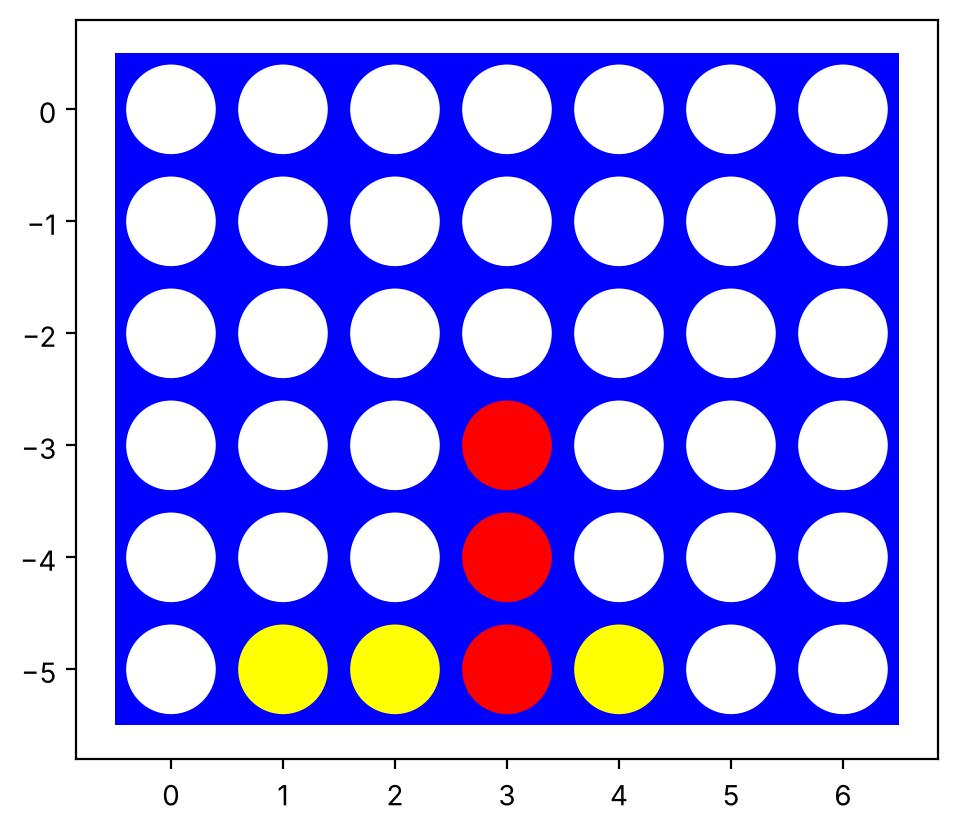

In [9]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [10]:
# Your code/ answer goes here.

# Các hàm actions / result / terminal / utility được định nghĩa ở Task 1 (ô code phía trên) và dùng lại ở đây.
# Ở Task 2 bổ sung các hàm tiện ích để TẠO và VẼ bàn cờ thử nghiệm; ô code kế tiếp kiểm thử các hàm trên nhiều kích thước bàn.
def board_from_strings(rows):
    """Tạo bàn cờ từ danh sách chuỗi (từ hàng trên xuống dưới): 'X' = người 1 (đỏ), 'O' = người -1 (vàng), '.' = trống."""
    sym = {".": 0, "X": 1, "O": -1}
    board = np.array([[sym[ch] for ch in row] for row in rows])
    for c in range(board.shape[1]):                              # kiểm tra trọng lực: không có quân lơ lửng
        col = board[:, c]
        filled = np.flatnonzero(col != 0)
        assert len(filled) == 0 or (col[filled[0]:] != 0).all(), f"quân lơ lửng ở cột {c}"
    return board

def draw_board(ax, board, title = None):
    """Vẽ bàn cờ lên trục `ax` (cùng phong cách với `visualize`)."""
    board = np.asarray(board)
    rows, cols = board.shape
    ax.add_patch(plt.Rectangle((-0.5, -rows + 0.5), cols, rows, fc = "blue"))
    for i in range(rows):
        for j in range(cols):
            v = board[i, j]
            ax.add_patch(plt.Circle((j, -i), 0.4, fc = "white" if v == 0 else "red" if v == 1 else "yellow"))
    ax.set_xlim(-0.6, cols - 0.4); ax.set_ylim(-rows + 0.4, 0.6); ax.set_aspect("equal"); ax.axis("off")
    if title: ax.set_title(title, fontsize = 9)

def visualize_grid(boards, titles = None, ncols = 4, size = 2.3):
    """Vẽ nhiều bàn cờ trong một hình."""
    n = len(boards)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize = (size * ncols * boards[0].shape[1] / 7, size * nrows * boards[0].shape[0] / 6 * 1.1))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        if i < n: draw_board(ax, boards[i], None if titles is None else titles[i])
        else: ax.axis("off")
    plt.tight_layout(); plt.show()

tất cả kiểm thử đạt


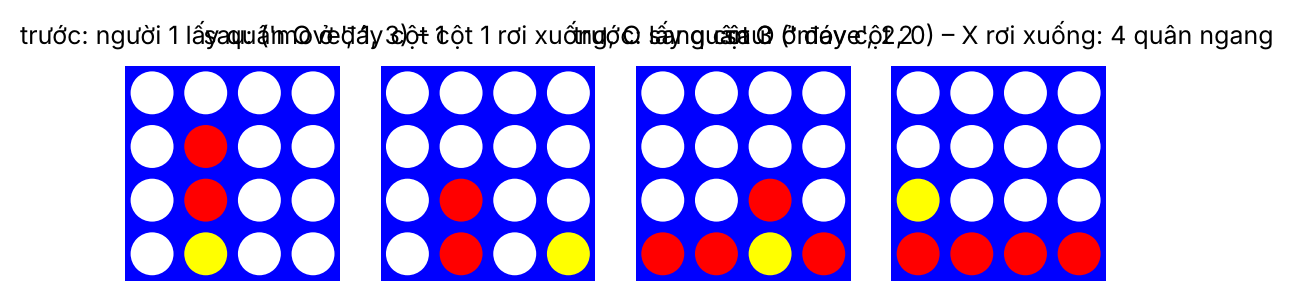

In [11]:
def run_unit_tests():
    # ---- các kiểm thử chung cho nhiều kích thước bàn cờ ----
    for shape in [(4, 4), (5, 6), (6, 7), (3, 9), (7, 5), (4, 7)]:
        rows, cols = shape
        b = initial_state(shape)
        assert actions(b, 1) == [("drop", c) for c in range(cols)] and not terminal(b) and utility(b, 1) is None
        assert move_actions(b, 1) == []                                          # bàn rỗng: chưa có quân đối thủ để lấy
        if rows >= 4:                                                            # thắng theo cột dọc
            v = b.copy()
            for _ in range(4): v = result(v, 1, ("drop", 0))
            assert utility(v, 1) == 1 and utility(v, -1) == -1 and terminal(v)
        h = b.copy()                                                             # thắng theo hàng ngang
        for c in range(4): h = result(h, -1, ("drop", c))
        assert utility(h, -1) == 1 and utility(h, 1) == -1
        before = b.copy(); result(b, 1, ("drop", 1)); assert (b == before).all()   # result không sửa bàn cờ gốc
        f = b.copy()                                                             # cột đầy: hành động bị loại và result báo lỗi
        for i in range(rows): f = result(f, 1 if i % 2 == 0 else -1, ("drop", 0))
        assert ("drop", 0) not in actions(f, 1)
        try: result(f, 1, ("drop", 0)); raise AssertionError("phải báo lỗi")
        except ValueError: pass
    # ---- các quy tắc "Mean" ----
    b = board_from_strings(["....", ".X..", ".X..", ".O.."])                      # cột 1: X, X, O (O ở đáy)
    assert ("move", 1, 3) in actions(b, 1) and not [a for a in actions(b, -1) if a[0] == "move" and a[1] == 1]   # chỉ lấy được quân ĐÁY của ĐỐI THỦ
    assert (result(b, 1, ("move", 1, 3)) == board_from_strings(["....", "....", ".X..", ".X.O"])).all()      # cột rơi xuống, quân vẫn là O
    assert ("move", 1, 1) in actions(b, 1)                                       # đặt lại đúng cột (lên trên cùng) vẫn đổi bàn cờ
    only_o = board_from_strings(["....", "....", "....", "O..."])
    assert ("move", 0, 0) not in actions(only_o, 1) and ("move", 0, 1) in actions(only_o, 1)     # quy ước 2: không có nước "bỏ lượt"
    shift_win = board_from_strings(["....", "....", "..X.", "XXOX"])              # lấy quân O ở đáy cột 2 -> quân X phía trên rơi xuống tạo hàng ngang
    assert utility(result(shift_win, 1, ("move", 2, 0)), 1) == 1
    assert not any(utility(result(shift_win, 1, a), 1) == 1 for a in drop_actions(shift_win))   # không có nước thả quân nào thắng ngay
    blunder = board_from_strings([".....", ".....", ".....", "OO.OO"])
    assert utility(result(blunder, 1, ("move", 0, 2)), 1) == -1                  # chuyển quân làm đối thủ có 4 quân liên tiếp => người đi thua
    both = board_from_strings(["........", "........", "........", "XXXXOOOO"])
    assert utility(both, 1) == 0 and utility(both, -1) == 0 and terminal(both)   # quy ước 3: cả hai cùng có 4 quân => hòa
    draw = board_from_strings(["XOXO", "XOXO", "OXOX", "OXOX"])
    assert terminal(draw) and utility(draw, 1) == 0 and actions(draw, 1) == drop_actions(draw) == []
    return "tất cả kiểm thử đạt"

print(run_unit_tests())
ex = board_from_strings(["....", ".X..", ".X..", ".O.."])
visualize_grid([ex, result(ex, 1, ("move", 1, 3)), board_from_strings(["....", "....", "..X.", "XXOX"]), result(board_from_strings(["....", "....", "..X.", "XXOX"]), 1, ("move", 2, 0))],
               ["trước: người 1 lấy quân O ở đáy cột 1", "sau: ('move', 1, 3) – cột 1 rơi xuống, O sang cột 3", "trước: lấy quân O ở đáy cột 2", "sau: ('move', 2, 0) – X rơi xuống: 4 quân ngang"], ncols = 4)

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [12]:
# Your code/ answer goes here.

def random_player(board, player = None):
    """Tác tử ngẫu nhiên: chọn đều ngẫu nhiên một hành động hợp lệ (thả quân hoặc chuyển quân).
    `player = None` được hiểu là người 1 (môi trường luôn truyền 1 hoặc -1)."""
    acts = actions(board, 1 if player is None else player)
    return acts[np.random.randint(len(acts))]

np.random.seed(0)
b = board_from_strings(["O......", "X......", "O......", "X......", "O......", "XO.X.O."])
print("Hành động hợp lệ của người 1:", len(actions(b, 1)), "(", len(drop_actions(b)), "thả quân và", len(move_actions(b, 1)), "chuyển quân )")
print("Tác tử ngẫu nhiên chọn:", [random_player(b, 1) for _ in range(5)])

Hành động hợp lệ của người 1: 16 ( 6 thả quân và 10 chuyển quân )
Tác tử ngẫu nhiên chọn: [('move', 5, 2), ('move', 5, 6), ('drop', 6), ('drop', 1), ('drop', 4)]


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

,Kết quả,Số ván,Tỷ lệ (%),Khoảng tin cậy 95 % (±)
0,"Người 1 (đỏ, đi trước) thắng",779,77.9,2.6
1,"Người -1 (vàng, đi sau) thắng",218,21.8,2.6
2,Hòa,3,0.3,0.3


Độ dài trung bình một ván: 25.2 nước (ngắn nhất 7, dài nhất 80); cách kết thúc: {'có người đạt 4 quân': 997, 'cả hai cùng có 4 quân': 3} – 2.8 s


20,000 ván (bitboard): người 1 thắng 76.3 %, người -1 thắng 23.0 %, hòa 0.71 %; độ dài TB 24.8 nước  [7 s]
Tỷ lệ nước CHUYỂN QUÂN trong các nước đi: người 1 45 %, người -1 66 %;  số ván thắng nhờ nước chuyển quân của đối thủ: người 1 6,472, người -1 1,980


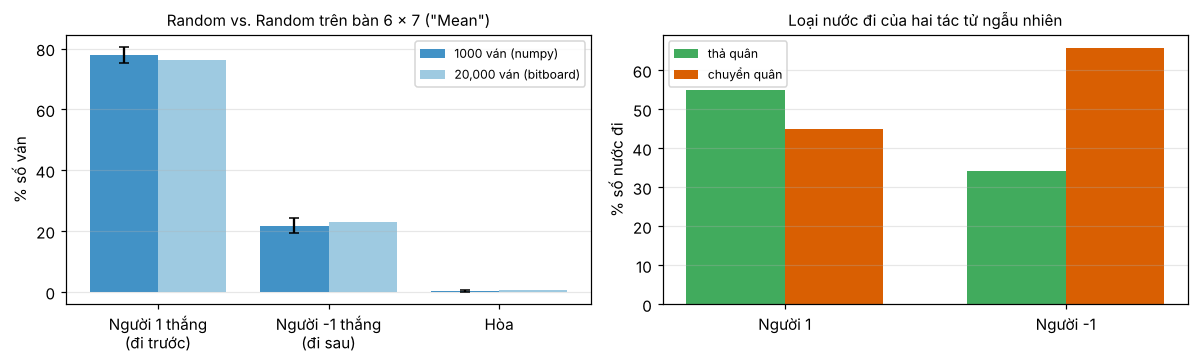

In [13]:
# Your code/ answer goes here.

def play_game(red, yellow, board = None, player = 1, max_plies = MAX_PLIES):
    """Một ván chơi. `red` điều khiển người 1, `yellow` điều khiển người -1; `player` là người đi trước. Môi trường chỉ gửi cho tác tử
    bàn cờ + người cần đi và nhận lại một hành động. Áp dụng quy ước 3 (kết thúc) và quy ước 4 (lặp lại 3 lần / quá giới hạn nước đi => hòa).
    Trả về dict: winner (1, -1, 0), plies, reason, time (thời gian suy nghĩ mỗi bên), board (bàn cờ cuối)."""
    agents = {1: red, -1: yellow}
    board = initial_state() if board is None else board.copy()
    seen, spent, plies = Counter({(board.tobytes(), player): 1}), {1: 0.0, -1: 0.0}, 0
    while True:
        u = utility(board, 1)
        if u is not None:
            both = has_four(board, 1) and has_four(board, -1)
            reason = "cả hai cùng có 4 quân" if both else ("bàn đầy" if not has_four(board, 1) and not has_four(board, -1) else "có người đạt 4 quân")
            return {"winner": u, "plies": plies, "reason": reason, "time": spent, "board": board}
        if plies >= max_plies:
            return {"winner": 0, "plies": plies, "reason": "quá giới hạn nước đi", "time": spent, "board": board}
        t0 = time.perf_counter()
        a = agents[player](board, player)
        spent[player] += time.perf_counter() - t0
        if a not in actions(board, player): raise ValueError(f"Tác tử của người {player} trả về hành động không hợp lệ: {a}")
        board, player, plies = result(board, player, a), -player, plies + 1
        seen[(board.tobytes(), player)] += 1
        if seen[(board.tobytes(), player)] >= 3:
            return {"winner": 0, "plies": plies, "reason": "lặp lại 3 lần", "time": spent, "board": board}

# ----- Hai tác tử ngẫu nhiên chơi 1000 ván -----
np.random.seed(2026)
t0 = time.time()
n = 1000
random_results, random_reasons, lengths = Counter({1: 0, -1: 0, 0: 0}), Counter(), []
for _ in range(n):
    g_ = play_game(random_player, random_player)
    random_results[g_["winner"]] += 1; random_reasons[g_["reason"]] += 1; lengths.append(g_["plies"])
ci = lambda k, n: 1.96 * math.sqrt((k / n) * (1 - k / n) / n) * 100
random_table = pd.DataFrame({
    "Kết quả": ["Người 1 (đỏ, đi trước) thắng", "Người -1 (vàng, đi sau) thắng", "Hòa"],
    "Số ván": [random_results[1], random_results[-1], random_results[0]],
    "Tỷ lệ (%)": [100 * random_results[k] / n for k in (1, -1, 0)],
    "Khoảng tin cậy 95 % (±)": [ci(random_results[k], n) for k in (1, -1, 0)]}).round(1)
display(random_table)
print(f"Độ dài trung bình một ván: {np.mean(lengths):.1f} nước (ngắn nhất {min(lengths)}, dài nhất {max(lengths)}); cách kết thúc: {dict(random_reasons)} – {time.time() - t0:.1f} s")

# ----- Ước lượng chính xác hơn và phân tích chi tiết bằng bitboard -----
def fast_random_games(rows, cols, n, seed = 0, max_plies = MAX_PLIES):
    """Chơi n ván ngẫu nhiên bằng bitboard (nhanh hơn nhiều so với numpy). Ghi lại kết quả, độ dài, số nước thả/chuyển quân của mỗi người
    và số ván thắng do CHÍNH nước chuyển quân của đối thủ tạo ra 4 quân cho mình."""
    g = MeanGeometry.get(rows, cols)
    rng = random.Random(seed)
    out = dict(res = Counter({1: 0, -1: 0, 0: 0}), drops = {1: 0, -1: 0}, moves = {1: 0, -1: 0}, own_win = Counter(), gift_win = Counter(), ended = Counter(), plies = 0)
    for _ in range(n):
        cur = opp = 0
        sign, plies, seen = 1, 0, Counter()
        while True:
            ch = g.children(cur, opp)
            a, nc, no, val = ch[int(rng.random() * len(ch))]
            plies += 1
            (out["drops"] if a[0] == "drop" else out["moves"])[sign] += 1
            if val is not None:
                winner = sign * val
                out["res"][winner] += 1
                if val == 1: out["own_win"][winner] += 1                  # người thắng tự tạo 4 quân bằng nước đi của mình
                elif val == -1: out["gift_win"][winner] += 1              # người thắng được "tặng" 4 quân do nước chuyển quân của đối thủ
                else: out["ended"]["hòa (cả hai cùng có 4 quân hoặc bàn đầy)"] += 1
                break
            cur, opp, sign = nc, no, -sign
            seen[(cur, opp)] += 1
            if seen[(cur, opp)] >= 3 or plies >= max_plies:
                out["res"][0] += 1; out["ended"]["hòa do lặp lại / quá giới hạn"] += 1; break
        out["plies"] += plies
    out["n"] = n
    return out

t0 = time.time()
NF = 20000
fast = fast_random_games(6, 7, NF, seed = 7)
share = lambda d: {k: 100 * d[k] / max(1, fast["drops"][k] + fast["moves"][k]) for k in (1, -1)}
reloc_share = {k: 100 * fast["moves"][k] / (fast["drops"][k] + fast["moves"][k]) for k in (1, -1)}
print(f"{NF:,} ván (bitboard): người 1 thắng {100 * fast['res'][1] / NF:.1f} %, người -1 thắng {100 * fast['res'][-1] / NF:.1f} %, hòa {100 * fast['res'][0] / NF:.2f} %; độ dài TB {fast['plies'] / NF:.1f} nước  [{time.time() - t0:.0f} s]")
print(f"Tỷ lệ nước CHUYỂN QUÂN trong các nước đi: người 1 {reloc_share[1]:.0f} %, người -1 {reloc_share[-1]:.0f} %;  "
      f"số ván thắng nhờ nước chuyển quân của đối thủ: người 1 {fast['gift_win'][1]:,}, người -1 {fast['gift_win'][-1]:,}")

fig, ax = plt.subplots(1, 2, figsize = (11, 3.4), dpi = 110)
x = np.arange(3)
ax[0].bar(x - 0.2, [100 * random_results[k] / n for k in (1, -1, 0)], 0.4, yerr = [ci(random_results[k], n) for k in (1, -1, 0)], capsize = 3, label = f"{n} ván (numpy)", color = "#4292c6")
ax[0].bar(x + 0.2, [100 * fast["res"][k] / NF for k in (1, -1, 0)], 0.4, label = f"{NF:,} ván (bitboard)", color = "#9ecae1")
ax[0].set_xticks(x); ax[0].set_xticklabels(["Người 1 thắng\n(đi trước)", "Người -1 thắng\n(đi sau)", "Hòa"]); ax[0].set_ylabel("% số ván")
ax[0].set_title('Random vs. Random trên bàn 6 x 7 ("Mean")', fontsize = 10); ax[0].legend(fontsize = 8); ax[0].grid(axis = "y", alpha = .3)
w = 0.35
ax[1].bar(np.arange(2) - w / 2, [100 * fast["drops"][k] / (fast["drops"][k] + fast["moves"][k]) for k in (1, -1)], w, label = "thả quân", color = "#41ab5d")
ax[1].bar(np.arange(2) + w / 2, [reloc_share[k] for k in (1, -1)], w, label = "chuyển quân", color = "#d95f02")
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(["Người 1", "Người -1"]); ax[1].set_ylabel("% số nước đi"); ax[1].set_title("Loại nước đi của hai tác tử ngẫu nhiên", fontsize = 10); ax[1].legend(fontsize = 8); ax[1].grid(axis = "y", alpha = .3)
plt.tight_layout(); plt.show()

In [14]:
f1, f2 = 100 * fast["res"][1] / NF, 100 * fast["res"][-1] / NF
gift_share = 100 * fast["gift_win"][1] / max(1, fast["res"][1])
display(Markdown(f"""
**Kết quả:** trong {n} ván, người 1 (đi trước) thắng **{random_results[1]}** ván ({100 * random_results[1] / n:.1f} %), người -1 thắng **{random_results[-1]}** ván ({100 * random_results[-1] / n:.1f} %) và hòa **{random_results[0]}** ván ({100 * random_results[0] / n:.1f} %); ước lượng chính xác hơn từ {NF:,} ván bitboard: {f1:.1f} % – {f2:.1f} % – {100 * fast['res'][0] / NF:.2f} %. Ván ngẫu nhiên dài trung bình {fast['plies'] / NF:.1f} nước.

**Kết quả có đúng như mong đợi không? Có đúng hướng, nhưng độ chênh lệch lớn hơn Connect 4 thường** (ở đó, mô phỏng 200 000 ván ngẫu nhiên cho người đi trước thắng ≈ 55,8 %, người đi sau ≈ 44,0 % và hòa ≈ 0,25 %):
* **Lợi thế đi trước vẫn có**: hai tác tử giống hệt nhau nên chênh lệch do đi trước (người 1 luôn có số quân bằng hoặc hơn và là người đầu tiên có thể tạo 4 quân liên tiếp). Chênh lệch ({f1:.1f} % so với {f2:.1f} %) vượt xa khoảng tin cậy 95 % (± {ci(random_results[1], n):.1f} %) của {n} ván.
* **Nước chuyển quân làm lợi thế đi trước lớn hơn nữa.** Sau nước đầu của người 1 chỉ người 1 có quân ở hàng đáy, nên người -1 có rất nhiều nước chuyển quân để chọn ngẫu nhiên; kết quả là người -1 chọn nước chuyển quân tới {reloc_share[-1]:.0f} % số lần (người 1: {reloc_share[1]:.0f} %). Nước chuyển quân **không thêm quân vào bàn cờ**, nên người -1 tụt lại về số quân so với người 1.
* **Nước chuyển quân ngẫu nhiên rất dễ "tự phá":** {gift_share:.0f} % số ván người 1 thắng là do nước chuyển quân của người -1 vô tình tạo 4 quân liên tiếp cho người 1 (rơi xuống hoặc được đặt vào hàng), chứ không phải do người 1 tự tạo ra – điều không thể xảy ra ở Connect 4 thường.
* **Hòa rất hiếm** ({100 * fast['res'][0] / NF:.2f} %): ván hết rất nhanh nên hầu như không bao giờ gặp bàn cờ đầy, lặp lại thế cờ hay quá giới hạn nước đi; tỉ lệ ván phải kết thúc vì luật chống lặp là {100 * fast['ended']['hòa do lặp lại / quá giới hạn'] / NF:.3f} %.
"""))


**Kết quả:** trong 1000 ván, người 1 (đi trước) thắng **779** ván (77.9 %), người -1 thắng **218** ván (21.8 %) và hòa **3** ván (0.3 %); ước lượng chính xác hơn từ 20,000 ván bitboard: 76.3 % – 23.0 % – 0.71 %. Ván ngẫu nhiên dài trung bình 24.8 nước.

**Kết quả có đúng như mong đợi không? Có đúng hướng, nhưng độ chênh lệch lớn hơn Connect 4 thường** (ở đó, mô phỏng 200 000 ván ngẫu nhiên cho người đi trước thắng ≈ 55,8 %, người đi sau ≈ 44,0 % và hòa ≈ 0,25 %):
* **Lợi thế đi trước vẫn có**: hai tác tử giống hệt nhau nên chênh lệch do đi trước (người 1 luôn có số quân bằng hoặc hơn và là người đầu tiên có thể tạo 4 quân liên tiếp). Chênh lệch (76.3 % so với 23.0 %) vượt xa khoảng tin cậy 95 % (± 2.6 %) của 1000 ván.
* **Nước chuyển quân làm lợi thế đi trước lớn hơn nữa.** Sau nước đầu của người 1 chỉ người 1 có quân ở hàng đáy, nên người -1 có rất nhiều nước chuyển quân để chọn ngẫu nhiên; kết quả là người -1 chọn nước chuyển quân tới 66 % số lần (người 1: 45 %). Nước chuyển quân **không thêm quân vào bàn cờ**, nên người -1 tụt lại về số quân so với người 1.
* **Nước chuyển quân ngẫu nhiên rất dễ "tự phá":** 42 % số ván người 1 thắng là do nước chuyển quân của người -1 vô tình tạo 4 quân liên tiếp cho người 1 (rơi xuống hoặc được đặt vào hàng), chứ không phải do người 1 tự tạo ra – điều không thể xảy ra ở Connect 4 thường.
* **Hòa rất hiếm** (0.71 %): ván hết rất nhanh nên hầu như không bao giờ gặp bàn cờ đầy, lặp lại thế cờ hay quá giới hạn nước đi; tỉ lệ ván phải kết thúc vì luật chống lặp là 0.050 %.


## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

### Tác tử Minimax + Alpha-Beta cho "Mean" Connect 4

Tác tử dưới đây là **negamax với cắt tỉa Alpha-Beta** trên bitboard (xem phần Task 1). Vì cây trò chơi của "Mean" Connect 4 là **vô hạn** (nước chuyển quân tạo chu trình), không thể tìm "tới cuối ván" như ở Connect 4 thường; thay vào đó tác tử tìm tới **độ sâu giới hạn `depth` (tính bằng nửa-nước)** và các thiết kế sau:

* **Giá trị chính xác trong tầm nhìn.** Trạng thái kết thúc có lợi ích thật (+1 thắng, −1 thua, 0 hòa); vị trí chưa kết thúc ở độ sâu giới hạn có giá trị 0 ("chưa biết", Task 4 sẽ thay bằng heuristic). Do đó giá trị gốc +1 nghĩa là *ép được thắng trong `depth` nửa-nước*, −1 là *bị ép thua*, 0 là *chưa phân thắng bại trong tầm nhìn*. Một phần thưởng nhỏ theo số nửa-nước còn lại (`EPS = 0,001`) giúp ưu tiên thắng nhanh và thua chậm; nó không bao giờ làm đảo thứ tự các giá trị.
* **Sắp xếp nước đi:** xét ngay nước thắng ngay (nếu có), cột từ giữa ra hai bên, nước thả quân trước nước chuyển quân (các tùy chọn khác dùng để so sánh ở phần "Move ordering").
* **Bảng chuyển vị** (khóa là cặp bitboard `(cur, opp)`; lưu độ sâu đã tìm, cờ cận trên / cận dưới / chính xác và giá trị): nhiều dãy nước khác nhau, đặc biệt các cặp "chuyển quân rồi chuyển lại", dẫn tới cùng một vị trí.
* **Đối xứng trái–phải ở gốc** khi bàn rỗng: chỉ xét một nửa số cột.
* **Giả định:** lịch sử ván không thuộc trạng thái nên tìm kiếm *không mô hình hóa* luật "hòa khi lặp thế cờ 3 lần" của môi trường; điều này chỉ có thể ảnh hưởng khi tìm sâu hơn 8 nửa-nước (một thế cờ cần ít nhất 8 nửa-nước mới lặp 3 lần).
* **Giao diện:** `AlphaBetaPlayer(depth)(board, player)` trả về một hành động, đúng chữ ký của đề; `action_values(board, player)` trả về giá trị của *từng* hành động ở gốc (dùng cho phân tích).

In [15]:
# Your code/ answer goes here.

class AlphaBetaPlayer:
    """Minimax (dạng negamax) với cắt tỉa Alpha-Beta, tìm tới độ sâu giới hạn `depth` (tính bằng nửa-nước) – xem quy ước 4: cây vô hạn nên
    không thể tìm tới cuối ván. Trạng thái kết thúc có lợi ích thật (+1 thắng, −1 thua, 0 hòa); vị trí chưa kết thúc ở độ sâu giới hạn có giá trị
    `evaluate(g, cur, opp)` (mặc định 0 = "chưa biết"), nên giá trị là CHÍNH XÁC khi ván phân thắng bại trong tầm nhìn.
    Thắng sớm được ưu tiên hơn thắng muộn (và thua muộn hơn thua sớm) bằng một phần thưởng nhỏ theo số nửa-nước còn lại.
      ordering   : "center" (cột từ giữa ra), "natural" (trái -> phải) hoặc "edges" (từ biên vào giữa – tệ nhất, để so sánh)
      wins_first : xét nước thắng ngay trước
      drops_first: xét nước thả quân trước nước chuyển quân (False: ngược lại – dùng để so sánh)
      use_tt     : bảng chuyển vị (khóa = (cur, opp), lưu độ sâu, cờ cận và giá trị)
      symmetry_root: bàn rỗng đối xứng nên chỉ xét một nửa số cột ở gốc
    """
    EPS = 0.001

    class TimeUp(Exception):
        """Hết thời gian cho phép (dùng cho tìm kiếm sâu dần)."""

    def __init__(self, depth = 6, evaluate = None, ordering = "center", wins_first = True, drops_first = True, use_tt = True,
                 symmetry_root = True, name = None):
        self.depth, self.evaluate, self.ordering, self.wins_first, self.drops_first = depth, evaluate, ordering, wins_first, drops_first
        self.use_tt, self.symmetry_root = use_tt, symmetry_root
        self.tt, self.nodes, self.last_value, self.best_action = {}, 0, None, None
        self.deadline = None                      # mốc thời gian (time.perf_counter) phải dừng; None = không giới hạn
        self.name = name or f"Alpha-Beta (độ sâu {depth})"

    def __call__(self, board, player = None):
        self.search(board, 1 if player is None else player)
        return self.best_action

    def action_values(self, board, player = 1):
        """Giá trị của TỪNG hành động (cửa sổ đầy đủ ở gốc): dict hành động -> giá trị."""
        return self.search(board, player, analyze = True)

    def search(self, board, player, analyze = False):
        g = MeanGeometry.get(*board.shape)
        cur, opp = g.to_bits(board, player)
        tt = self.tt if self.use_tt else None
        if tt is not None: tt.clear()
        order = {"center": g.center_order, "natural": list(range(g.cols)), "edges": g.center_order[::-1]}[self.ordering]
        evaluate, children, EPS = self.evaluate, g.children, self.EPS
        wins_first, drops_first, deadline = self.wins_first, self.drops_first, self.deadline
        nodes = 0

        def ordered(ch):
            if not drops_first: ch = [x for x in ch if x[0][0] == "move"] + [x for x in ch if x[0][0] == "drop"]
            if wins_first: ch.sort(key = lambda x: x[3] != 1)           # sắp xếp ổn định: nước thắng ngay lên đầu
            return ch

        def negamax(cur, opp, depth, alpha, beta):
            nonlocal nodes
            nodes += 1
            if deadline is not None and not nodes & 1023 and time.perf_counter() > deadline: raise AlphaBetaPlayer.TimeUp()
            if depth == 0: return evaluate(g, cur, opp) if evaluate else 0.0
            if tt is not None:
                key = (cur, opp)
                entry = tt.get(key)
                if entry is not None and entry[0] >= depth:             # chỉ dùng nếu đã tìm sâu ít nhất bằng độ sâu còn lại
                    _, flag, val = entry
                    if flag == 0: return val
                    if flag == 1:
                        if val >= beta: return val
                        if val > alpha: alpha = val
                    else:
                        if val <= alpha: return val
                        if val < beta: beta = val
                    if alpha >= beta: return val
                alpha0 = alpha
            best = -3.0
            for a, nc, no, val in ordered(children(cur, opp, order)):
                v = -negamax(nc, no, depth - 1, -beta, -alpha) if val is None else val * (1 + EPS * (depth - 1))
                if v > best:
                    best = v
                    if v > alpha:
                        alpha = v
                        if alpha >= beta: break
            if tt is not None:
                tt[key] = (depth, 2 if best <= alpha0 else (1 if best >= beta else 0), best)
            return best

        root_order = order
        if self.symmetry_root and not (cur | opp):
            root_order = [c for c in order if c <= (g.cols - 1) // 2]    # bàn rỗng đối xứng trái-phải
        values, best, best_a, alpha, beta = {}, -3.0, None, -2.0, 2.0
        for a, nc, no, val in ordered(children(cur, opp, root_order)):
            v = -negamax(nc, no, self.depth - 1, -beta, -alpha) if val is None else val * (1 + EPS * (self.depth - 1))
            values[a] = v
            if v > best:
                best, best_a = v, a
                if not analyze and v > alpha: alpha = v
        self.nodes, self.last_value, self.best_action = nodes, best + 0.0, best_a
        return values if analyze else best

**Kiểm tra tính đúng đắn.** Bitboard dễ sai tinh vi, nên trước khi dùng ta đối chiếu tác tử với một **Minimax thuần** viết riêng bằng numpy (không cắt tỉa, không bảng chuyển vị, dùng đúng các hàm `actions` / `result` / `utility` của Task 1): trên các bàn nhỏ và thế cờ ngẫu nhiên, giá trị của *từng* hành động phải trùng nhau, với cả ba cấu hình thứ tự duyệt / bảng chuyển vị.

In [16]:
# ---- Kiểm tra chéo: tác tử bitboard phải cho CÙNG giá trị các nước đi như Minimax thuần (numpy, không cắt tỉa, không bảng chuyển vị) ----
def naive_values(board, player, depth):
    """Giá trị Minimax thuần của từng hành động tới độ sâu `depth` (lợi ích thật; chưa phân thắng bại: 0) – dùng làm chuẩn để so sánh."""
    def value(b, mover, d):                                  # giá trị của b (chưa kết thúc) đối với `mover` đang đi, còn d nửa-nước
        if d == 0: return 0
        best = -2
        for a in actions(b, mover):
            nxt = result(b, mover, a)
            u = utility(nxt, mover)
            best = max(best, u if u is not None else -value(nxt, -mover, d - 1))
        return best
    out = {}
    for a in actions(board, player):
        nxt = result(board, player, a)
        u = utility(nxt, player)
        out[a] = u if u is not None else -value(nxt, -player, depth - 1)
    return out

def cross_validate(shapes, per_shape = 20, depth = 3, seed = 3):
    rng = random.Random(seed)
    rows_out = []
    for shape in shapes:
        n_pos = 0
        for _ in range(per_shape):
            b, p = initial_state(shape), 1
            for _ in range(rng.randint(2, 9)):
                if terminal(b): break
                acts = actions(b, p); b = result(b, p, acts[rng.randrange(len(acts))]); p = -p
            if terminal(b): continue
            ref = naive_values(b, p, depth)
            for kw in (dict(), dict(ordering = "natural", wins_first = False, use_tt = False), dict(drops_first = False)):
                got = AlphaBetaPlayer(depth = depth, **kw).action_values(b, p)
                assert {a: round(v) for a, v in got.items()} == ref, (shape, kw, b, p)
                ab = AlphaBetaPlayer(depth = depth, **kw)
                a = ab(b, p)
                assert round(ab.last_value) == max(ref.values()) and round(got[a]) == max(ref.values()), (shape, kw)
            n_pos += 1
        rows_out.append({"Kích thước": f"{shape[0]} x {shape[1]}", "Số vị trí thử": n_pos, "Độ sâu": depth, "Số cấu hình Alpha-Beta so sánh": 3, "Kết quả": "giá trị và nước đi đều khớp Minimax thuần"})
    return pd.DataFrame(rows_out)

display(cross_validate([(4, 4), (4, 5), (5, 4)], per_shape = 15))

,Kích thước,Số vị trí thử,Độ sâu,Số cấu hình Alpha-Beta so sánh,Kết quả
0,4 x 4,15,3,3,giá trị và nước đi đều khớp Minimax thuần
1,4 x 5,15,3,3,giá trị và nước đi đều khớp Minimax thuần
2,5 x 4,15,3,3,giá trị và nước đi đều khớp Minimax thuần


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

**Bảy bàn cờ thử** (bàn chuẩn 6 × 7; `X` = người 1 đỏ, `O` = người −1 vàng; kèm người đến lượt vì không suy ra được từ bàn cờ):

| # | Tình huống | Ý tưởng |
|---|---|---|
| 1 | Thắng ngay bằng **thả quân** (X) | X có ba quân xếp dọc ở cột 5; thả thêm một quân vào cột 5 là thắng. |
| 2 | Thắng ngay bằng **chuyển quân** (O) | O lấy quân đáy của X ở cột 4: hai quân O phía trên rơi xuống hàng đáy và nối với hai quân O sẵn có thành hàng 4 – đòn chỉ có ở "Mean" Connect 4. |
| 3 | Phải chặn bằng **thả quân** (O) | X có ba quân dọc ở cột 2; O phải thả vào cột 2. |
| 4 | Phải chặn bằng **chuyển quân** (X) | O đe dọa đồng thời (a) thả vào cột 3 để nối hàng 4 ngang và (b) lấy quân đáy của X ở cột 1 để quân O phía trên rơi xuống thành hàng 4 ở đáy. Nước chặn quen thuộc (thả quân vào cột 3) chỉ chặn được (a); chỉ việc **lấy quân O ở đáy cột 3** mới vô hiệu hóa cả hai. |
| 5 | Thắng ép sau 3 nửa-nước (X) | Thả quân vào cột 3 rồi "xoay" cột 3 (lấy quân O ở đáy đặt lên đỉnh cùng cột) để quân X rơi xuống nối thành hàng ngang ở đáy; đối thủ không cản được. |
| 6 | Thắng ép sau 5 nửa-nước (O) | Chuỗi thả quân và xoay cột dài hơn, đòi hỏi nhìn trước 5 nửa-nước. |
| 7 | Thế cân bằng (O) | Không có đòn chiến thuật; vài nước đi là sai lầm (thua trong tầm nhìn). |

Đáp án chuẩn của mỗi bàn (giá trị từng hành động) được tính bởi **cùng thuật toán nhưng tìm sâu hơn mọi độ sâu thử**, rồi so với các độ sâu nhỏ hơn. Ngoài việc "chọn có đúng không", ta ghi cả mức **chắc chắn**: dấu `✓` = chọn đúng *và* mọi nước ngang điểm ở đầu bảng đều đúng; `?` = chọn đúng nhưng còn nước sai ngang điểm (đúng nhờ thứ tự duyệt, tức là may mắn); `✗` = chọn sai.

Đáp án chuẩn (tính bởi tác tử tìm sâu 9 nửa-nước):


,Đến lượt,Số hành động,Giá trị (tầm nhìn 9),Thắng ép sau (nửa-nước),Nước giữ được kết quả
Bàn cờ,,,,,
1. Thắng ngay: thả quân,X (đỏ),27,thắng,1,thả 5
2. Thắng ngay: chuyển quân,O (vàng),14,thắng,1,"thả 3, thả 4, chuyển 4→0, … (9 nước)"
3. Phải chặn: thả quân,O (vàng),19,chưa phân thắng bại,–,1/19 nước không thua
4. Phải chặn: chuyển quân,X (đỏ),25,chưa phân thắng bại,–,4/25 nước không thua
5. Thắng sau 3 nửa-nước,X (đỏ),13,thắng,3,"thả 1, thả 3, thả 5"
6. Thắng sau 5 nửa-nước,O (vàng),27,thắng,5,"thả 0, thả 3, thả 4, … (7 nước)"
7. Thế cân bằng (có nước đi dở),O (vàng),32,chưa phân thắng bại,–,27/32 nước không thua


,d=1,d=2,d=3,d=4,d=5,d=6,d=8,Độ sâu tối thiểu để chắc chắn đúng
Bàn cờ,,,,,,,,
1. Thắng ngay: thả quân,thả 5 ✓,thả 5 ✓,thả 5 ✓,thả 5 ✓,thả 5 ✓,thả 5 ✓,thả 5 ✓,1
2. Thắng ngay: chuyển quân,chuyển 4→3 ✓,chuyển 4→3 ✓,chuyển 4→3 ✓,chuyển 4→3 ✓,chuyển 4→3 ✓,chuyển 4→3 ✓,chuyển 4→3 ✓,1
3. Phải chặn: thả quân,thả 3 ✗,thả 2 ✓,thả 2 ✓,thả 2 ✓,thả 2 ✓,thả 2 ✓,thả 2 ✓,2
4. Phải chặn: chuyển quân,thả 3 ✗,chuyển 3→4 ✓,chuyển 3→4 ✓,chuyển 3→4 ✓,chuyển 3→4 ✓,chuyển 3→4 ✓,chuyển 3→4 ✓,2
5. Thắng sau 3 nửa-nước,thả 3 ?,thả 3 ?,thả 3 ✓,thả 3 ✓,thả 3 ✓,thả 3 ✓,thả 3 ✓,3
6. Thắng sau 5 nửa-nước,thả 3 ?,thả 3 ?,thả 3 ?,thả 3 ?,thả 3 ✓,thả 3 ✓,thả 3 ✓,5
7. Thế cân bằng (có nước đi dở),thả 3 ?,thả 3 ✓,thả 3 ✓,thả 3 ✓,thả 3 ✓,thả 3 ✓,thả 3 ✓,2


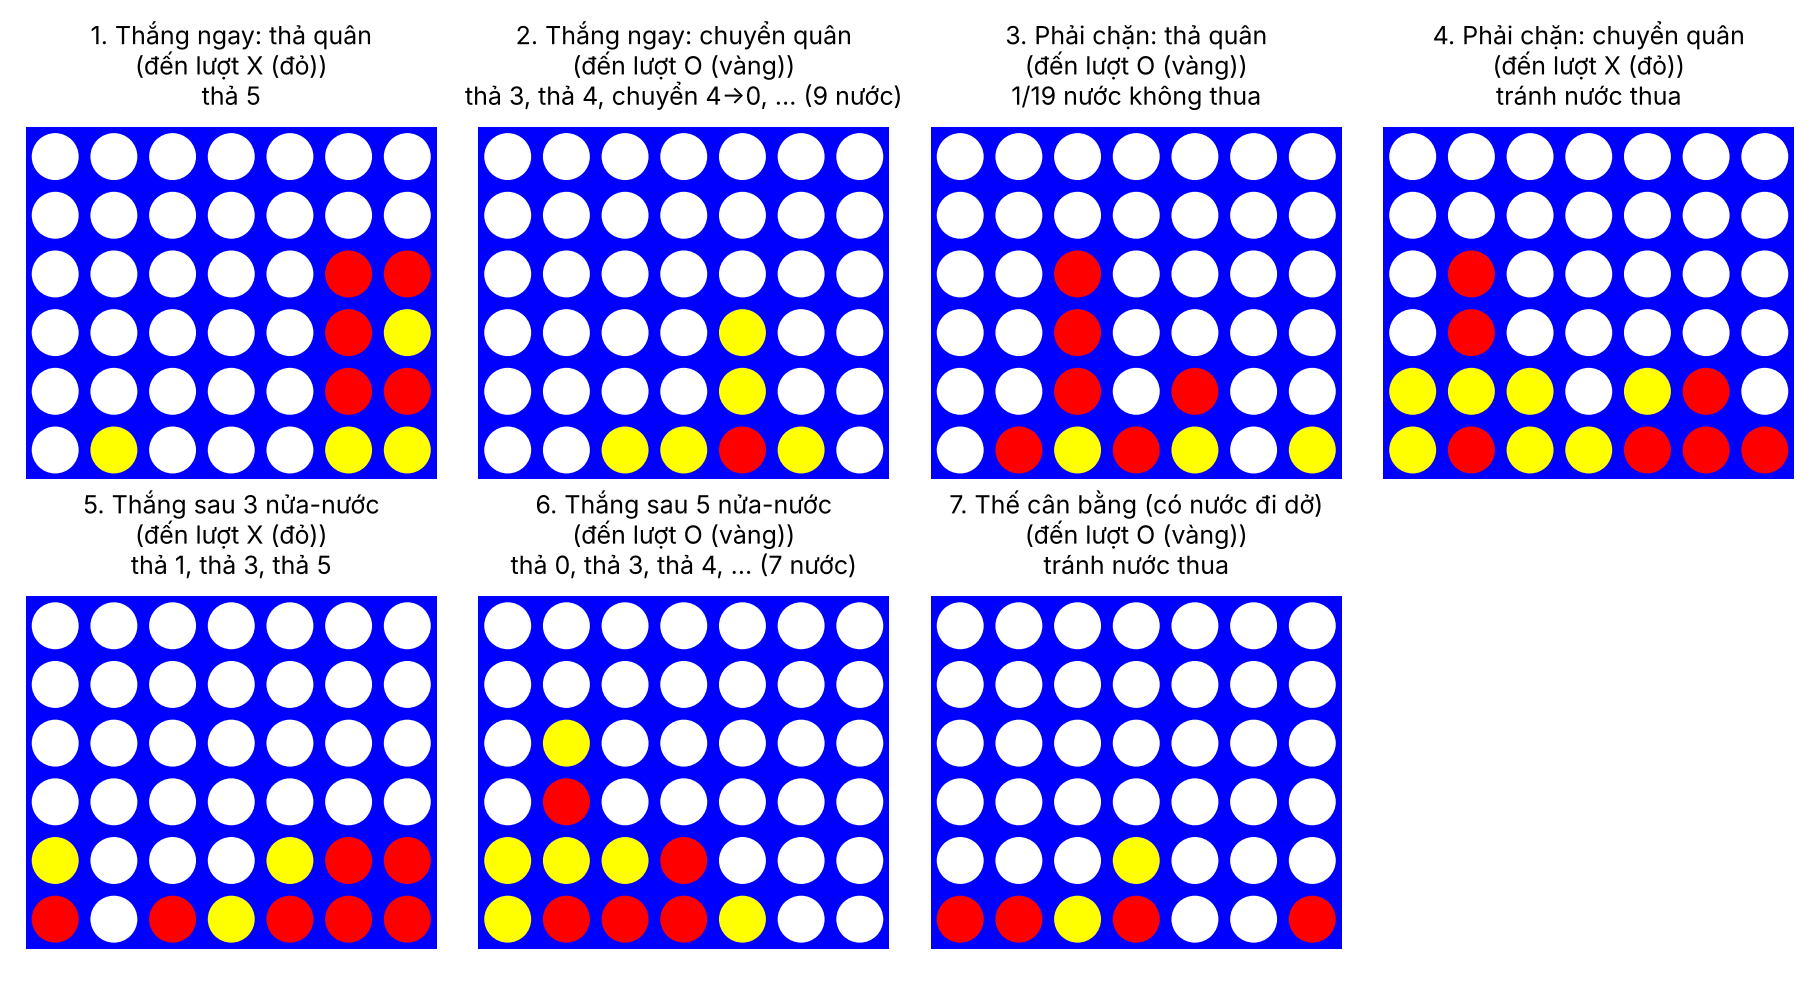

In [17]:
# Your code/ answer goes here.

# ---- Các bàn cờ thử nghiệm tự tạo (bàn chuẩn 6 x 7; 'X' = người 1 (đỏ), 'O' = người -1 (vàng), '.' = trống) ----
# Mỗi phần tử là (bàn cờ, người đến lượt): có nước chuyển quân nên KHÔNG suy ra được người đến lượt từ bàn cờ (quy ước 5).
TEST_BOARDS = {
    "1. Thắng ngay: thả quân": (board_from_strings([
        ".......", ".......", ".....XX", ".....XO", ".....XX", ".O...OO"]), 1),
    "2. Thắng ngay: chuyển quân": (board_from_strings([
        ".......", ".......", ".......", "....O..", "....O..", "..OOXO."]), -1),
    "3. Phải chặn: thả quân": (board_from_strings([
        ".......", ".......", "..X....", "..X....", "..X.X..", ".XOXO.O"]), -1),
    "4. Phải chặn: chuyển quân": (board_from_strings([
        ".......", ".......", ".X.....", ".X.....", "OOO.OX.", "OXOOXXX"]), 1),
    "5. Thắng sau 3 nửa-nước": (board_from_strings([
        ".......", ".......", ".......", ".......", "O...OXX", "X.XOXXX"]), 1),
    "6. Thắng sau 5 nửa-nước": (board_from_strings([
        ".......", ".......", ".O.....", ".X.....", "OOOX...", "OXXXO.."]), -1),
    "7. Thế cân bằng (có nước đi dở)": (board_from_strings([
        ".......", ".......", ".......", ".......", "...O...", "XXOX..X"]), -1),
}
TEST_NAMES = list(TEST_BOARDS)
mover_name = lambda p: "X (đỏ)" if p == 1 else "O (vàng)"

def fmt_action(a):
    return f"thả {a[1]}" if a[0] == "drop" else f"chuyển {a[1]}→{a[2]}"        # chuyển cột_lấy→cột_đặt

def fmt_set(S, total, value):
    S = sorted(S, key = lambda a: (a[0] != "drop",) + tuple(a[1:]))
    if value == 0: return f"{len(S)}/{total} nước không thua"
    return ", ".join(fmt_action(a) for a in S[:3]) + (f", … ({len(S)} nước)" if len(S) > 3 else "")

# ---- đáp án chuẩn: cùng thuật toán nhưng tìm SÂU hơn mọi thí nghiệm bên dưới; giá trị của TỪNG hành động tại gốc ----
REF_DEPTH = 9
reference = AlphaBetaPlayer(depth = REF_DEPTH, name = "tham chiếu")
TEST_INFO = {}
for name, (b, p) in TEST_BOARDS.items():
    vals = reference.action_values(b, p)
    best = max(vals.values())
    TEST_INFO[name] = dict(player = p, values = vals, value = round(best), total = len(vals),
                           keeps = {a for a, v in vals.items() if round(v) == round(best)},      # mọi nước giữ nguyên kết quả (thắng / không thua)
                           optimal = {a for a, v in vals.items() if v >= best - 1e-9})           # nước tốt nhất (thắng nhanh nhất)

def forced_win_plies(board, player, max_depth):
    """Số nửa-nước nhỏ nhất để `player` (đang đi) ép thắng: tìm sâu dần 1, 3, 5, ... cho tới khi giá trị gốc là thắng."""
    for d in range(1, max_depth + 1, 2):
        ab = AlphaBetaPlayer(depth = d)
        ab(board, player)
        if round(ab.last_value) == 1: return d
    return None

rows_theory = []
for name, (b, p) in TEST_BOARDS.items():
    info = TEST_INFO[name]
    info["win_plies"] = forced_win_plies(b, p, REF_DEPTH) if info["value"] == 1 else None
    rows_theory.append({"Bàn cờ": name, "Đến lượt": mover_name(p), "Số hành động": info["total"],
                        f"Giá trị (tầm nhìn {REF_DEPTH})": {1: "thắng", 0: "chưa phân thắng bại", -1: "thua"}[info["value"]],
                        "Thắng ép sau (nửa-nước)": info["win_plies"] if info["win_plies"] else "–",
                        "Nước giữ được kết quả": fmt_set(info["keeps"], info["total"], info["value"])})
print("Đáp án chuẩn (tính bởi tác tử tìm sâu %d nửa-nước):" % REF_DEPTH)
display(pd.DataFrame(rows_theory).set_index("Bàn cờ"))

# ---- Tác tử Alpha-Beta ở các độ sâu khác nhau có chọn đúng không? ----
#   ✓ = chọn nước giữ được kết quả VÀ chắc chắn (mọi nước ngang điểm ở đầu bảng đều đúng, kể cả khi hòa thì chọn nước nào);
#   ? = chọn đúng nhưng chưa chắc (còn nước sai ngang điểm; đúng nhờ thứ tự duyệt "cột giữa trước"); ✗ = chọn sai.
DEPTHS_TEST = [1, 2, 3, 4, 5, 6, 8]
CHOSEN = {}
for name, (b, p) in TEST_BOARDS.items():
    keeps = TEST_INFO[name]["keeps"]
    for d in DEPTHS_TEST:
        ab = AlphaBetaPlayer(depth = d)
        t0 = time.perf_counter()
        a = ab(b, p)
        dt = time.perf_counter() - t0
        vals_d = AlphaBetaPlayer(depth = d).action_values(b, p)
        top = max(vals_d.values())
        certain = all(act in keeps for act, v in vals_d.items() if v >= top - 1e-9)
        CHOSEN[(name, d)] = dict(action = a, status = "✗" if a not in keeps else ("✓" if certain else "?"), nodes = ab.nodes, time = dt, value = ab.last_value)

def min_certain_depth(name):
    """Độ sâu nhỏ nhất mà từ đó trở đi (trong các độ sâu đã thử) tác tử luôn chọn đúng và chắc chắn (✓); None nếu độ sâu lớn nhất vẫn chưa."""
    ok = [CHOSEN[(name, d)]["status"] == "✓" for d in DEPTHS_TEST]
    for i, d in enumerate(DEPTHS_TEST):
        if all(ok[i:]): return d
    return None

rows_out = []
for name, (b, p) in TEST_BOARDS.items():
    row = {"Bàn cờ": name}
    for d in DEPTHS_TEST:
        c = CHOSEN[(name, d)]
        row[f"d={d}"] = f"{fmt_action(c['action'])} {c['status']}"
    md = min_certain_depth(name)
    row["Độ sâu tối thiểu để chắc chắn đúng"] = md if md else f"> {DEPTHS_TEST[-1]}"
    rows_out.append(row)
manual_table = pd.DataFrame(rows_out).set_index("Bàn cờ")
display(manual_table)
visualize_grid([b for b, p in TEST_BOARDS.values()],
               [f"{n}\n(đến lượt {mover_name(p)})\n" + (fmt_set(TEST_INFO[n]['keeps'], TEST_INFO[n]['total'], TEST_INFO[n]['value']) if TEST_INFO[n]['value'] != 0 or len(TEST_INFO[n]['keeps']) <= 3 else 'tránh nước thua')
                for n, (b, p) in TEST_BOARDS.items()], ncols = 4)

In [18]:
n = len(TEST_NAMES)
st = lambda name, d: CHOSEN[(name, d)]["status"]
d_all = [d for d in DEPTHS_TEST if all(st(nm, d) == "✓" for nm in TEST_NAMES)]
win_boards = [nm for nm in TEST_NAMES if TEST_INFO[nm]["win_plies"]]
mins = {nm: min_certain_depth(nm) for nm in TEST_NAMES}
guess = [nm for nm in TEST_NAMES for d in DEPTHS_TEST if st(nm, d) == "?"]
wrong = [(nm, d) for nm in TEST_NAMES for d in DEPTHS_TEST if st(nm, d) == "✗"]
dmax = DEPTHS_TEST[-1]
lines = []
for nm in TEST_NAMES:
    info = TEST_INFO[nm]
    if info["win_plies"]:
        shallow = any(st(nm, d) != "✓" for d in DEPTHS_TEST)
        lines.append(f"* **{nm}** – thắng ép sau {info['win_plies']} nửa-nước: tác tử chọn đúng và chắc chắn từ độ sâu {mins[nm] if mins[nm] else '> ' + str(DEPTHS_TEST[-1])}" + ("; với độ sâu nhỏ hơn nó chưa thấy đòn thắng nên nước chọn (nếu đúng) chỉ là may mắn (dấu ?)." if shallow else "."))
    elif info["value"] == 0 and len(info["keeps"]) < info["total"]:
        kinds = {a[0] for a in info["keeps"]}
        kind = "chỉ nước chuyển quân" if kinds == {"move"} else ("chỉ nước thả quân" if kinds == {"drop"} else "cả thả quân lẫn chuyển quân")
        n_drop_lose = sum(1 for a, v in info["values"].items() if a[0] == "drop" and round(v) == -1)
        n_drop = sum(1 for a in info["values"] if a[0] == "drop")
        lines.append(f"* **{nm}** – chỉ {len(info['keeps'])}/{info['total']} hành động không thua ({kind}; {n_drop_lose}/{n_drop} nước thả quân thua): tác tử chắc chắn tránh được các nước thua từ độ sâu {mins[nm] if mins[nm] else '> ' + str(DEPTHS_TEST[-1])}.")
    elif info["value"] == -1: lines.append(f"* **{nm}** – đã thua trong tầm nhìn {REF_DEPTH}: mọi nước đều có giá trị −1 nên không có nước \"đúng\".")
display(Markdown(f"""
**Nhận xét.** Giá trị chuẩn của mỗi hành động được tính bằng cùng thuật toán nhưng tìm sâu {REF_DEPTH} nửa-nước (sâu hơn mọi độ sâu thử bên dưới); giá trị "thắng/thua" chỉ có khi chuỗi thắng/thua nằm trong tầm nhìn, còn lại là 0 (chưa biết).
{chr(10).join(lines)}

* Ở độ sâu {dmax} tác tử chọn **chắc chắn đúng ở {sum(st(nm, dmax) == '✓' for nm in TEST_NAMES)}/{n} bàn**{'; từ độ sâu ' + str(d_all[0]) + ' trở đi cả ' + str(n) + ' bàn đều đúng và chắc chắn' if d_all else ''}. Dấu "?" xuất hiện {len(guess)} lần: tác tử chọn đúng nhưng còn nước sai ngang điểm — kết quả đúng là nhờ thứ tự duyệt "cột giữa trước" chứ không phải vì đã nhìn thấy; vì vậy cần phân biệt "chọn đúng" với "chọn đúng một cách chắc chắn".
* Bàn **"Thắng ngay: chuyển quân"** cho thấy tính chất riêng của "Mean" Connect 4: đòn thắng nảy sinh khi lấy quân đáy của đối thủ làm các quân phía trên *rơi xuống* và tạo thành hàng 4. Một tác tử chỉ nghĩ đến thả quân sẽ bỏ lỡ đòn này; tác tử của ta duyệt cả hai loại hành động nên thấy ngay.
"""))


**Nhận xét.** Giá trị chuẩn của mỗi hành động được tính bằng cùng thuật toán nhưng tìm sâu 9 nửa-nước (sâu hơn mọi độ sâu thử bên dưới); giá trị "thắng/thua" chỉ có khi chuỗi thắng/thua nằm trong tầm nhìn, còn lại là 0 (chưa biết).
* **1. Thắng ngay: thả quân** – thắng ép sau 1 nửa-nước: tác tử chọn đúng và chắc chắn từ độ sâu 1.
* **2. Thắng ngay: chuyển quân** – thắng ép sau 1 nửa-nước: tác tử chọn đúng và chắc chắn từ độ sâu 1.
* **3. Phải chặn: thả quân** – chỉ 1/19 hành động không thua (chỉ nước thả quân; 6/7 nước thả quân thua): tác tử chắc chắn tránh được các nước thua từ độ sâu 2.
* **4. Phải chặn: chuyển quân** – chỉ 4/25 hành động không thua (chỉ nước chuyển quân; 7/7 nước thả quân thua): tác tử chắc chắn tránh được các nước thua từ độ sâu 2.
* **5. Thắng sau 3 nửa-nước** – thắng ép sau 3 nửa-nước: tác tử chọn đúng và chắc chắn từ độ sâu 3; với độ sâu nhỏ hơn nó chưa thấy đòn thắng nên nước chọn (nếu đúng) chỉ là may mắn (dấu ?).
* **6. Thắng sau 5 nửa-nước** – thắng ép sau 5 nửa-nước: tác tử chọn đúng và chắc chắn từ độ sâu 5; với độ sâu nhỏ hơn nó chưa thấy đòn thắng nên nước chọn (nếu đúng) chỉ là may mắn (dấu ?).
* **7. Thế cân bằng (có nước đi dở)** – chỉ 27/32 hành động không thua (cả thả quân lẫn chuyển quân; 0/7 nước thả quân thua): tác tử chắc chắn tránh được các nước thua từ độ sâu 2.

* Ở độ sâu 8 tác tử chọn **chắc chắn đúng ở 7/7 bàn**; từ độ sâu 5 trở đi cả 7 bàn đều đúng và chắc chắn. Dấu "?" xuất hiện 7 lần: tác tử chọn đúng nhưng còn nước sai ngang điểm — kết quả đúng là nhờ thứ tự duyệt "cột giữa trước" chứ không phải vì đã nhìn thấy; vì vậy cần phân biệt "chọn đúng" với "chọn đúng một cách chắc chắn".
* Bàn **"Thắng ngay: chuyển quân"** cho thấy tính chất riêng của "Mean" Connect 4: đòn thắng nảy sinh khi lấy quân đáy của đối thủ làm các quân phía trên *rơi xuống* và tạo thành hàng 4. Một tác tử chỉ nghĩ đến thả quân sẽ bỏ lỡ đòn này; tác tử của ta duyệt cả hai loại hành động nên thấy ngay.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,Số cột,d=4: thời gian TB (ms),d=4: số nút TB,d=6: thời gian TB (ms),d=6: số nút TB,d=8: thời gian TB (ms),d=8: số nút TB
0,4,1.2,172,6.0,968,17.1,"4,198"
1,5,1.2,325,8.1,"2,360",53.2,"12,530"
2,6,1.5,395,12.8,"3,190",84.2,"18,864"
3,7,2.9,726,29.6,"6,832",218.5,"46,798"
4,8,4.9,"1,183",54.3,"12,108",477.1,"89,392"
5,9,3.6,968,40.8,"9,462",370.4,"75,712"
6,10,6.8,"1,623",100.7,"23,120",1077.0,"202,149"


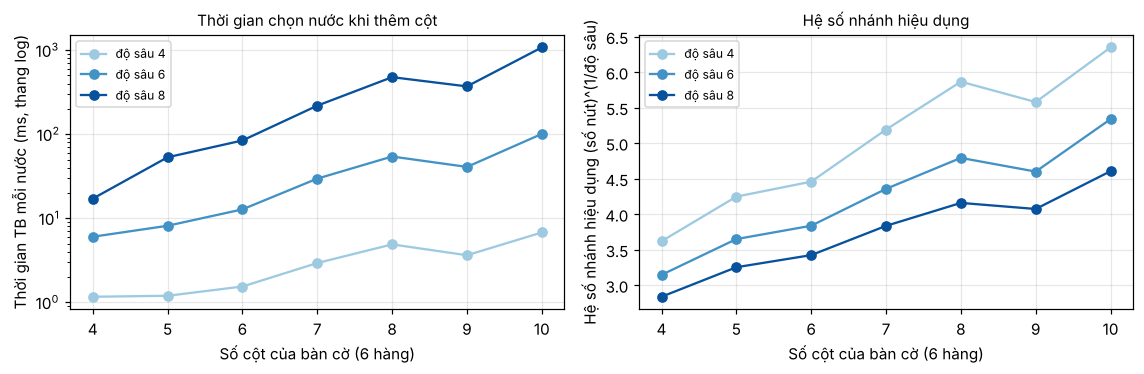

In [19]:
# Your code/ answer goes here.

# ---- Thời gian chọn một nước đi khi tăng số cột (6 hàng): bắt đầu từ 4 cột ----
# Cây trò chơi vô hạn nên ta đo với độ sâu CỐ ĐỊNH; mỗi cỡ bàn đo trên bàn rỗng và vài thế cờ sau 6 nước đi ngẫu nhiên.
SIZE_COLS, SIZE_DEPTHS, SIZE_POS = [4, 5, 6, 7, 8, 9, 10], [4, 6, 8], 3

def random_positions(shape, n, plies, seed):
    """n thế cờ sau `plies` nước đi ngẫu nhiên (thả quân hoặc chuyển quân) từ bàn rỗng; trả về [(bàn cờ, người đến lượt)]."""
    rng = random.Random(seed)
    out = []
    while len(out) < n:
        b, p, ok = initial_state(shape), 1, True
        for _ in range(plies):
            acts = actions(b, p)
            if not acts: ok = False; break                         # ván đã kết thúc trước khi đủ `plies` nước: bỏ, thử lại
            b = result(b, p, acts[rng.randrange(len(acts))]); p = -p
        if ok and not terminal(b): out.append((b, p))
    return out

size_data, rows_out = {}, []
for cols in SIZE_COLS:
    shape = (6, cols)
    positions = [(initial_state(shape), 1)] + random_positions(shape, SIZE_POS, 6, seed = cols)
    row = {"Số cột": cols}
    for d in SIZE_DEPTHS:
        ts, nodes = [], []
        for b, p in positions:
            ab = AlphaBetaPlayer(depth = d)
            t0 = time.perf_counter(); ab(b, p); ts.append(time.perf_counter() - t0); nodes.append(ab.nodes)
        size_data[(cols, d)] = (1000 * float(np.mean(ts)), float(np.mean(nodes)))
        row[f"d={d}: thời gian TB (ms)"] = round(1000 * float(np.mean(ts)), 1)
        row[f"d={d}: số nút TB"] = f"{np.mean(nodes):,.0f}"
    rows_out.append(row)
size_table = pd.DataFrame(rows_out)
display(size_table)

fig, ax = plt.subplots(1, 2, figsize = (10.5, 3.5), dpi = 110)
for d, color in zip(SIZE_DEPTHS, ("#9ecae1", "#4292c6", "#08519c")):
    ax[0].plot(SIZE_COLS, [size_data[(c, d)][0] for c in SIZE_COLS], "o-", color = color, label = f"độ sâu {d}")
    ax[1].plot(SIZE_COLS, [size_data[(c, d)][1] ** (1 / d) for c in SIZE_COLS], "o-", color = color, label = f"độ sâu {d}")
ax[0].set_yscale("log"); ax[0].set_xlabel("Số cột của bàn cờ (6 hàng)"); ax[0].set_ylabel("Thời gian TB mỗi nước (ms, thang log)"); ax[0].set_title("Thời gian chọn nước khi thêm cột", fontsize = 10)
ax[1].set_xlabel("Số cột của bàn cờ (6 hàng)"); ax[1].set_ylabel("Hệ số nhánh hiệu dụng (số nút)^(1/độ sâu)"); ax[1].set_title("Hệ số nhánh hiệu dụng", fontsize = 10)
for a_ in ax: a_.legend(fontsize = 8); a_.grid(alpha = .3)
plt.tight_layout(); plt.show()

In [20]:
def per_col(d):
    t = [size_data[(c, d)][0] for c in SIZE_COLS]
    return (t[-1] / t[0]) ** (1 / (len(t) - 1))
c0, c1 = SIZE_COLS[0], SIZE_COLS[-1]
dd = SIZE_DEPTHS
rate = np.mean([size_data[(c, d)][1] / (size_data[(c, d)][0] / 1000) for c in SIZE_COLS for d in dd if size_data[(c, d)][0] > 5])
display(Markdown(f"""
**Nhận xét.**
* **Thời gian tăng theo số cột:** mỗi cột thêm vào nhân thời gian lên ≈ ×{per_col(dd[0]):.2f} (độ sâu {dd[0]}), ×{per_col(dd[1]):.2f} (độ sâu {dd[1]}) và ×{per_col(dd[2]):.2f} (độ sâu {dd[2]}) – độ sâu càng lớn thì mỗi cột thêm càng đắt, vì số nút ≈ b^d với hệ số nhánh b tăng theo số cột (biểu đồ phải: hệ số nhánh hiệu dụng ở độ sâu {dd[2]} tăng từ {size_data[(c0, dd[2])][1] ** (1 / dd[2]):.1f} lên {size_data[(c1, dd[2])][1] ** (1 / dd[2]):.1f}).
* **Giá cho độ sâu:** ở {c1} cột, độ sâu {dd[0]} / {dd[1]} / {dd[2]} cần {size_data[(c1, dd[0])][0]:.1f} / {size_data[(c1, dd[1])][0]:.0f} / {size_data[(c1, dd[2])][0]:.0f} ms. Mỗi 2 nửa-nước thêm nhân thời gian lên ≈ ×{(size_data[(c1, dd[2])][0] / size_data[(c1, dd[0])][0]) ** (1 / 2):.1f}.
* Khác Connect 4 thường (tìm tới cuối ván, chi phí tăng mũ theo số ô), ở đây **không có kết thúc để tìm tới**: cây vô hạn do chu trình của nước chuyển quân, nên chi phí được kiểm soát bởi độ sâu chứ không phải kích thước bàn; kích thước bàn chỉ quyết định hệ số nhánh. Tốc độ xử lý trung bình ≈ {rate / 1e6:.2f} triệu nút/giây (Python + bitboard).
* Hệ quả thực tế: để mỗi nước dưới ≈ 1 giây, bàn {c1} cột chỉ tìm được tới độ sâu {max(d for d in dd if size_data[(c1, d)][0] < 1000) if any(size_data[(c1, d)][0] < 1000 for d in dd) else '< ' + str(dd[0])} trong ba mức đã thử; vì tìm kiếm chỉ nhìn thấy kết quả *trong tầm nhìn* nên với độ sâu nhỏ tác tử "mù" về các kế hoạch dài – lý do cần thêm heuristic (Task 4).
"""))


**Nhận xét.**
* **Thời gian tăng theo số cột:** mỗi cột thêm vào nhân thời gian lên ≈ ×1.34 (độ sâu 4), ×1.60 (độ sâu 6) và ×1.99 (độ sâu 8) – độ sâu càng lớn thì mỗi cột thêm càng đắt, vì số nút ≈ b^d với hệ số nhánh b tăng theo số cột (biểu đồ phải: hệ số nhánh hiệu dụng ở độ sâu 8 tăng từ 2.8 lên 4.6).
* **Giá cho độ sâu:** ở 10 cột, độ sâu 4 / 6 / 8 cần 6.8 / 101 / 1077 ms. Mỗi 2 nửa-nước thêm nhân thời gian lên ≈ ×12.6.
* Khác Connect 4 thường (tìm tới cuối ván, chi phí tăng mũ theo số ô), ở đây **không có kết thúc để tìm tới**: cây vô hạn do chu trình của nước chuyển quân, nên chi phí được kiểm soát bởi độ sâu chứ không phải kích thước bàn; kích thước bàn chỉ quyết định hệ số nhánh. Tốc độ xử lý trung bình ≈ 0.22 triệu nút/giây (Python + bitboard).
* Hệ quả thực tế: để mỗi nước dưới ≈ 1 giây, bàn 10 cột chỉ tìm được tới độ sâu 6 trong ba mức đã thử; vì tìm kiếm chỉ nhìn thấy kết quả *trong tầm nhìn* nên với độ sâu nhỏ tác tử "mù" về các kế hoạch dài – lý do cần thêm heuristic (Task 4).


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

,Chiến lược duyệt hành động,7 bàn thử: tổng số nút,7 bàn thử: thời gian (s),10 thế cờ giữa ván: tổng số nút,10 thế cờ giữa ván: thời gian (s)
0,Trái → phải (thuần),"668,726",3.53,"394,308",2.04
1,Từ biên vào giữa (edges),"1,719,768",6.10,"457,426",2.92
2,Từ giữa ra (center),"350,720",2.01,"263,456",1.36
3,"center, chuyển quân trước thả quân","3,538,007",12.95,"365,672",1.93
4,center + xét nước thắng ngay trước,"110,755",0.77,"136,137",1.16
5,center + thắng ngay + bảng chuyển vị,"61,343",0.31,"72,060",0.41


Bàn 6 x 7 rỗng, độ sâu 8: không dùng đối xứng 28,371 nút (0.09 s); dùng đối xứng ở gốc 23,467 nút (0.06 s).
(Mọi chiến lược trả về cùng giá trị Minimax trên cả 17 thế cờ – đã kiểm tra bằng assert.)


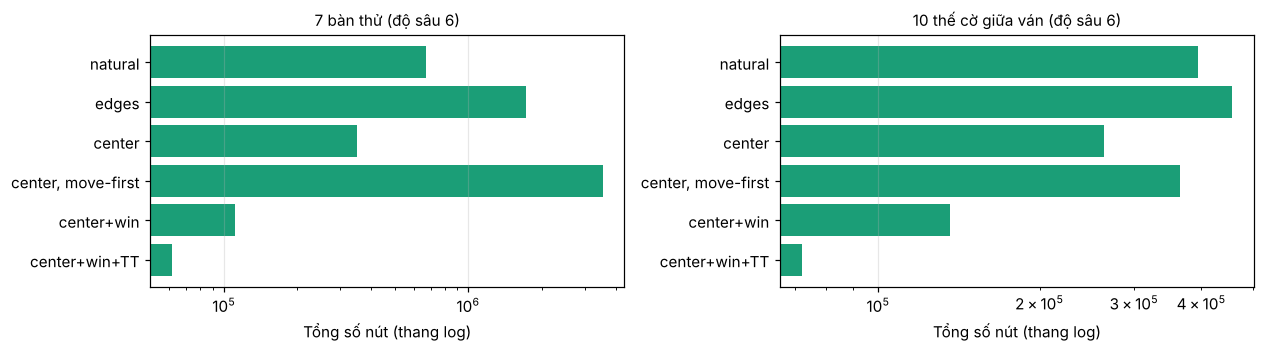

In [21]:
# Your code/ answer goes here.

# ---- Thứ tự duyệt hành động: ảnh hưởng tới số nút và thời gian (độ sâu cố định, cùng một giá trị Minimax) ----
ORDER_DEPTH, ORDER_MID = 6, 10
ORDER_VARIANTS = [
    ("Trái → phải (thuần)",                                dict(ordering = "natural", wins_first = False, use_tt = False)),
    ("Từ biên vào giữa (edges)",                           dict(ordering = "edges", wins_first = False, use_tt = False)),
    ("Từ giữa ra (center)",                                dict(ordering = "center", wins_first = False, use_tt = False)),
    ("center, chuyển quân trước thả quân",                  dict(ordering = "center", wins_first = False, use_tt = False, drops_first = False)),
    ("center + xét nước thắng ngay trước",                  dict(ordering = "center", wins_first = True, use_tt = False)),
    ("center + thắng ngay + bảng chuyển vị",                dict(ordering = "center", wins_first = True, use_tt = True)),
]
MID_POS = random_positions((6, 7), ORDER_MID, 8, seed = 5)
SETS = {"7 bàn thử": list(TEST_BOARDS.values()), f"{ORDER_MID} thế cờ giữa ván": MID_POS}
ref_values, order_data, rows_out = {}, {}, []
for label, kw in ORDER_VARIANTS:
    row = {"Chiến lược duyệt hành động": label}
    for set_name, positions in SETS.items():
        tot_n = tot_t = 0
        for i, (b, p) in enumerate(positions):
            ab = AlphaBetaPlayer(depth = ORDER_DEPTH, symmetry_root = False, **kw)
            t0 = time.perf_counter(); ab(b, p); tot_t += time.perf_counter() - t0; tot_n += ab.nodes
            ref_values.setdefault((set_name, i), round(ab.last_value))
            assert round(ab.last_value) == ref_values[(set_name, i)], (label, set_name, i)          # mọi chiến lược cho cùng giá trị Minimax
        order_data[(label, set_name)] = (tot_n, tot_t)
        row[f"{set_name}: tổng số nút"] = f"{tot_n:,}"; row[f"{set_name}: thời gian (s)"] = round(tot_t, 2)
    rows_out.append(row)
order_table = pd.DataFrame(rows_out)
display(order_table)

# bàn rỗng: đối xứng trái-phải ở gốc
sym_rows = []
for sym in (False, True):
    ab = AlphaBetaPlayer(depth = ORDER_DEPTH + 2, symmetry_root = sym)
    t0 = time.perf_counter(); ab(initial_state(), 1); sym_rows.append((sym, ab.nodes, time.perf_counter() - t0))
print(f"Bàn 6 x 7 rỗng, độ sâu {ORDER_DEPTH + 2}: không dùng đối xứng {sym_rows[0][1]:,} nút ({sym_rows[0][2]:.2f} s); dùng đối xứng ở gốc {sym_rows[1][1]:,} nút ({sym_rows[1][2]:.2f} s).")
print(f"(Mọi chiến lược trả về cùng giá trị Minimax trên cả {sum(len(v) for v in SETS.values())} thế cờ – đã kiểm tra bằng assert.)")

short = ["natural", "edges", "center", "center, move-first", "center+win", "center+win+TT"]
fig, ax = plt.subplots(1, len(SETS), figsize = (5.8 * len(SETS), 3.3), dpi = 110)
for a_, set_name in zip(np.atleast_1d(ax), SETS):
    a_.barh(short[::-1], [order_data[(l, set_name)][0] for l, _ in ORDER_VARIANTS][::-1], color = "#1b9e77"); a_.set_xscale("log")
    a_.set_xlabel("Tổng số nút (thang log)"); a_.set_title(f"{set_name} (độ sâu {ORDER_DEPTH})", fontsize = 10); a_.grid(axis = "x", alpha = .3)
plt.tight_layout(); plt.show()

In [22]:
L = [l for l, _ in ORDER_VARIANTS]
sn = list(SETS)
n_ = lambda l, k: order_data[(l, sn[k])][0]
t_ = lambda l, k: order_data[(l, sn[k])][1]
def change(a, b):
    r = b / a
    return f"giảm {a / b:.1f} lần" if r < 0.9 else (f"tăng {r:.1f} lần" if r > 1.1 else "gần như không đổi")
cw = [[sum(1 for w in MeanGeometry.get(6, 7).windows if w & (1 << (c * 7 + k))) for c in range(7)] for k in range(6)]
display(Markdown(f"""
**Chiến lược sắp xếp.** Alpha-Beta cắt được nhiều nhất khi **hành động tốt được xét trước**. Ba gợi ý đơn giản: (1) *từ giữa ra* – các ô ở giữa bàn nằm trong tới {max(max(r) for r in cw)} "cửa sổ 4 ô" (ô góc chỉ {min(min(r) for r in cw)}) nên thả quân vào cột giữa thường tốt: thứ tự 3, 2, 4, 1, 5, 0, 6; (2) *xét nước thắng ngay trước* – nước thắng cho giá trị tối đa nên cắt ngay mọi nhánh còn lại; (3) *bảng chuyển vị* – các dãy nước (kể cả cặp chuyển quân rồi chuyển lại) dẫn tới cùng một thế cờ chỉ phải tính một lần. Riêng với "Mean" Connect 4 ta còn thử thứ tự *loại hành động*: thả quân trước hay chuyển quân trước.

**Kết quả đo được** (độ sâu {ORDER_DEPTH}; bảng và biểu đồ trên; mọi chiến lược cho cùng giá trị Minimax):
* **Chỉ đổi thứ tự cột.** Trên {sn[1]}, tổng số nút là {n_(L[0], 1):,} (trái → phải), {n_(L[2], 1):,} (từ giữa ra) và {n_(L[1], 1):,} (từ biên vào): từ giữa ra {change(n_(L[0], 1), n_(L[2], 1))} so với trái → phải, còn từ biên vào {change(n_(L[0], 1), n_(L[1], 1))}. Trên {sn[0]}: {n_(L[0], 0):,} / {n_(L[2], 0):,} / {n_(L[1], 0):,} (cùng thứ tự các cột như trên).
* **Loại hành động:** đưa *chuyển quân* lên trước thả quân {change(n_(L[2], 1), n_(L[3], 1))} nút trên {sn[1]} ({n_(L[2], 1):,} → {n_(L[3], 1):,}) và {change(n_(L[2], 0), n_(L[3], 0))} trên {sn[0]}.
* **Xét nước thắng ngay trước** làm số nút {change(n_(L[2], 1), n_(L[4], 1))} trên {sn[1]} ({n_(L[2], 1):,} → {n_(L[4], 1):,}); riêng ở {sn[0]} (có bàn \"thắng ngay\") {change(n_(L[2], 0), n_(L[4], 0))}.
* **Bảng chuyển vị** tiếp tục {change(n_(L[4], 1), n_(L[5], 1))} ({n_(L[4], 1):,} → {n_(L[5], 1):,} nút, {t_(L[4], 1):.2f} s → {t_(L[5], 1):.2f} s): tổng cộng nhanh hơn thuật toán thuần {t_(L[0], 1) / max(t_(L[5], 1), 1e-9):.0f} lần về thời gian và {n_(L[0], 1) / n_(L[5], 1):.0f} lần về số nút trên {sn[1]}. Đối xứng trái–phải ở gốc chỉ có lợi ở bàn rỗng ({sym_rows[0][1]:,} → {sym_rows[1][1]:,} nút).
* **Lưu ý:** thứ tự là một *heuristic*, hiệu quả phụ thuộc thế cờ (xem chênh lệch giữa hai bộ thế cờ); riêng bảng chuyển vị và xét nước thắng ngay không làm đổi kết quả mà chỉ bớt tính toán.
"""))


**Chiến lược sắp xếp.** Alpha-Beta cắt được nhiều nhất khi **hành động tốt được xét trước**. Ba gợi ý đơn giản: (1) *từ giữa ra* – các ô ở giữa bàn nằm trong tới 13 "cửa sổ 4 ô" (ô góc chỉ 3) nên thả quân vào cột giữa thường tốt: thứ tự 3, 2, 4, 1, 5, 0, 6; (2) *xét nước thắng ngay trước* – nước thắng cho giá trị tối đa nên cắt ngay mọi nhánh còn lại; (3) *bảng chuyển vị* – các dãy nước (kể cả cặp chuyển quân rồi chuyển lại) dẫn tới cùng một thế cờ chỉ phải tính một lần. Riêng với "Mean" Connect 4 ta còn thử thứ tự *loại hành động*: thả quân trước hay chuyển quân trước.

**Kết quả đo được** (độ sâu 6; bảng và biểu đồ trên; mọi chiến lược cho cùng giá trị Minimax):
* **Chỉ đổi thứ tự cột.** Trên 10 thế cờ giữa ván, tổng số nút là 394,308 (trái → phải), 263,456 (từ giữa ra) và 457,426 (từ biên vào): từ giữa ra giảm 1.5 lần so với trái → phải, còn từ biên vào tăng 1.2 lần. Trên 7 bàn thử: 668,726 / 350,720 / 1,719,768 (cùng thứ tự các cột như trên).
* **Loại hành động:** đưa *chuyển quân* lên trước thả quân tăng 1.4 lần nút trên 10 thế cờ giữa ván (263,456 → 365,672) và tăng 10.1 lần trên 7 bàn thử.
* **Xét nước thắng ngay trước** làm số nút giảm 1.9 lần trên 10 thế cờ giữa ván (263,456 → 136,137); riêng ở 7 bàn thử (có bàn "thắng ngay") giảm 3.2 lần.
* **Bảng chuyển vị** tiếp tục giảm 1.9 lần (136,137 → 72,060 nút, 1.16 s → 0.41 s): tổng cộng nhanh hơn thuật toán thuần 5 lần về thời gian và 5 lần về số nút trên 10 thế cờ giữa ván. Đối xứng trái–phải ở gốc chỉ có lợi ở bàn rỗng (28,371 → 23,467 nút).
* **Lưu ý:** thứ tự là một *heuristic*, hiệu quả phụ thuộc thế cờ (xem chênh lệch giữa hai bộ thế cờ); riêng bảng chuyển vị và xét nước thắng ngay không làm đổi kết quả mà chỉ bớt tính toán.


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [23]:
# Your code/ answer goes here.

# ---- Nước đầu tiên trên bàn rỗng 6 x 7: chi phí theo độ sâu, rồi các cách giảm chi phí ----
FIRST_DEPTHS = [4, 6, 8, 10]
rows_out, first_cost = [], {}
for d in FIRST_DEPTHS:
    row = {"Độ sâu": d}
    for sym in (False, True):
        ab = AlphaBetaPlayer(depth = d, symmetry_root = sym)
        t0 = time.perf_counter(); a = ab(initial_state(), 1); dt = time.perf_counter() - t0
        first_cost[(d, sym)] = (ab.nodes, dt, a, ab.last_value)
        row[("Không dùng đối xứng" if not sym else "Dùng đối xứng ở gốc") + ": số nút"] = f"{ab.nodes:,}"
        row[("Không dùng đối xứng" if not sym else "Dùng đối xứng ở gốc") + ": thời gian (s)"] = round(dt, 3)
    row["Nước chọn"] = fmt_action(first_cost[(d, True)][2]); row["Giá trị"] = f"{first_cost[(d, True)][3]:+.2f}"
    rows_out.append(row)
first_table = pd.DataFrame(rows_out)
display(first_table)

class IterativeDeepeningPlayer:
    """Tìm kiếm sâu dần: chạy AlphaBetaPlayer với độ sâu 1, 2, 3, ... cho tới khi hết `time_limit` giây hoặc đã chứng minh thắng/thua;
    trả về nước đi của lần lặp HOÀN CHỈNH cuối cùng, nên luôn có câu trả lời đúng hạn."""
    def __init__(self, time_limit = 1.0, max_depth = 40, **kw):
        self.time_limit, self.max_depth, self.kw = time_limit, max_depth, kw
        self.depth_reached, self.last_value, self.name = 0, None, f"Sâu dần ({time_limit:g} s)"

    def __call__(self, board, player = None):
        deadline = time.perf_counter() + self.time_limit
        best = None
        for d in range(1, self.max_depth + 1):
            ab = AlphaBetaPlayer(depth = d, **self.kw)
            ab.deadline = deadline
            try: a = ab(board, player)
            except AlphaBetaPlayer.TimeUp: break
            best, self.depth_reached, self.last_value = a, d, ab.last_value
            if abs(ab.last_value) >= 1: break                      # đã chứng minh thắng/thua trong tầm nhìn
        return best

OPENING_BOOK = {}
for d in FIRST_DEPTHS[-1:]:
    OPENING_BOOK[initial_state().tobytes()] = first_cost[(d, True)][2]          # nước tốt nhất do tìm kiếm sâu nhất tính SẴN (offline)

class BookPlayer:
    """Sách khai cuộc: nếu bàn rỗng thì tra sẵn nước đi; còn lại gọi tác tử `fallback`."""
    def __init__(self, fallback): self.fallback, self.name = fallback, "Sách khai cuộc + " + fallback.name
    def __call__(self, board, player = None):
        return OPENING_BOOK.get(board.tobytes(), None) or self.fallback(board, player)

d_ref = FIRST_DEPTHS[-2] if len(FIRST_DEPTHS) > 1 else FIRST_DEPTHS[-1]
rows_out, first_methods = [], {}
cases = [(f"Alpha-Beta độ sâu {d_ref}, không đối xứng", AlphaBetaPlayer(depth = d_ref, symmetry_root = False)),
         (f"Alpha-Beta độ sâu {d_ref}, đối xứng ở gốc", AlphaBetaPlayer(depth = d_ref, symmetry_root = True))]
for tl in [0.5, 2.0]:
    cases.append((f"Tìm kiếm sâu dần, giới hạn {tl:g} s", IterativeDeepeningPlayer(tl)))
cases.append(("Sách khai cuộc (tra sẵn)", BookPlayer(AlphaBetaPlayer(depth = d_ref))))
for label, agent in cases:
    t0 = time.perf_counter(); a = agent(initial_state(), 1); dt = time.perf_counter() - t0
    first_methods[label] = (dt, a, getattr(agent, "depth_reached", None))
    rows_out.append({"Cách làm": label, "Thời gian (s)": round(dt, 3), "Độ sâu đạt được": getattr(agent, "depth_reached", None) or (agent.depth if hasattr(agent, "depth") else "–"), "Nước đầu": fmt_action(a)})
display(pd.DataFrame(rows_out))

,Độ sâu,Không dùng đối xứng: số nút,Không dùng đối xứng: thời gian (s),Dùng đối xứng ở gốc: số nút,Dùng đối xứng ở gốc: thời gian (s),Nước chọn,Giá trị
0,4,398,0.002,326,0.001,thả 3,+0.00
1,6,"4,121",0.017,"3,421",0.014,thả 3,+0.00
2,8,"28,371",0.136,"23,467",0.079,thả 3,+0.00
3,10,"143,447",0.474,"118,822",0.353,thả 3,+0.00


,Cách làm,Thời gian (s),Độ sâu đạt được,Nước đầu
0,"Alpha-Beta độ sâu 8, không đối xứng",0.077,8,thả 3
1,"Alpha-Beta độ sâu 8, đối xứng ở gốc",0.058,8,thả 3
2,"Tìm kiếm sâu dần, giới hạn 0.5 s",0.501,9,thả 3
3,"Tìm kiếm sâu dần, giới hạn 2 s",2.001,11,thả 3
4,Sách khai cuộc (tra sẵn),0.000,–,thả 3


In [24]:
d_lo, d_hi = FIRST_DEPTHS[0], FIRST_DEPTHS[-1]
growth = (first_cost[(d_hi, True)][0] / first_cost[(d_lo, True)][0]) ** (1 / (d_hi - d_lo))
sym_gain = first_cost[(d_hi, False)][0] / first_cost[(d_hi, True)][0]
moves = sorted({first_cost[(d, True)][2] for d in FIRST_DEPTHS})
id_rows = [(k, v) for k, v in first_methods.items() if k.startswith("Tìm kiếm sâu dần")]
display(Markdown(f"""
**Bàn rỗng và nước đầu tiên.** Ở Connect 4 thường bàn rỗng là trường hợp xấu nhất vì phải giải cả cây; ở "Mean" Connect 4 cây vô hạn nên không "giải" được, ta chỉ nhìn tới độ sâu đã chọn. Chi phí vẫn tăng nhanh theo độ sâu: số nút nhân ≈ ×{growth:.1f} mỗi nửa-nước, từ {first_cost[(d_lo, True)][0]:,} nút (độ sâu {d_lo}) lên {first_cost[(d_hi, True)][0]:,} nút ({first_cost[(d_hi, True)][1]:.1f} s ở độ sâu {d_hi}). Mọi độ sâu đều trả về giá trị {', '.join(sorted({format(first_cost[(d, True)][3], '+.2f') for d in FIRST_DEPTHS}))}, tức là *chưa thấy ai thắng* trong tầm nhìn – nên nước đi chọn ra ({', '.join(fmt_action(m) for m in [first_cost[(FIRST_DEPTHS[-1], True)][2]])}) phụ thuộc thứ tự duyệt hơn là phân tích thật sự; ta cần hàm heuristic (Task 4) để phân biệt các nước.

**Có thể làm gì?**
1. **Đối xứng trái–phải:** bàn rỗng đối xứng nên chỉ xét một nửa số cột ở gốc – số nút ở độ sâu {d_hi} giảm {sym_gain:.1f} lần ({first_cost[(d_hi, False)][0]:,} → {first_cost[(d_hi, True)][0]:,}).
2. **Tìm kiếm sâu dần (iterative deepening)** với giới hạn thời gian: chạy độ sâu 1, 2, 3, … rồi dùng kết quả lần hoàn chỉnh cuối cùng. {'Với ' + id_rows[0][0].split(', ')[1] + ' tác tử đạt độ sâu ' + str(id_rows[0][1][2]) + (', với ' + id_rows[-1][0].split(', ')[1] + ' đạt độ sâu ' + str(id_rows[-1][1][2]) if len(id_rows) > 1 else '') + '.' if id_rows else ''} Cách này luôn có nước đi đúng hạn, đặc biệt cần khi thời gian suy nghĩ có giới hạn.
3. **Sách khai cuộc (opening book):** tính sẵn (offline) nước tốt nhất cho vài thế đầu rồi tra bảng – nước đầu mất ≈ 0 giây; cùng ý tưởng với bảng chuyển vị dùng lại giữa các nước.
4. Ngoài ra: giữ bảng chuyển vị giữa các nước trong cùng một ván, và cắt độ sâu + heuristic (Task 4).
"""))


**Bàn rỗng và nước đầu tiên.** Ở Connect 4 thường bàn rỗng là trường hợp xấu nhất vì phải giải cả cây; ở "Mean" Connect 4 cây vô hạn nên không "giải" được, ta chỉ nhìn tới độ sâu đã chọn. Chi phí vẫn tăng nhanh theo độ sâu: số nút nhân ≈ ×2.7 mỗi nửa-nước, từ 326 nút (độ sâu 4) lên 118,822 nút (0.4 s ở độ sâu 10). Mọi độ sâu đều trả về giá trị +0.00, tức là *chưa thấy ai thắng* trong tầm nhìn – nên nước đi chọn ra (thả 3) phụ thuộc thứ tự duyệt hơn là phân tích thật sự; ta cần hàm heuristic (Task 4) để phân biệt các nước.

**Có thể làm gì?**
1. **Đối xứng trái–phải:** bàn rỗng đối xứng nên chỉ xét một nửa số cột ở gốc – số nút ở độ sâu 10 giảm 1.2 lần (143,447 → 118,822).
2. **Tìm kiếm sâu dần (iterative deepening)** với giới hạn thời gian: chạy độ sâu 1, 2, 3, … rồi dùng kết quả lần hoàn chỉnh cuối cùng. Với giới hạn 0.5 s tác tử đạt độ sâu 9, với giới hạn 2 s đạt độ sâu 11. Cách này luôn có nước đi đúng hạn, đặc biệt cần khi thời gian suy nghĩ có giới hạn.
3. **Sách khai cuộc (opening book):** tính sẵn (offline) nước tốt nhất cho vài thế đầu rồi tra bảng – nước đầu mất ≈ 0 giây; cùng ý tưởng với bảng chuyển vị dùng lại giữa các nước.
4. Ngoài ra: giữ bảng chuyển vị giữa các nước trong cùng một ván, và cắt độ sâu + heuristic (Task 4).


### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

,Độ sâu,Vai của Alpha-Beta,Số ván,Thắng,Hòa,Thua,Thời gian suy nghĩ TB mỗi ván (s),Số nước TB
0,2,đi trước (X),100,99,1,0,0.001,11.4
1,2,đi sau (O),100,91,8,1,0.001,14.0
2,4,đi trước (X),100,99,1,0,0.003,11.1
3,4,đi sau (O),100,94,6,0,0.005,14.3
4,6,đi trước (X),100,99,1,0,0.016,11.6
5,6,đi sau (O),100,94,6,0,0.022,14.3


[5 s]  Bàn 4 x 4; Random chọn đều giữa mọi hành động (thả quân và chuyển quân).


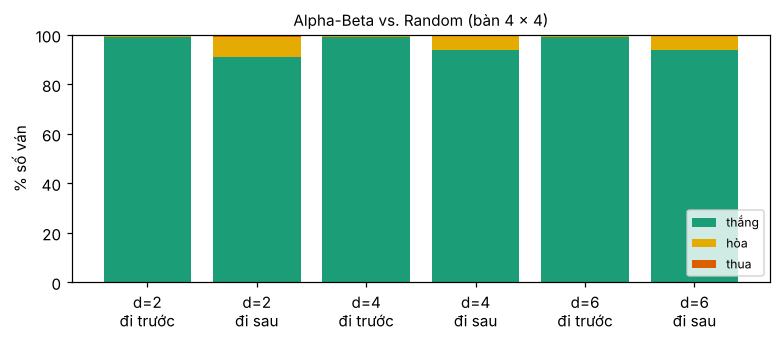

In [25]:
# Your code/ answer goes here.

# ---- Alpha-Beta (độ sâu cố định) đấu với Random trên bàn nhỏ 4 x 4: N ván mỗi vai ----
N_PLAY, PLAY_SHAPE, PLAY_DEPTHS = 100, (4, 4), [2, 4, 6]
np.random.seed(11)
t0 = time.time()
rows_out, play_stats, draw_reasons = [], {}, Counter()
for d in PLAY_DEPTHS:
    for role in ("đi trước (X)", "đi sau (O)"):
        agent = AlphaBetaPlayer(depth = d)
        red, yellow = (agent, random_player) if role.startswith("đi trước") else (random_player, agent)
        me = 1 if role.startswith("đi trước") else -1
        res, think, plies = Counter(), 0.0, 0
        for _ in range(N_PLAY):
            g_ = play_game(red, yellow, initial_state(PLAY_SHAPE))
            w = g_["winner"]
            res["thắng" if w == me else "thua" if w == -me else "hòa"] += 1
            if w == 0: draw_reasons[g_["reason"]] += 1
            think += g_["time"][me]; plies += g_["plies"]
        play_stats[(d, role)] = (res, think / N_PLAY, plies / N_PLAY)
        rows_out.append({"Độ sâu": d, "Vai của Alpha-Beta": role, "Số ván": N_PLAY, "Thắng": res["thắng"], "Hòa": res["hòa"], "Thua": res["thua"],
                         "Thời gian suy nghĩ TB mỗi ván (s)": round(think / N_PLAY, 3), "Số nước TB": round(plies / N_PLAY, 1)})
play_table = pd.DataFrame(rows_out)
display(play_table)
print(f"[{time.time() - t0:.0f} s]  Bàn {PLAY_SHAPE[0]} x {PLAY_SHAPE[1]}; Random chọn đều giữa mọi hành động (thả quân và chuyển quân).")

fig, ax = plt.subplots(figsize = (7.2, 3.2), dpi = 110)
labels = [f"d={d}\n{role.split(' ')[0]} {role.split(' ')[1]}" for d in PLAY_DEPTHS for role in ("đi trước (X)", "đi sau (O)")]
bottom = np.zeros(len(labels))
for key, color in (("thắng", "#1b9e77"), ("hòa", "#e6ab02"), ("thua", "#d95f02")):
    vals = np.array([play_stats[(d, role)][0][key] for d in PLAY_DEPTHS for role in ("đi trước (X)", "đi sau (O)")]) * 100 / N_PLAY
    ax.bar(labels, vals, bottom = bottom, label = key, color = color); bottom += vals
ax.set_ylabel("% số ván"); ax.set_title(f"Alpha-Beta vs. Random (bàn {PLAY_SHAPE[0]} x {PLAY_SHAPE[1]})", fontsize = 10); ax.legend(fontsize = 8, loc = "lower right")
plt.tight_layout(); plt.show()

In [26]:
get = lambda d, role, k: play_stats[(d, role)][0][k]
ROLES = ("đi trước (X)", "đi sau (O)")
WHY = {"cả hai cùng có 4 quân": "một nước đi (chuyển quân của tác tử hoặc của Random) làm cả hai bên cùng có 4 quân liên tiếp – theo quy ước 3 là hòa; trên bàn nhỏ 4 × 4 quân rơi xuống rất dễ tạo hàng",
       "bàn đầy": "bàn 16 ô đã đầy mà không bên nào có 4 quân",
       "lặp lại 3 lần": "thế cờ lặp lại 3 lần (hai bên chuyển quân qua lại)",
       "quá giới hạn nước đi": "ván vượt quá giới hạn nước đi của môi trường"}
tot_games = N_PLAY * len(ROLES) * len(PLAY_DEPTHS)
tot_loss = sum(get(d, r, "thua") for d in PLAY_DEPTHS for r in ROLES)
tot_draw = sum(get(d, r, "hòa") for d in PLAY_DEPTHS for r in ROLES)
win_rate = lambda d: 100 * sum(get(d, r, "thắng") for r in ROLES) / (2 * N_PLAY)
rates = [win_rate(d) for d in PLAY_DEPTHS]
mono = all(x <= y + 1e-9 for x, y in zip(rates, rates[1:]))
se = 100 * math.sqrt(0.25 / (2 * N_PLAY))
roles_gap = {d: 100 * (get(d, ROLES[0], "thắng") - get(d, ROLES[1], "thắng")) / N_PLAY for d in PLAY_DEPTHS}
t_lo, t_hi = (1000 * play_stats[(PLAY_DEPTHS[0], ROLES[0])][1], 1000 * play_stats[(PLAY_DEPTHS[-1], ROLES[0])][1])
display(Markdown(f"""
**Phân tích.** Mỗi dòng của bảng là {N_PLAY} ván; tổng cộng {tot_games} ván: Alpha-Beta thắng {tot_games - tot_loss - tot_draw}, hòa {tot_draw} và thua {tot_loss}.
* **{'Tác tử mạnh hơn Random rõ rệt' if min(rates) > 70 else 'Tác tử chưa vượt Random rõ rệt'}:** tỷ lệ thắng trung bình của hai vai là {', '.join(f'{r:.0f} % (độ sâu {d})' for r, d in zip(rates, PLAY_DEPTHS))}. {'Tỷ lệ tăng theo độ sâu' if mono else 'Tỷ lệ không tăng đơn điệu theo độ sâu: các chênh lệch này nằm trong mức dao động thống kê (sai số chuẩn khoảng ± ' + format(se, '.0f') + ' điểm % cho mỗi con số)'}; thời gian suy nghĩ tăng từ {t_lo:.1f} ms (độ sâu {PLAY_DEPTHS[0]}) lên {t_hi:.1f} ms mỗi ván (độ sâu {PLAY_DEPTHS[-1]}, vai đi trước).
* **Thua:** {'Alpha-Beta không thua ván nào – một tác tử nhìn trước đủ sâu hiếm khi bỏ lỡ đòn thắng / chặn một đe dọa ngắn của Random.' if tot_loss == 0 else 'Alpha-Beta thua ' + str(tot_loss) + ' ván: tìm kiếm chỉ nhìn tới độ sâu cố định nên một đòn thua nảy sinh từ nước chuyển quân của Random ở ngoài tầm nhìn vẫn có thể lọt qua (khác Connect 4 thường, nơi tìm tới cuối ván thì không bao giờ thua một ván hòa).'}
* **Hòa:** {tot_draw} ván{' (' + ', '.join(f'{k}: {v}' for k, v in draw_reasons.items()) + ')' if draw_reasons else ''}. {'Nguyên nhân: ' + '; '.join(WHY[k] for k in draw_reasons if k in WHY) + '. ' if draw_reasons else ''}Minimax chỉ phân biệt thắng / thua / chưa biết, nên khi chưa thấy đòn thắng trong tầm nhìn mọi nước đều ngang điểm và nó lấy nước đầu tiên theo thứ tự duyệt, không biết "tiến tới" thế thắng hay tránh tạo hàng 4 cho cả hai bên.
* **Hai vai:** chênh lệch tỷ lệ thắng giữa đi trước và đi sau (điểm %) là {', '.join(f'{roles_gap[d]:+.0f} (độ sâu {d})' for d in PLAY_DEPTHS)}; so với sai số chuẩn khoảng ± {se * 1.4:.0f} điểm % cho một hiệu, ta chưa thấy khác biệt rõ giữa hai vai.
"""))


**Phân tích.** Mỗi dòng của bảng là 100 ván; tổng cộng 600 ván: Alpha-Beta thắng 576, hòa 23 và thua 1.
* **Tác tử mạnh hơn Random rõ rệt:** tỷ lệ thắng trung bình của hai vai là 95 % (độ sâu 2), 96 % (độ sâu 4), 96 % (độ sâu 6). Tỷ lệ tăng theo độ sâu; thời gian suy nghĩ tăng từ 0.5 ms (độ sâu 2) lên 15.6 ms mỗi ván (độ sâu 6, vai đi trước).
* **Thua:** Alpha-Beta thua 1 ván: tìm kiếm chỉ nhìn tới độ sâu cố định nên một đòn thua nảy sinh từ nước chuyển quân của Random ở ngoài tầm nhìn vẫn có thể lọt qua (khác Connect 4 thường, nơi tìm tới cuối ván thì không bao giờ thua một ván hòa).
* **Hòa:** 23 ván (cả hai cùng có 4 quân: 16, bàn đầy: 7). Nguyên nhân: một nước đi (chuyển quân của tác tử hoặc của Random) làm cả hai bên cùng có 4 quân liên tiếp – theo quy ước 3 là hòa; trên bàn nhỏ 4 × 4 quân rơi xuống rất dễ tạo hàng; bàn 16 ô đã đầy mà không bên nào có 4 quân. Minimax chỉ phân biệt thắng / thua / chưa biết, nên khi chưa thấy đòn thắng trong tầm nhìn mọi nước đều ngang điểm và nó lấy nước đầu tiên theo thứ tự duyệt, không biết "tiến tới" thế thắng hay tránh tạo hàng 4 cho cả hai bên.
* **Hai vai:** chênh lệch tỷ lệ thắng giữa đi trước và đi sau (điểm %) là +8 (độ sâu 2), +5 (độ sâu 4), +5 (độ sâu 6); so với sai số chuẩn khoảng ± 5 điểm % cho một hiệu, ta chưa thấy khác biệt rõ giữa hai vai.


## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

### Hàm đánh giá heuristic

Tìm kiếm cắt ở độ sâu giới hạn phải *ước lượng* giá trị của một vị trí chưa phân thắng bại. Ta thiết kế **hai** hàm đánh giá (cả hai nhận `(g, cur, opp)`: hình học bitboard, quân của người **đang đi** và quân của đối thủ) rồi so sánh chúng bằng thực nghiệm:

* **H1 – cửa sổ + cột giữa** (ý tưởng như Connect 4 thường). Một *cửa sổ* là 4 ô thẳng hàng (ngang, dọc, chéo; bàn 6 × 7 có 69 cửa sổ). Cửa sổ **không có quân đối thủ** mà có 2 quân của mình tính +2 (cơ hội), có 3 quân tính +8 (đe dọa thắng); cửa sổ không có quân của mình mà đối thủ có 2 / 3 quân bị trừ tương ứng. Thêm 3 điểm cho mỗi quân ở cột giữa hơn đối thủ (cột giữa nằm trong nhiều cửa sổ nhất). Điểm thô $S$ được nén vào khoảng mở $(-1, 1)$ bằng $h = \tanh(S / 40)$, nên không bao giờ nhầm với giá trị thắng/thua $\pm 1$ của trạng thái kết thúc.
* **H2 – nhận biết luật "Mean"** = H1 + hai thành phần riêng của luật chuyển quân:
  1. **Quân đáy dễ bị lấy đi.** Đối thủ có thể lấy *quân đáy của mình* đi, kéo các quân phía trên rơi xuống và phá đường thẳng đang xây. Vì vậy một cửa sổ của mình có chứa quân ở hàng đáy chỉ được tính **một nửa** điểm (hệ số `FRAGILE = 0,5`); đối xứng, cửa sổ của đối thủ có quân đáy cũng chỉ bị trừ một nửa (đến lượt mình thì mình có thể lấy quân đó đi).
  2. **Khả năng chuyển quân (mobility).** Số cột có quân đáy của đối thủ = số nước chuyển quân mình có; số quân đáy của mình = số nước chuyển quân đối thủ có thể dùng chống lại mình. Thêm `MOBILITY = 1,5` điểm cho mỗi quân đáy của đối thủ hơn quân đáy của mình.

Mọi hệ số được chọn *trước* khi thí nghiệm theo lý do trên và **không** dò lại trên tập đánh giá (để tránh quá khớp); phần thi đấu bên dưới kiểm tra xem các thành phần "Mean" của H2 có thật sự giúp hay không.

,Số thế cờ,Nhỏ nhất,Lớn nhất,Trung bình,Độ lệch chuẩn,"Nằm trong (-1, 1)",Phản đối xứng,Bất biến lật trái-phải,Bàn rỗng
Hàm,,,,,,,,,
H1 (cửa sổ + cột giữa),1800,-0.868,0.956,0.108,0.292,True,True,True,0.0
H2 (nhận biết luật Mean),1800,-0.805,0.888,0.048,0.210,True,True,True,0.0


H2 với fragile = 1, mobility = 0 trùng khớp H1 trên mọi thế cờ thử: True


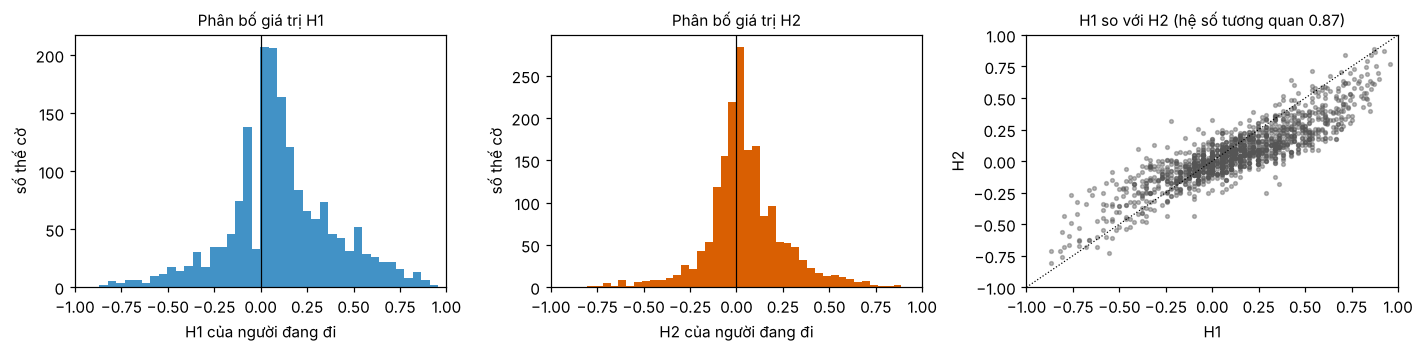

In [27]:
# Your code/ answer goes here.

HEUR_CENTER, HEUR_W2, HEUR_W3, HEUR_SCALE = 3.0, 2.0, 8.0, 40.0
FRAGILE, MOBILITY = 0.5, 1.5

def heuristic_windows(g, cur, opp):
    """H1: giá trị heuristic (trong (-1, 1)) của vị trí chưa kết thúc đối với người đang đi (sở hữu `cur`)."""
    score = HEUR_CENTER * (popcount(cur & g.center_mask) - popcount(opp & g.center_mask))
    for w in g.windows:                                   # duyệt 69 cửa sổ (bàn 6 x 7)
        mine, theirs = popcount(cur & w), popcount(opp & w)
        if theirs == 0:
            if mine == 2: score += HEUR_W2
            elif mine == 3: score += HEUR_W3
        elif mine == 0:
            if theirs == 2: score -= HEUR_W2
            elif theirs == 3: score -= HEUR_W3
    return math.tanh(score / HEUR_SCALE)

def heuristic_mean(g, cur, opp, fragile = FRAGILE, mobility = MOBILITY):
    """H2: H1 + (i) cửa sổ chứa quân đáy chỉ được tính `fragile` lần điểm, (ii) `mobility` điểm cho mỗi quân đáy của đối thủ hơn của mình.
    `fragile = 1, mobility = 0` cho đúng H1; hai tham số này cũng dùng để bật / tắt từng thành phần trong thí nghiệm so sánh."""
    br = g.bottom_row
    score = HEUR_CENTER * (popcount(cur & g.center_mask) - popcount(opp & g.center_mask))
    for w in g.windows:
        mine, theirs = popcount(cur & w), popcount(opp & w)
        if theirs == 0 and mine >= 2:
            s = HEUR_W2 if mine == 2 else HEUR_W3
            score += s * fragile if cur & w & br else s
        elif mine == 0 and theirs >= 2:
            s = HEUR_W2 if theirs == 2 else HEUR_W3
            score -= s * fragile if opp & w & br else s
    score += mobility * (popcount(opp & br) - popcount(cur & br))
    return math.tanh(score / HEUR_SCALE)

H_FUNCS = {"H1 (cửa sổ + cột giữa)": heuristic_windows, "H2 (nhận biết luật Mean)": heuristic_mean}

def heuristic(board, player = 1, evaluate = heuristic_mean):
    """Giao diện numpy: giá trị đối với `player`; trạng thái kết thúc trả về lợi ích thật (+1 / 0 / -1)."""
    u = utility(board, player)
    if u is not None: return float(u)
    g = MeanGeometry.get(*board.shape)
    cur, opp = g.to_bits(board, player)
    return evaluate(g, cur, opp)

# ---- Kiểm tra tính chất trên các thế cờ ngẫu nhiên: (1) nằm trong (-1, 1); (2) phản đối xứng h(cur, opp) = -h(opp, cur);
#      (3) bất biến khi lật trái-phải; (4) H2 với fragile = 1, mobility = 0 trùng H1; (5) bàn rỗng = 0 ----
g67 = MeanGeometry.get(6, 7)
POS_H = []
for k, plies in enumerate((4, 8, 12, 16, 22, 30)):
    POS_H += random_positions((6, 7), 300, plies, seed = 100 + k)
rows_out, H_VALUES = [], {}
for hname, hf in H_FUNCS.items():
    vals, antisym, mirror, consistent = [], True, True, True
    for b, p in POS_H:
        cur, opp = g67.to_bits(b, p)
        h = hf(g67, cur, opp)
        antisym &= abs(h + hf(g67, opp, cur)) < 1e-12
        cm, om = g67.to_bits(b[:, ::-1], p)
        mirror &= abs(hf(g67, cm, om) - h) < 1e-12
        consistent &= abs(heuristic_mean(g67, cur, opp, 1.0, 0.0) - heuristic_windows(g67, cur, opp)) < 1e-12
        vals.append(h)
    vals = np.array(vals); H_VALUES[hname] = vals
    rows_out.append({"Hàm": hname, "Số thế cờ": len(vals), "Nhỏ nhất": round(vals.min(), 3), "Lớn nhất": round(vals.max(), 3), "Trung bình": round(vals.mean(), 3),
                     "Độ lệch chuẩn": round(vals.std(), 3), "Nằm trong (-1, 1)": bool((abs(vals) < 1).all()), "Phản đối xứng": bool(antisym),
                     "Bất biến lật trái-phải": bool(mirror), "Bàn rỗng": round(hf(g67, 0, 0), 3)})
heur_table = pd.DataFrame(rows_out).set_index("Hàm")
display(heur_table)
print("H2 với fragile = 1, mobility = 0 trùng khớp H1 trên mọi thế cờ thử:", bool(consistent))

h1v, h2v = H_VALUES["H1 (cửa sổ + cột giữa)"], H_VALUES["H2 (nhận biết luật Mean)"]
corr = float(np.corrcoef(h1v, h2v)[0, 1])
fig, ax = plt.subplots(1, 3, figsize = (13, 3.3), dpi = 110)
for a_, vals, name, color in ((ax[0], h1v, "H1", "#4292c6"), (ax[1], h2v, "H2", "#d95f02")):
    a_.hist(vals, bins = 40, color = color); a_.axvline(0, color = "k", lw = .8); a_.set_xlim(-1, 1)
    a_.set_xlabel(f"{name} của người đang đi"); a_.set_ylabel("số thế cờ"); a_.set_title(f"Phân bố giá trị {name}", fontsize = 10)
ax[2].scatter(h1v, h2v, s = 6, alpha = .4, color = "#555555"); ax[2].plot([-1, 1], [-1, 1], "k:", lw = .8)
ax[2].set_xlim(-1, 1); ax[2].set_ylim(-1, 1); ax[2].set_xlabel("H1"); ax[2].set_ylabel("H2"); ax[2].set_title(f"H1 so với H2 (hệ số tương quan {corr:.2f})", fontsize = 10)
plt.tight_layout(); plt.show()

In [28]:
d_h = h2v - h1v
display(Markdown(f"""
**Nhận xét.** Trên {len(h1v):,} thế cờ (kể cả các thế có nhiều nước chuyển quân), cả hai hàm đều nằm trong $(-1, 1)$, phản đối xứng (giá trị của người này là số đối của người kia – cần thiết cho Minimax dạng negamax), bất biến khi lật trái–phải và bằng 0 ở bàn rỗng. H2 tương quan mạnh với H1 (hệ số {corr:.2f}) vì chỉ thêm hai thành phần nhỏ, nhưng không giống hệt: chênh lệch trung bình |H2 − H1| = {np.abs(d_h).mean():.3f}, lớn nhất {np.abs(d_h).max():.3f}. Vì giá trị heuristic bị nén bởi tanh nên luôn nhỏ hơn giá trị chắc chắn thắng (+1) – tìm kiếm không bao giờ ưa một thế "có vẻ tốt" hơn một nước thắng thật.
"""))


**Nhận xét.** Trên 1,800 thế cờ (kể cả các thế có nhiều nước chuyển quân), cả hai hàm đều nằm trong $(-1, 1)$, phản đối xứng (giá trị của người này là số đối của người kia – cần thiết cho Minimax dạng negamax), bất biến khi lật trái–phải và bằng 0 ở bàn rỗng. H2 tương quan mạnh với H1 (hệ số 0.87) vì chỉ thêm hai thành phần nhỏ, nhưng không giống hệt: chênh lệch trung bình |H2 − H1| = 0.123, lớn nhất 0.548. Vì giá trị heuristic bị nén bởi tanh nên luôn nhỏ hơn giá trị chắc chắn thắng (+1) – tìm kiếm không bao giờ ưa một thế "có vẻ tốt" hơn một nước thắng thật.


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

### Cắt tìm kiếm ở độ sâu giới hạn

Tác tử Alpha-Beta của Task 3 đã có sẵn tham số `evaluate`: tại độ sâu giới hạn (`cutoff` nửa-nước) nó gọi hàm heuristic thay vì trả về 0 ("chưa biết"). Lớp `HeuristicAlphaBetaPlayer` chỉ là tên gọi theo đề bài cho cấu hình đó – *cùng một* cài đặt (bitboard, cắt tỉa, bảng chuyển vị, xét nước thắng ngay) nên các kết quả ở Task 3 và Task 4 so sánh được với nhau. Trạng thái kết thúc trong tầm nhìn vẫn có lợi ích thật (±1, cộng thêm phần thưởng nhỏ cho thắng nhanh / thua chậm) nên luôn hơn mọi giá trị heuristic.

H1 (cửa sổ + cột giữa)


,Thời gian TB (ms),Số nút TB,Nước chọn trên bàn rỗng,Giá trị bàn rỗng,Giá trị TB (thế giữa ván)
Cutoff,,,,,
1,22.0,15,thả 3,+0.075,+0.262
2,0.7,66,thả 3,+0.000,+0.067
3,3.7,432,thả 3,+0.124,+0.293
4,14.0,"1,318",thả 3,+0.000,+0.056
5,57.7,"6,502",thả 3,+0.124,+0.306
6,132.9,"15,512",thả 3,+0.000,+0.080
7,508.9,"58,293",thả 3,+0.173,+0.354
8,959.0,"114,528",thả 3,-0.075,+0.086


H2 (nhận biết luật Mean)


,Thời gian TB (ms),Số nút TB,Nước chọn trên bàn rỗng,Giá trị bàn rỗng,Giá trị TB (thế giữa ván)
Cutoff,,,,,
1,0.2,15,thả 3,+0.037,+0.187
2,0.7,72,thả 3,-0.037,+0.034
3,4.6,518,thả 3,+0.025,+0.201
4,16.6,"1,717",thả 3,-0.075,+0.036
5,96.9,"9,252",thả 3,+0.012,+0.221
6,216.4,"23,342",thả 3,-0.087,+0.042
7,839.6,"85,433",thả 2,+0.025,+0.238
8,1726.6,"174,609",thả 3,-0.100,+0.063


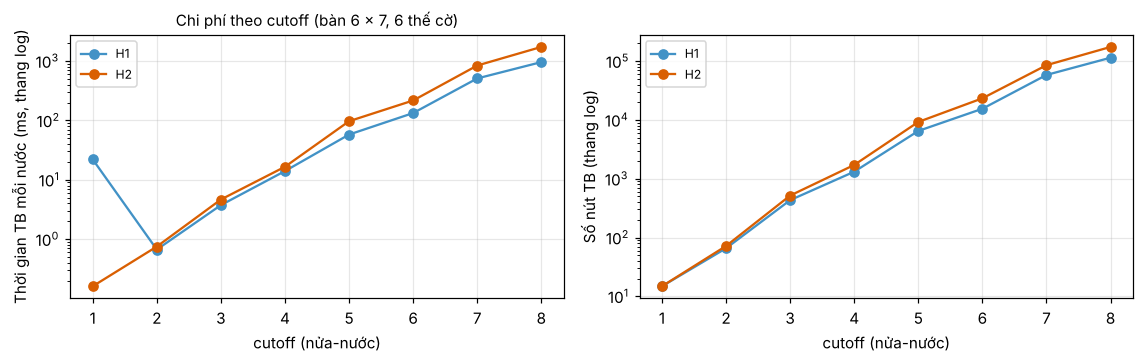

In [29]:
# Your code/ answer goes here.

class HeuristicAlphaBetaPlayer(AlphaBetaPlayer):
    """Alpha-Beta cắt ở độ sâu `cutoff` (nửa-nước) và đánh giá lá chưa kết thúc bằng `evaluate(g, cur, opp)` (mặc định H1)."""
    def __init__(self, cutoff = 4, evaluate = None, name = None, **kw):
        super().__init__(depth = cutoff, evaluate = evaluate or heuristic_windows, name = name or f"Heuristic Alpha-Beta (cutoff {cutoff})", **kw)

    @property
    def cutoff(self): return self.depth

CUTOFFS = [1, 2, 3, 4, 5, 6, 7, 8]
CUT_POS = [(initial_state(), 1)] + random_positions((6, 7), 5, 8, seed = 21)        # bàn rỗng + các thế cờ giữa ván
cut_data, tables = {}, {}
for hname, hf in H_FUNCS.items():
    rows_out = []
    for d in CUTOFFS:
        ts, nodes, acts, vals = [], [], [], []
        for b, p in CUT_POS:
            ag = HeuristicAlphaBetaPlayer(cutoff = d, evaluate = hf)
            t0 = time.perf_counter(); a = ag(b, p); ts.append(time.perf_counter() - t0)
            nodes.append(ag.nodes); acts.append(a); vals.append(ag.last_value)
        cut_data[(hname, d)] = dict(ms = 1000 * float(np.mean(ts)), nodes = float(np.mean(nodes)), first = acts[0], v_first = vals[0], v_mid = float(np.mean(vals[1:])), vals = vals)
        rows_out.append({"Cutoff": d, "Thời gian TB (ms)": round(cut_data[(hname, d)]["ms"], 1), "Số nút TB": f"{np.mean(nodes):,.0f}",
                         "Nước chọn trên bàn rỗng": fmt_action(acts[0]), "Giá trị bàn rỗng": f"{vals[0]:+.3f}", "Giá trị TB (thế giữa ván)": f"{np.mean(vals[1:]):+.3f}"})
    tables[hname] = pd.DataFrame(rows_out).set_index("Cutoff")
    print(hname); display(tables[hname])

fig, ax = plt.subplots(1, 2, figsize = (10.5, 3.4), dpi = 110)
for (hname, color) in zip(H_FUNCS, ("#4292c6", "#d95f02")):
    ax[0].plot(CUTOFFS, [cut_data[(hname, d)]["ms"] for d in CUTOFFS], "o-", color = color, label = hname.split(" ")[0])
    ax[1].plot(CUTOFFS, [cut_data[(hname, d)]["nodes"] for d in CUTOFFS], "o-", color = color, label = hname.split(" ")[0])
for a_, yl in zip(ax, ("Thời gian TB mỗi nước (ms, thang log)", "Số nút TB (thang log)")):
    a_.set_yscale("log"); a_.set_xlabel("cutoff (nửa-nước)"); a_.set_ylabel(yl); a_.grid(alpha = .3); a_.legend(fontsize = 8)
ax[0].set_title(f"Chi phí theo cutoff (bàn 6 x 7, {len(CUT_POS)} thế cờ)", fontsize = 10)
plt.tight_layout(); plt.show()

In [30]:
h1, h2 = list(H_FUNCS)
C0, C1 = CUTOFFS[0], CUTOFFS[-1]
growth = lambda hn: (cut_data[(hn, C1)]["nodes"] / cut_data[(hn, C0)]["nodes"]) ** (1 / (C1 - C0))
nr = cut_data[(h2, C1)]['nodes'] / cut_data[(h1, C1)]['nodes']
firsts = {hn: sorted({fmt_action(cut_data[(hn, d)]["first"]) for d in CUTOFFS}) for hn in H_FUNCS}
odd = [d for d in CUTOFFS if d % 2]; even = [d for d in CUTOFFS if d % 2 == 0]
par = lambda hn: (np.mean([cut_data[(hn, d)]["v_mid"] for d in odd]), np.mean([cut_data[(hn, d)]["v_mid"] for d in even]))
display(Markdown(f"""
**Nhận xét.**
* **Chi phí tăng theo hàm mũ với cutoff:** mỗi mức sâu thêm nhân số nút lên ≈ ×{growth(h1):.1f} (H1) và ×{growth(h2):.1f} (H2); thời gian mỗi nước đi từ {cut_data[(h1, C0)]['ms']:.2f} ms (cutoff {C0}) lên {cut_data[(h1, C1)]['ms']:.0f} ms (cutoff {C1}) với H1. Hệ số nhánh hiệu dụng ≈ {growth(h1):.1f} thấp hơn nhiều so với số hành động ({len(actions(initial_state(), 1))} ở bàn rỗng, tới ~30–40 giữa ván) nhờ cắt tỉa, bảng chuyển vị và xét nước thắng ngay.
* **Giá của luật "Mean" trong hàm đánh giá:** H2 chậm hơn H1 ≈ ×{cut_data[(h2, C1)]['ms'] / cut_data[(h1, C1)]['ms']:.2f} ở cutoff {C1} (thêm kiểm tra quân đáy cho mỗi cửa sổ) – {'số nút gần như không đổi (' + format(nr, '.2f') + ' lần), nên phần chênh lệch hoàn toàn là chi phí mỗi lá' if 0.8 <= nr <= 1.25 else 'số nút cũng khác (' + format(nr, '.2f') + ' lần số nút của H1) vì giá trị đánh giá khác nhau làm thứ tự duyệt và cắt tỉa khác nhau, nên chênh lệch thời gian gồm cả hai nguyên nhân'}.
* **Nước chọn trên bàn rỗng:** {', '.join(f'{hn.split(chr(32))[0]}: ' + '/'.join(v) for hn, v in firsts.items())} qua mọi cutoff đã thử. {'Cột giữa ổn định ở mọi cutoff – phù hợp với kiến thức về Connect 4 thường.' if all(v == ['thả 3'] for v in firsts.values()) else 'Nước đi đổi theo cutoff: trên bàn rỗng nhiều nước gần ngang giá trị nên kết quả nhạy với độ sâu.'}
* **Hiệu ứng chẵn/lẻ của giá trị đánh giá:** trung bình giá trị ở cutoff *lẻ* là {par(h1)[0]:+.3f} và ở cutoff *chẵn* là {par(h1)[1]:+.3f} (H1, thế cờ giữa ván). Ở cutoff lẻ lá cuối là thế ngay sau nước đi của chính mình, chưa tính phản ứng của đối thủ nên lạc quan hơn; ở cutoff chẵn đã có cả phản ứng này – thiên lệch quen thuộc của tìm kiếm cắt độ sâu.
* Vì giá trị heuristic chỉ là *ước lượng*, chênh lệch giữa các cutoff không nói cutoff nào đúng hơn; độ chính xác thật sự được đo ở hai ô sau (so với đáp án chuẩn của Task 3) và bằng thi đấu.
"""))


**Nhận xét.**
* **Chi phí tăng theo hàm mũ với cutoff:** mỗi mức sâu thêm nhân số nút lên ≈ ×3.6 (H1) và ×3.8 (H2); thời gian mỗi nước đi từ 22.03 ms (cutoff 1) lên 959 ms (cutoff 8) với H1. Hệ số nhánh hiệu dụng ≈ 3.6 thấp hơn nhiều so với số hành động (7 ở bàn rỗng, tới ~30–40 giữa ván) nhờ cắt tỉa, bảng chuyển vị và xét nước thắng ngay.
* **Giá của luật "Mean" trong hàm đánh giá:** H2 chậm hơn H1 ≈ ×1.80 ở cutoff 8 (thêm kiểm tra quân đáy cho mỗi cửa sổ) – số nút cũng khác (1.52 lần số nút của H1) vì giá trị đánh giá khác nhau làm thứ tự duyệt và cắt tỉa khác nhau, nên chênh lệch thời gian gồm cả hai nguyên nhân.
* **Nước chọn trên bàn rỗng:** H1: thả 3, H2: thả 2/thả 3 qua mọi cutoff đã thử. Nước đi đổi theo cutoff: trên bàn rỗng nhiều nước gần ngang giá trị nên kết quả nhạy với độ sâu.
* **Hiệu ứng chẵn/lẻ của giá trị đánh giá:** trung bình giá trị ở cutoff *lẻ* là +0.304 và ở cutoff *chẵn* là +0.072 (H1, thế cờ giữa ván). Ở cutoff lẻ lá cuối là thế ngay sau nước đi của chính mình, chưa tính phản ứng của đối thủ nên lạc quan hơn; ở cutoff chẵn đã có cả phản ứng này – thiên lệch quen thuộc của tìm kiếm cắt độ sâu.
* Vì giá trị heuristic chỉ là *ước lượng*, chênh lệch giữa các cutoff không nói cutoff nào đúng hơn; độ chính xác thật sự được đo ở hai ô sau (so với đáp án chuẩn của Task 3) và bằng thi đấu.


Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [31]:
# Your code/ answer goes here.

# ---- Cùng bảy bàn cờ thử như Task 3: tác tử heuristic ở các cutoff khác nhau có chọn nước giữ được kết quả (thắng / không thua) không? ----
MAN_CUTOFFS = [1, 2, 3, 4, 5, 6, 8]
hab_choice, hab_ok = {}, {}
for hname, hf in H_FUNCS.items():
    for name, (b, p) in TEST_BOARDS.items():
        keeps = TEST_INFO[name]["keeps"]
        for d in MAN_CUTOFFS:
            a = HeuristicAlphaBetaPlayer(cutoff = d, evaluate = hf)(b, p)
            hab_choice[(hname, name, d)] = a
            hab_ok[(hname, name, d)] = a in keeps

cols = pd.MultiIndex.from_product([[h.split(" ")[0] for h in H_FUNCS], [f"cutoff {d}" for d in MAN_CUTOFFS]])
man_table = pd.DataFrame([[("✓" if hab_ok[(hn, name, d)] else "✗") for hn in H_FUNCS for d in MAN_CUTOFFS] for name in TEST_BOARDS],
                         index = list(TEST_BOARDS), columns = cols)
man_table.loc["Số bàn đúng"] = [f"{sum(hab_ok[(hn, nm, d)] for nm in TEST_BOARDS)}/{len(TEST_BOARDS)}" for hn in H_FUNCS for d in MAN_CUTOFFS]
display(man_table)
print("✓ = nước chọn nằm trong tập các nước giữ được kết quả (thắng nếu bàn thắng được; không thua nếu không) theo đáp án chuẩn của Task 3.")

H1                                      \
                                cutoff 1 cutoff 2 cutoff 3 cutoff 4 cutoff 5   
1. Thắng ngay: thả quân                ✓        ✓        ✓        ✓        ✓   
2. Thắng ngay: chuyển quân             ✓        ✓        ✓        ✓        ✓   
3. Phải chặn: thả quân                 ✓        ✓        ✓        ✓        ✓   
4. Phải chặn: chuyển quân              ✗        ✓        ✓        ✓        ✓   
5. Thắng sau 3 nửa-nước                ✗        ✓        ✓        ✓        ✓   
6. Thắng sau 5 nửa-nước                ✓        ✓        ✓        ✓        ✓   
7. Thế cân bằng (có nước đi dở)        ✓        ✓        ✓        ✓        ✓   
Số bàn đúng                          5/7      7/7      7/7      7/7      7/7   

                                                        H2                    \
                                cutoff 6 cutoff 8 cutoff 1 cutoff 2 cutoff 3   
1. Thắng ngay: thả quân                ✓        ✓        ✓        ✓        ✓   
2. Thắng ngay: chuyển quân             ✓        ✓        ✓        ✓        ✓   
3. Phải chặn: thả quân                 ✓        ✓        ✓        ✓        ✓   
4. Phải chặn: chuyển quân              ✓        ✓        ✗        ✓        ✓   
5. Thắng sau 3 nửa-nước                ✓        ✓        ✗        ✗        ✓   
6. Thắng sau 5 nửa-nước                ✓        ✓        ✓        ✓        ✓   
7. Thế cân bằng (có nước đi dở)        ✓        ✓        ✓        ✓        ✓   
Số bàn đúng                          7/7      7/7      5/7      6/7      7/7   

                                                                     
                                cutoff 4 cutoff 5 cutoff 6 cutoff 8  
1. Thắng ngay: thả quân                ✓        ✓        ✓        ✓  
2. Thắng ngay: chuyển quân             ✓        ✓        ✓        ✓  
3. Phải chặn: thả quân                 ✓        ✓        ✓        ✓  
4. Phải chặn: chuyển quân              ✓        ✓        ✓        ✓  
5. Thắng sau 3 nửa-nước                ✓        ✓        ✓        ✓  
6. Thắng sau 5 nửa-nước                ✓        ✓        ✓        ✓  
7. Thế cân bằng (có nước đi dở)        ✓        ✓        ✓        ✓  
Số bàn đúng                          7/7      7/7      7/7      7/7

✓ = nước chọn nằm trong tập các nước giữ được kết quả (thắng nếu bàn thắng được; không thua nếu không) theo đáp án chuẩn của Task 3.


In [32]:
n = len(TEST_BOARDS)
correct = {(hn, d): sum(hab_ok[(hn, nm, d)] for nm in TEST_BOARDS) for hn in H_FUNCS for d in MAN_CUTOFFS}
first_all = {hn: next((d for d in MAN_CUTOFFS if correct[(hn, d)] == n), None) for hn in H_FUNCS}
wrong_cnt = {nm: sum(not hab_ok[(hn, nm, d)] for hn in H_FUNCS for d in MAN_CUTOFFS) for nm in TEST_BOARDS}
hardest = max(wrong_cnt, key = wrong_cnt.get)
always_ok = [nm for nm in TEST_BOARDS if wrong_cnt[nm] == 0]
h1, h2 = list(H_FUNCS)
tot = {hn: sum(correct[(hn, d)] for d in MAN_CUTOFFS) for hn in H_FUNCS}
display(Markdown(f"""
**Nhận xét.** Số bàn chọn đúng theo cutoff — H1: {', '.join(f'{d}: {correct[(h1, d)]}/{n}' for d in MAN_CUTOFFS)}; H2: {', '.join(f'{d}: {correct[(h2, d)]}/{n}' for d in MAN_CUTOFFS)}.
* **{len(always_ok)} bàn đúng ở mọi cutoff và cả hai hàm** ({'; '.join(nm.split('. ')[1] for nm in always_ok) or 'không bàn nào'}): nước thắng ngay / chặn bắt buộc nằm trong tầm nhìn của cả cutoff nhỏ.
* **Bàn khó nhất:** "{hardest}" – sai {wrong_cnt[hardest]}/{2 * len(MAN_CUTOFFS)} lượt thử. Khi đòn thắng / thua nằm ngoài tầm nhìn, nước đi do giá trị heuristic quyết định và chỉ đúng khi heuristic tình cờ đồng ý với nước đúng; kết quả không nhất thiết đơn điệu theo cutoff.
* **Cutoff đầu tiên chọn đúng cả {n}/{n} bàn:** H1: {first_all[h1] if first_all[h1] else 'chưa có'}; H2: {first_all[h2] if first_all[h2] else 'chưa có'}. Tổng số lượt đúng trên mọi cutoff: H1 {tot[h1]}, H2 {tot[h2]} (tối đa {n * len(MAN_CUTOFFS)}) – {'hai hàm tương đương trên tập bàn thử nhỏ này' if abs(tot[h1] - tot[h2]) <= 1 else ('H2 nhỉnh hơn' if tot[h2] > tot[h1] else 'H1 nhỉnh hơn')}; bảy bàn là quá ít để phân biệt hai heuristic (xem thi đấu ở ô cuối).
* So với Alpha-Beta chính xác ở Task 3, tác tử heuristic chỉ cần cutoff nhỏ và vài ms mỗi nước nhưng **không đảm bảo** nước đi đúng ở những bàn mà đáp án nằm ngoài tầm nhìn.
"""))


**Nhận xét.** Số bàn chọn đúng theo cutoff — H1: 1: 5/7, 2: 7/7, 3: 7/7, 4: 7/7, 5: 7/7, 6: 7/7, 8: 7/7; H2: 1: 5/7, 2: 6/7, 3: 7/7, 4: 7/7, 5: 7/7, 6: 7/7, 8: 7/7.
* **5 bàn đúng ở mọi cutoff và cả hai hàm** (Thắng ngay: thả quân; Thắng ngay: chuyển quân; Phải chặn: thả quân; Thắng sau 5 nửa-nước; Thế cân bằng (có nước đi dở)): nước thắng ngay / chặn bắt buộc nằm trong tầm nhìn của cả cutoff nhỏ.
* **Bàn khó nhất:** "5. Thắng sau 3 nửa-nước" – sai 3/14 lượt thử. Khi đòn thắng / thua nằm ngoài tầm nhìn, nước đi do giá trị heuristic quyết định và chỉ đúng khi heuristic tình cờ đồng ý với nước đúng; kết quả không nhất thiết đơn điệu theo cutoff.
* **Cutoff đầu tiên chọn đúng cả 7/7 bàn:** H1: 2; H2: 3. Tổng số lượt đúng trên mọi cutoff: H1 47, H2 46 (tối đa 49) – hai hàm tương đương trên tập bàn thử nhỏ này; bảy bàn là quá ít để phân biệt hai heuristic (xem thi đấu ở ô cuối).
* So với Alpha-Beta chính xác ở Task 3, tác tử heuristic chỉ cần cutoff nhỏ và vài ms mỗi nước nhưng **không đảm bảo** nước đi đúng ở những bàn mà đáp án nằm ngoài tầm nhìn.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

,cutoff 3: H1 (ms),cutoff 3: H2 (ms),cutoff 3: số nút TB (H1),cutoff 5: H1 (ms),cutoff 5: H2 (ms),cutoff 5: số nút TB (H1),cutoff 7: H1 (ms),cutoff 7: H2 (ms),cutoff 7: số nút TB (H1)
Số cột,,,,,,,,,
4,0.3,0.2,43,1.6,1.7,366,10.7,9.9,"2,445"
5,0.5,0.5,70,3.9,6.0,696,28.8,42.3,"5,104"
6,1.4,1.7,186,14.9,17.8,"2,115",102.8,136.1,"14,662"
7,1.4,1.5,162,19.4,30.2,"2,316",173.2,279.8,"19,642"
8,3.0,3.0,313,43.6,69.7,"4,767",478.2,827.3,"49,207"
9,7.6,10.8,689,143.1,271.9,"13,087",1836.1,3969.2,"161,106"
10,8.5,9.1,680,197.8,230.7,"14,861",2276.3,3764.9,"194,204"


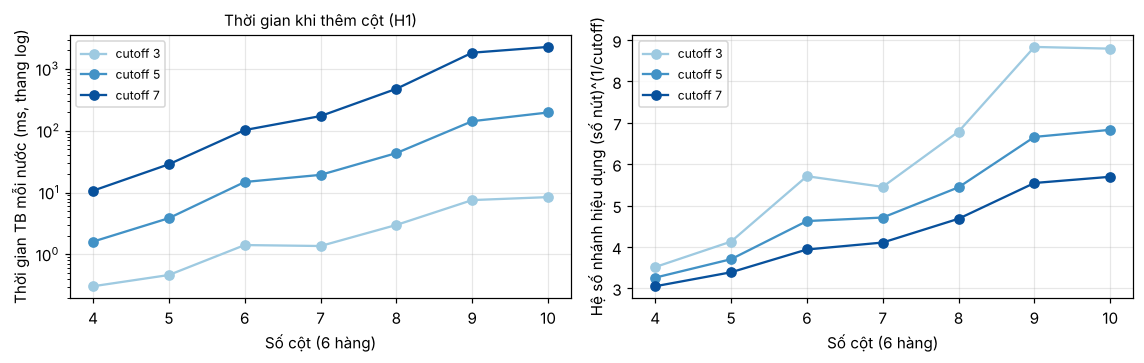

In [33]:
# Your code/ answer goes here.

# ---- Thời gian mỗi nước theo số cột (6 hàng), tác tử heuristic ở ba cutoff cố định ----
TIME_COLS, TIME_CUTOFFS, TIME_POS = [4, 5, 6, 7, 8, 9, 10], [3, 5, 7], 2
time_data, rows_out = {}, []
for cols_ in TIME_COLS:
    shape = (6, cols_)
    positions = [(initial_state(shape), 1)] + random_positions(shape, TIME_POS, 6, seed = 300 + cols_)
    row = {"Số cột": cols_}
    for d in TIME_CUTOFFS:
        for hname, hf in H_FUNCS.items():
            ts, nodes = [], []
            for b, p in positions:
                ag = HeuristicAlphaBetaPlayer(cutoff = d, evaluate = hf)
                t0 = time.perf_counter(); ag(b, p); ts.append(time.perf_counter() - t0); nodes.append(ag.nodes)
            time_data[(cols_, d, hname)] = (1000 * float(np.mean(ts)), float(np.mean(nodes)))
        row[f"cutoff {d}: H1 (ms)"] = round(time_data[(cols_, d, list(H_FUNCS)[0])][0], 1)
        row[f"cutoff {d}: H2 (ms)"] = round(time_data[(cols_, d, list(H_FUNCS)[1])][0], 1)
        row[f"cutoff {d}: số nút TB (H1)"] = f"{time_data[(cols_, d, list(H_FUNCS)[0])][1]:,.0f}"
    rows_out.append(row)
time_table = pd.DataFrame(rows_out).set_index("Số cột")
display(time_table)

fig, ax = plt.subplots(1, 2, figsize = (10.5, 3.4), dpi = 110)
H1N, H2N = list(H_FUNCS)
for d, color in zip(TIME_CUTOFFS, ("#9ecae1", "#4292c6", "#08519c")):
    ax[0].plot(TIME_COLS, [time_data[(c, d, H1N)][0] for c in TIME_COLS], "o-", color = color, label = f"cutoff {d}")
    ax[1].plot(TIME_COLS, [time_data[(c, d, H1N)][1] ** (1 / d) for c in TIME_COLS], "o-", color = color, label = f"cutoff {d}")
ax[0].set_yscale("log"); ax[0].set_ylabel("Thời gian TB mỗi nước (ms, thang log)"); ax[1].set_ylabel("Hệ số nhánh hiệu dụng (số nút)^(1/cutoff)")
for a_ in ax: a_.set_xlabel("Số cột (6 hàng)"); a_.grid(alpha = .3); a_.legend(fontsize = 8)
ax[0].set_title("Thời gian khi thêm cột (H1)", fontsize = 10)
plt.tight_layout(); plt.show()

In [34]:
def per_col(d, hn = H1N):
    ms = [time_data[(c, d, hn)][0] for c in TIME_COLS]
    return (ms[-1] / ms[0]) ** (1 / (len(ms) - 1))
beff = lambda c, d: time_data[(c, d, H1N)][1] ** (1 / d)
c0, c1 = TIME_COLS[0], TIME_COLS[-1]
dd = TIME_CUTOFFS
ratio_h = np.mean([time_data[(c, d, H2N)][0] / time_data[(c, d, H1N)][0] for c in TIME_COLS for d in dd])
display(Markdown(f"""
**Nhận xét.**
* **Thời gian tăng theo số cột:** thêm một cột nhân thời gian lên ≈ ×{per_col(dd[0]):.2f} (cutoff {dd[0]}), ×{per_col(dd[1]):.2f} (cutoff {dd[1]}) và ×{per_col(dd[2]):.2f} (cutoff {dd[2]}). Cutoff càng sâu thì mỗi cột thêm càng đắt vì số nút ≈ b^d với hệ số nhánh b tăng theo số cột: hệ số nhánh hiệu dụng ở cutoff {dd[2]} tăng từ {beff(c0, dd[2]):.1f} ({c0} cột) lên {beff(c1, dd[2]):.1f} ({c1} cột).
* **Con số cụ thể:** ở {c1} cột, mỗi nước mất {time_data[(c1, dd[0], H1N)][0]:.1f} ms (cutoff {dd[0]}), {time_data[(c1, dd[1], H1N)][0]:.0f} ms (cutoff {dd[1]}) và {time_data[(c1, dd[2], H1N)][0]:.0f} ms (cutoff {dd[2]}), so với {time_data[(c0, dd[2], H1N)][0]:.1f} ms ở cutoff {dd[2]} với {c0} cột.
* **H2 chậm hơn H1** trung bình ≈ ×{ratio_h:.2f} ở mọi kích thước (cùng số nút, chỉ thêm chi phí đánh giá mỗi lá).
* So với Task 3 (tìm sâu cố định, cùng cấu hình bitboard), cutoff + heuristic cho phép *chọn độ sâu theo ngân sách thời gian cho bàn cờ bất kỳ*: với bàn rộng hơn ta giảm cutoff để giữ mỗi nước dưới ngưỡng mong muốn.
"""))


**Nhận xét.**
* **Thời gian tăng theo số cột:** thêm một cột nhân thời gian lên ≈ ×1.74 (cutoff 3), ×2.23 (cutoff 5) và ×2.44 (cutoff 7). Cutoff càng sâu thì mỗi cột thêm càng đắt vì số nút ≈ b^d với hệ số nhánh b tăng theo số cột: hệ số nhánh hiệu dụng ở cutoff 7 tăng từ 3.0 (4 cột) lên 5.7 (10 cột).
* **Con số cụ thể:** ở 10 cột, mỗi nước mất 8.5 ms (cutoff 3), 198 ms (cutoff 5) và 2276 ms (cutoff 7), so với 10.7 ms ở cutoff 7 với 4 cột.
* **H2 chậm hơn H1** trung bình ≈ ×1.36 ở mọi kích thước (cùng số nút, chỉ thêm chi phí đánh giá mỗi lá).
* So với Task 3 (tìm sâu cố định, cùng cấu hình bitboard), cutoff + heuristic cho phép *chọn độ sâu theo ngân sách thời gian cho bàn cờ bất kỳ*: với bàn rộng hơn ta giảm cutoff để giữ mỗi nước dưới ngưỡng mong muốn.


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

,Quân đỏ (đi trước),Quân vàng,Kết quả,Số nước,Lý do kết thúc,Số nước chuyển quân (đỏ / vàng),Thời gian suy nghĩ (s) đỏ / vàng
Ván,,,,,,,
1,H2 · cutoff 6,H1 · cutoff 4,H1 · cutoff 4 thắng,26,có người đạt 4 quân,5 / 0,1.1 / 0.1
2,H1 · cutoff 4,H2 · cutoff 6,H1 · cutoff 4 thắng,25,có người đạt 4 quân,0 / 8,0.1 / 1.0


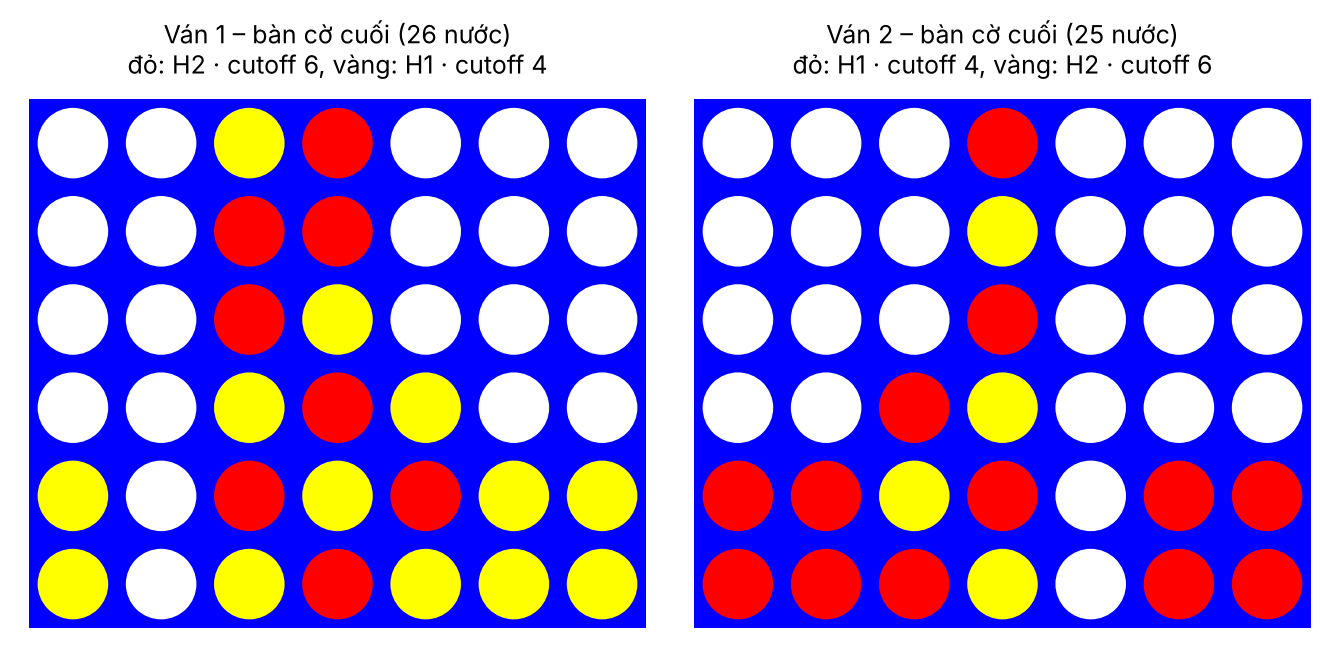

10 nước đầu của ván 1: đỏ thả 3, vàng thả 3, đỏ thả 3, vàng thả 3, đỏ thả 3, vàng thả 2, đỏ thả 2, vàng thả 2, đỏ thả 2, vàng thả 0


,H1,H1 + quân đáy dễ bị lấy,H1 + mobility,H2 (cả hai),Điểm TB
H1,–,0.62,0.57,0.68,0.62
H1 + quân đáy dễ bị lấy,0.38,–,0.48,0.62,0.49
H1 + mobility,0.43,0.52,–,0.57,0.51
H2 (cả hai),0.32,0.38,0.43,–,0.38


(điểm của hàng so với cột; thắng = 1, hòa = 0,5; mỗi ô 60 ván, cutoff = 4; 146 s)


In [35]:
# Your code/ answer goes here.

# ---- Playtime: hai tác tử heuristic KHÁC cutoff và KHÁC hàm đánh giá đấu trên bàn 6 x 7 (xác định nên mỗi cấu hình quân chỉ cần chơi một lần) ----
class Logged:
    """Bọc một tác tử để ghi lại (người, hành động) vào nhật ký chung."""
    def __init__(self, agent, log): self.agent, self.log, self.name = agent, log, agent.name
    def __call__(self, board, player = None):
        a = self.agent(board, player); self.log.append((player, a)); return a

PLAY_A = HeuristicAlphaBetaPlayer(cutoff = 6, evaluate = heuristic_mean, name = "H2 · cutoff 6")
PLAY_B = HeuristicAlphaBetaPlayer(cutoff = 4, evaluate = heuristic_windows, name = "H1 · cutoff 4")
games_p, rows_out = {}, []
for a_red in (True, False):
    log = []
    red, yellow = (PLAY_A, PLAY_B) if a_red else (PLAY_B, PLAY_A)
    g_ = play_game(Logged(red, log), Logged(yellow, log), initial_state())
    games_p[a_red] = (g_, log)
    me = 1 if a_red else -1
    res = {me: f"{PLAY_A.name} thắng", -me: f"{PLAY_B.name} thắng", 0: "hòa"}[g_["winner"]]
    n_move = Counter((p, a[0]) for p, a in log if a[0] == "move")
    rows_out.append({"Ván": f"{1 if a_red else 2}", "Quân đỏ (đi trước)": red.name, "Quân vàng": yellow.name, "Kết quả": res, "Số nước": g_["plies"], "Lý do kết thúc": g_["reason"],
                     "Số nước chuyển quân (đỏ / vàng)": f"{n_move[(1, 'move')]} / {n_move[(-1, 'move')]}",
                     "Thời gian suy nghĩ (s) đỏ / vàng": f"{g_['time'][1]:.1f} / {g_['time'][-1]:.1f}"})
play_table = pd.DataFrame(rows_out).set_index("Ván")
display(play_table)
visualize_grid([games_p[True][0]["board"], games_p[False][0]["board"]],
               [f"Ván 1 – bàn cờ cuối ({games_p[True][0]['plies']} nước)\nđỏ: {PLAY_A.name}, vàng: {PLAY_B.name}", f"Ván 2 – bàn cờ cuối ({games_p[False][0]['plies']} nước)\nđỏ: {PLAY_B.name}, vàng: {PLAY_A.name}"], ncols = 2, size = 3.4)
print("10 nước đầu của ván 1:", ", ".join(f"{'đỏ' if p == 1 else 'vàng'} {fmt_action(a)}" for p, a in games_p[True][1][:10]))

# ---- Thành phần nào của H2 có ích? Bốn biến thể, CÙNG cutoff, thi đấu vòng tròn trên các khai cuộc ngẫu nhiên ----
ABL_CUT = 4
VARIANTS = {"H1": heuristic_windows,
            "H1 + quân đáy dễ bị lấy": lambda g, c, o: heuristic_mean(g, c, o, FRAGILE, 0.0),
            "H1 + mobility":            lambda g, c, o: heuristic_mean(g, c, o, 1.0, MOBILITY),
            "H2 (cả hai)":              heuristic_mean}
def make_openings(shape, n, plies = 4, seed = 0): return random_positions(shape, n, plies, seed)

def duel(a, b, openings):
    """Đấu `a` với `b` trên mỗi khai cuộc, mỗi khai cuộc 2 ván đổi màu. Điểm của a: thắng = 1, hòa = 0,5."""
    W = D = L = 0
    for board, player in openings:
        for a_is_red in (True, False):
            red, yellow = (a, b) if a_is_red else (b, a)
            w = play_game(red, yellow, board, player)["winner"]
            me = 1 if a_is_red else -1
            W, D, L = W + (w == me), D + (w == 0), L + (w == -me)
    n = W + D + L
    return {"score": (W + 0.5 * D) / n, "W": W, "D": D, "L": L, "games": n}

def se_score(score, n): return math.sqrt(max(score * (1 - score), 0.05) / n)

openings_m = make_openings((6, 7), 30, seed = 31)
agents_m = {k: HeuristicAlphaBetaPlayer(cutoff = ABL_CUT, evaluate = f, name = k) for k, f in VARIANTS.items()}
names_m = list(VARIANTS)
t0 = time.time()
Mx = pd.DataFrame(index = names_m, columns = names_m, dtype = float)
for i, a in enumerate(names_m):
    for b in names_m[i + 1:]:
        r = duel(agents_m[a], agents_m[b], openings_m)
        Mx.loc[a, b], Mx.loc[b, a] = r["score"], 1 - r["score"]
Mx["Điểm TB"] = Mx.mean(axis = 1)
display(Mx.round(2).fillna("–"))
print(f"(điểm của hàng so với cột; thắng = 1, hòa = 0,5; mỗi ô {2 * len(openings_m)} ván, cutoff = {ABL_CUT}; {time.time() - t0:.0f} s)")

In [36]:
g1, g2 = games_p[True][0], games_p[False][0]
sa = lambda g_, a_red: (1 if a_red else -1) * g_["winner"]          # +1 nếu tác tử A (H2, cutoff sâu hơn) thắng, -1 nếu B thắng
sc_a = [sa(g1, True), sa(g2, False)]
n_g = 2 * len(openings_m)
se = math.sqrt(0.25 / n_g)
avg = Mx["Điểm TB"].astype(float).sort_values(ascending = False)
h2_h1 = float(Mx.loc["H2 (cả hai)", "H1"])
comp = lambda a: float(Mx.loc["H2 (cả hai)", a])
verdict = ("H2 thắng H1 ở cùng cutoff" if h2_h1 > 0.5 + 2 * se else ("H2 thua H1 ở cùng cutoff" if h2_h1 < 0.5 - 2 * se else "chưa đủ bằng chứng để kết luận H2 hơn hay kém H1 ở cùng cutoff"))
display(Markdown(f"""
**Hai ván đấu** (A = {PLAY_A.name}: cutoff sâu hơn và hàm "Mean"; B = {PLAY_B.name}): {'; '.join(f'ván {i + 1} – ' + ('A thắng' if v == 1 else 'B thắng' if v == -1 else 'hòa') + f' sau {[g1, g2][i]["plies"]} nước' for i, v in enumerate(sc_a))}. Hai ván chỉ là ví dụ: tác tử xác định nên không có phương sai, nhưng cũng không thể kết luận gì chắc chắn từ 2 ván – kết luận có ý nghĩa thống kê nằm ở bảng thi đấu bên dưới.

**Thành phần "Mean" của H2 có ích không?** Bảng vòng tròn ({n_g} ván mỗi ô, sai số chuẩn ≈ ±{se:.2f}) xếp hạng: {', '.join(f'{k} ({v:.2f})' for k, v in avg.items())}. Trong đối đầu trực tiếp H2 so với H1, H2 đạt {h2_h1:.2f}: {verdict}. Hai thành phần riêng lẻ so với H1: "quân đáy dễ bị lấy" đạt {float(Mx.loc["H1 + quân đáy dễ bị lấy", "H1"]):.2f}, "mobility" đạt {float(Mx.loc["H1 + mobility", "H1"]):.2f}. {'Mọi giá trị đều nằm trong khoảng 2 sai số chuẩn quanh 0,5' if all(abs(Mx.loc[a, "H1"] - 0.5) < 2 * se for a in names_m[1:]) else 'Có ít nhất một biến thể lệch khỏi 0,5 quá 2 sai số chuẩn'}, nên cần cẩn trọng khi kết luận từ số ván này.

**Lưu ý.** Hệ số của H2 được chọn theo lập luận (không dò trên dữ liệu), nên kết quả âm hay dương đều trung thực; các thành phần phụ có thể chỉ phát huy tác dụng ở độ sâu lớn hơn hoặc với đối thủ mạnh hơn. Thời gian suy nghĩ: ván 1 {PLAY_A.name} mất {g1['time'][1]:.1f} s, {PLAY_B.name} mất {g1['time'][-1]:.1f} s – cutoff sâu hơn tốn nhiều thời gian hơn rõ rệt.
"""))


**Hai ván đấu** (A = H2 · cutoff 6: cutoff sâu hơn và hàm "Mean"; B = H1 · cutoff 4): ván 1 – B thắng sau 26 nước; ván 2 – B thắng sau 25 nước. Hai ván chỉ là ví dụ: tác tử xác định nên không có phương sai, nhưng cũng không thể kết luận gì chắc chắn từ 2 ván – kết luận có ý nghĩa thống kê nằm ở bảng thi đấu bên dưới.

**Thành phần "Mean" của H2 có ích không?** Bảng vòng tròn (60 ván mỗi ô, sai số chuẩn ≈ ±0.06) xếp hạng: H1 (0.62), H1 + mobility (0.51), H1 + quân đáy dễ bị lấy (0.49), H2 (cả hai) (0.38). Trong đối đầu trực tiếp H2 so với H1, H2 đạt 0.32: H2 thua H1 ở cùng cutoff. Hai thành phần riêng lẻ so với H1: "quân đáy dễ bị lấy" đạt 0.38, "mobility" đạt 0.43. Có ít nhất một biến thể lệch khỏi 0,5 quá 2 sai số chuẩn, nên cần cẩn trọng khi kết luận từ số ván này.

**Lưu ý.** Hệ số của H2 được chọn theo lập luận (không dò trên dữ liệu), nên kết quả âm hay dương đều trung thực; các thành phần phụ có thể chỉ phát huy tác dụng ở độ sâu lớn hơn hoặc với đối thủ mạnh hơn. Thời gian suy nghĩ: ván 1 H2 · cutoff 6 mất 1.1 s, H1 · cutoff 4 mất 0.1 s – cutoff sâu hơn tốn nhiều thời gian hơn rõ rệt.


## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

### Pure Monte Carlo Search (PMCS)

PMCS không cần hàm heuristic: với **mỗi** hành động ở gốc, ta chơi $N/|A|$ ván **ngẫu nhiên** (hai bên chọn đều ngẫu nhiên trong *mọi* hành động hợp lệ, kể cả chuyển quân) bắt đầu từ vị trí sau hành động đó, rồi chọn hành động có điểm trung bình cao nhất (thắng = +1, hòa = 0, thua = −1). Hai chi tiết riêng của "Mean" Connect 4:

* **Ván ngẫu nhiên có thể không bao giờ kết thúc** (các nước chuyển quân tạo vòng lặp), nên mỗi playout bị chặn ở `PLAYOUT_CAP` nửa-nước và tính là hòa nếu chưa phân thắng bại (quy ước 4 của môi trường, nhưng ngắn hơn để rẻ).
* **Chọn đều ngẫu nhiên giữa mọi hành động** được cài bằng *lấy mẫu loại bỏ*: bốc ngẫu nhiên một hành động trong tập 7 + 7×7 hành động có thể có (thả quân ở cột `c`, hoặc chuyển quân `cf → ct`) rồi bỏ đi nếu không hợp lệ, bốc lại cho tới khi hợp lệ – cho đúng phân phối đều trên các hành động hợp lệ mà không phải sinh hết ~30 nước con ở mỗi bước. Hàm `apply_action` dùng lại logic bit của `MeanGeometry.children` và được kiểm chứng với nó ở ô code dưới.

In [37]:
# Your code/ answer goes here.

PLAYOUT_CAP = 80

def apply_action(g, cur, opp, a):
    """Áp dụng MỘT hành động `a` của người đang đi (sở hữu `cur`): trả về (cur_mới, opp_mới, giá trị cuối ván hoặc None), cùng quy ước với
    `MeanGeometry.children` (vị trí kết quả nhìn từ người đi tiếp theo; giá trị tính cho người vừa đi)."""
    mask = cur | opp
    if a[0] == "drop":
        nb = (mask + g.bottom[a[1]]) & g.col_mask[a[1]]
        val = 1 if g.winning_cells(cur, mask) & nb else (0 if (mask | nb) == g.board_mask else None)
        return opp, cur | nb, val
    _, cf, ct = a
    cm = g.col_mask[cf]
    opp1 = (opp & ~cm) | (((opp & cm) >> 1) & cm)
    cur1 = (cur & ~cm) | (((cur & cm) >> 1) & cm)
    mask1 = cur1 | opp1
    nb = (mask1 + g.bottom[ct]) & g.col_mask[ct]
    opp_win = g.is_win(opp1) or bool(g.winning_cells(opp1, mask1) & nb)
    val = (0 if opp_win else 1) if g.is_win(cur1) else (-1 if opp_win else None)
    return opp1 | nb, cur1, val

def sample_action(g, cur, opp, rng):
    """Hành động hợp lệ chọn ĐỀU ngẫu nhiên (lấy mẫu loại bỏ trên tập 'thả quân ở c' ∪ 'chuyển cf → ct')."""
    cols, mask = g.cols, cur | opp
    n_all = cols + cols * cols
    obottom = opp & g.bottom_row
    while True:
        k = int(rng.random() * n_all)
        if k < cols:
            if not mask & g.top[k]: return ("drop", k)
        else:
            cf, ct = divmod(k - cols, cols)
            bit = g.bottom[cf]
            if not obottom & bit: continue
            cm = g.col_mask[cf]
            if ct == cf and not cur & cm: continue                                  # không làm đổi bàn cờ
            mask1 = (((cur | opp) & ~cm) | ((((cur | opp) & cm) >> 1) & cm))
            if mask1 & g.top[ct]: continue                                          # cột đích đầy
            return ("move", cf, ct)

def random_playout(g, cur, opp, rng, cap = PLAYOUT_CAP):
    """Chơi ngẫu nhiên từ vị trí (cur, opp) (người đi đầu sở hữu `cur`) tới khi kết thúc hoặc đủ `cap` nửa-nước; trả về +1 / 0 / -1 cho người đi đầu."""
    sign = 1
    for _ in range(cap):
        a = sample_action(g, cur, opp, rng)
        cur, opp, val = apply_action(g, cur, opp, a)
        if val is not None: return sign * val
        sign = -sign
    return 0

class PureMonteCarloPlayer:
    """Pure Monte Carlo Search: N playout ngẫu nhiên chia đều cho các hành động ở gốc; chọn hành động có điểm trung bình cao nhất."""
    def __init__(self, n_playouts = 1000, cap = PLAYOUT_CAP, seed = None, name = None):
        self.n, self.cap, self.rng = n_playouts, cap, random.Random(seed)
        self.name = name or f"Pure Monte Carlo (N = {n_playouts})"
        self.last_scores = {}

    def __call__(self, board, player = None):
        player = 1 if player is None else player
        g = MeanGeometry.get(*board.shape)
        cur, opp = g.to_bits(board, player)
        children = g.children(cur, opp)
        each = max(1, self.n // len(children))
        scores = {}
        for a, nc, no, val in children:
            if val is not None: scores[a] = 2.0 * val                               # kết thúc ngay: giá trị CHÍNH XÁC (±2 > mọi trung bình playout nằm trong [-1, 1])
            else: scores[a] = -sum(random_playout(g, nc, no, self.rng, self.cap) for _ in range(each)) / each
        self.last_scores = scores
        best = max(scores.values())
        return self.rng.choice([a for a, s in scores.items() if s >= best - 1e-12])

# ---- Kiểm chứng: (1) apply_action khớp MeanGeometry.children; (2) sample_action chỉ sinh hành động hợp lệ và phân phối ĐỀU (kiểm tra z-score trên 7 bàn thử) ----
g_ = MeanGeometry.get(6, 7)
rng_chk, n_chk = random.Random(1), 0
for _ in range(30):
    b_, p_ = initial_state(), 1
    for _ in range(rng_chk.randint(1, 40)):
        if terminal(b_): break
        cur_, opp_ = g_.to_bits(b_, p_)
        for a, nc, no, val in g_.children(cur_, opp_):
            assert apply_action(g_, cur_, opp_, a) == (nc, no, val), (b_, p_, a)
            n_chk += 1
        b_, p_ = result(b_, p_, rng_chk.choice(actions(b_, p_))), -p_
z_max, k_all = 0.0, []
for name, (b_, p_) in TEST_BOARDS.items():
    cur_, opp_ = g_.to_bits(b_, p_)
    legal = {a for a, *_ in g_.children(cur_, opp_)}
    k = len(legal); n_s = 2000 * k
    got = Counter(sample_action(g_, cur_, opp_, rng_chk) for _ in range(n_s))
    assert set(got) <= legal                                                         # chỉ sinh hành động hợp lệ
    z_max = max(z_max, max(abs(got[a] - n_s / k) / math.sqrt(n_s * (1 / k) * (1 - 1 / k)) for a in legal)); k_all.append(k)
print(f"apply_action khớp children trên {n_chk:,} nước đi; sample_action chỉ sinh hành động hợp lệ và có phân phối đều trên 7 bàn thử "
      f"({min(k_all)}–{max(k_all)} hành động mỗi bàn, 2000 mẫu mỗi hành động): |z| lớn nhất = {z_max:.1f} (phân phối đều đúng ⇒ |z| lớn nhất cỡ 3–4).")

# ---- Tốc độ, độ dài playout ----
t0 = time.perf_counter(); lens, res_ = [], Counter()
rng_t = random.Random(3)
for _ in range(5000):
    cur, opp, sign, plies = 0, 0, 1, 0
    while plies < PLAYOUT_CAP:
        cur, opp, val = apply_action(g_, cur, opp, sample_action(g_, cur, opp, rng_t)); plies += 1
        if val is not None: res_[sign * val] += 1; break
        sign = -sign
    else: res_[0] += 1
    lens.append(plies)
dt = time.perf_counter() - t0
print(f"{len(lens):,} playout từ bàn rỗng: dài TB {np.mean(lens):.1f} nửa-nước, {100 * np.mean([l >= PLAYOUT_CAP for l in lens]):.1f} % chạm giới hạn {PLAYOUT_CAP}; "
      f"{1e6 * dt / len(lens):.0f} µs mỗi playout ({len(lens) / dt:,.0f} playout/s).")
PM_PLAYOUT_US = 1e6 * dt / len(lens)

apply_action khớp children trên 8,850 nước đi; sample_action chỉ sinh hành động hợp lệ và có phân phối đều trên 7 bàn thử (13–32 hành động mỗi bàn, 2000 mẫu mỗi hành động): |z| lớn nhất = 2.7 (phân phối đều đúng ⇒ |z| lớn nhất cỡ 3–4).


5,000 playout từ bàn rỗng: dài TB 24.9 nửa-nước, 0.1 % chạm giới hạn 80; 89 µs mỗi playout (11,297 playout/s).


In [38]:
# ---- PMCS trên bảy bàn thử của Task 3: lặp lại nhiều lần vì PMCS là thuật toán NGẪU NHIÊN ----
PM_NS, PM_REPS = [100, 1000, 10000], {100: 40, 1000: 20, 10000: 6}
pm_stats, rows_out = {}, []
for N in PM_NS:
    reps = PM_REPS[N]
    for name, (b, p) in TEST_BOARDS.items():
        keeps = TEST_INFO[name]["keeps"]
        ts, ok = [], 0
        for r in range(reps):
            ag = PureMonteCarloPlayer(N, seed = 1000 * N + r)
            t0 = time.perf_counter(); a = ag(b, p); ts.append(time.perf_counter() - t0)
            ok += a in keeps
        pm_stats[(N, name)] = dict(acc = ok / reps, ms = 1000 * float(np.mean(ts)), reps = reps)
for name in TEST_BOARDS:
    row = {"Bàn cờ": name}
    for N in PM_NS:
        s = pm_stats[(N, name)]
        row[f"N = {N}: % đúng"] = f"{100 * s['acc']:.0f} %"
    rows_out.append(row)
rows_out.append({"Bàn cờ": "Trung bình"} | {f"N = {N}: % đúng": f"{100 * np.mean([pm_stats[(N, nm)]['acc'] for nm in TEST_BOARDS]):.0f} %" for N in PM_NS})
rows_out.append({"Bàn cờ": "ms / nước (TB)"} | {f"N = {N}: % đúng": f"{np.mean([pm_stats[(N, nm)]['ms'] for nm in TEST_BOARDS]):.0f} ms" for N in PM_NS})
pm_table = pd.DataFrame(rows_out).set_index("Bàn cờ")
display(pm_table)
print("(% đúng = tỷ lệ các lần chạy chọn một hành động giữ được kết quả theo đáp án chuẩn; số lần lặp:", ", ".join(f"N = {N}: {PM_REPS[N]}" for N in PM_NS) + ")")

,N = 100: % đúng,N = 1000: % đúng,N = 10000: % đúng
Bàn cờ,,,
1. Thắng ngay: thả quân,100 %,100 %,100 %
2. Thắng ngay: chuyển quân,100 %,100 %,100 %
3. Phải chặn: thả quân,22 %,10 %,0 %
4. Phải chặn: chuyển quân,40 %,70 %,100 %
5. Thắng sau 3 nửa-nước,25 %,20 %,67 %
6. Thắng sau 5 nửa-nước,32 %,70 %,100 %
7. Thế cân bằng (có nước đi dở),90 %,100 %,100 %
Trung bình,59 %,67 %,81 %
ms / nước (TB),4 ms,39 ms,418 ms


(% đúng = tỷ lệ các lần chạy chọn một hành động giữ được kết quả theo đáp án chuẩn; số lần lặp: N = 100: 40, N = 1000: 20, N = 10000: 6)


In [39]:
acc = lambda N: np.mean([pm_stats[(N, nm)]["acc"] for nm in TEST_BOARDS])
msN = lambda N: np.mean([pm_stats[(N, nm)]["ms"] for nm in TEST_BOARDS])
easy = [nm for nm in TEST_BOARDS if all(pm_stats[(N, nm)]["acc"] >= 0.9 for N in PM_NS)]
hard = sorted(TEST_BOARDS, key = lambda nm: pm_stats[(PM_NS[-1], nm)]["acc"])[:2]
N0, N1 = PM_NS[0], PM_NS[-1]
display(Markdown(f"""
**Nhận xét.** Tỷ lệ chọn đúng trung bình trên bảy bàn là {', '.join(f'{100 * acc(N):.0f} % (N = {N})' for N in PM_NS)}, với thời gian {' / '.join(f'{msN(N):.0f}' for N in PM_NS)} ms mỗi nước — thời gian tăng tuyến tính theo N (mỗi playout ≈ {PM_PLAYOUT_US:.0f} µs), còn độ chính xác {'tăng chậm dần' if acc(N1) > acc(N0) else 'không tăng rõ'}.
* **Dễ với PMCS** (≥ 90 % ở mọi N): {', '.join(nm.split('. ')[1] for nm in easy) or 'không bàn nào'}. Các nước thắng ngay được nhận ra **chính xác** (PMCS cho điểm +1 ngay khi nước đi kết thúc ván) nên không phụ thuộc N.
* **Khó nhất ở N = {N1}:** {'; '.join(f'"{nm}" ({100 * pm_stats[(N1, nm)]["acc"]:.0f} %)' for nm in hard)}. Đây là các bàn chỉ có *ít* nước đúng trong rất nhiều hành động (≈ 20–40): playout ngẫu nhiên không biết chặn nên lợi ích trung bình của nước đúng bị "chìm" trong nhiễu, và vì hành động được chia đều N/|A| nên mỗi hành động chỉ nhận vài chục playout.
* **PMCS là thuật toán ngẫu nhiên:** cùng một bàn có lúc đúng lúc sai, nên ta lặp lại nhiều lần và báo tỷ lệ chọn đúng; sai số ước lượng của mỗi giá trị giảm theo 1/√N.
* So với Alpha-Beta (xác định, đúng ở mọi bàn khi độ sâu đủ lớn; xem Task 3 và 4), PMCS cần N lớn hơn nhiều và thời gian nhiều hơn để đạt độ chính xác tương đương trên các bàn chiến thuật, nhưng **không cần hàm heuristic** và không phụ thuộc vào việc đòn thắng nằm trong tầm nhìn.
"""))


**Nhận xét.** Tỷ lệ chọn đúng trung bình trên bảy bàn là 59 % (N = 100), 67 % (N = 1000), 81 % (N = 10000), với thời gian 4 / 39 / 418 ms mỗi nước — thời gian tăng tuyến tính theo N (mỗi playout ≈ 89 µs), còn độ chính xác tăng chậm dần.
* **Dễ với PMCS** (≥ 90 % ở mọi N): Thắng ngay: thả quân, Thắng ngay: chuyển quân, Thế cân bằng (có nước đi dở). Các nước thắng ngay được nhận ra **chính xác** (PMCS cho điểm +1 ngay khi nước đi kết thúc ván) nên không phụ thuộc N.
* **Khó nhất ở N = 10000:** "3. Phải chặn: thả quân" (0 %); "5. Thắng sau 3 nửa-nước" (67 %). Đây là các bàn chỉ có *ít* nước đúng trong rất nhiều hành động (≈ 20–40): playout ngẫu nhiên không biết chặn nên lợi ích trung bình của nước đúng bị "chìm" trong nhiễu, và vì hành động được chia đều N/|A| nên mỗi hành động chỉ nhận vài chục playout.
* **PMCS là thuật toán ngẫu nhiên:** cùng một bàn có lúc đúng lúc sai, nên ta lặp lại nhiều lần và báo tỷ lệ chọn đúng; sai số ước lượng của mỗi giá trị giảm theo 1/√N.
* So với Alpha-Beta (xác định, đúng ở mọi bàn khi độ sâu đủ lớn; xem Task 3 và 4), PMCS cần N lớn hơn nhiều và thời gian nhiều hơn để đạt độ chính xác tương đương trên các bàn chiến thuật, nhưng **không cần hàm heuristic** và không phụ thuộc vào việc đòn thắng nằm trong tầm nhìn.


### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

Chưa có lời giải lý thuyết cho "Mean" Connect 4 (cây vô hạn, không thể tìm tới cuối ván), nên **không thể chứng minh** nước đi đầu nào là tốt nhất. Ta ước lượng bằng ba phương pháp *độc lập* rồi tìm sự đồng thuận:

1. **PMCS:** với mỗi trong 7 cột, chơi $N$ ván ngẫu nhiên sau nước đi đó và lấy điểm trung bình (thắng = 1, hòa = 0,5). Bàn rỗng đối xứng trái–phải nên cột $c$ và cột $6-c$ phải có cùng giá trị thật: ta gộp hai cột đối xứng để giảm nhiễu và dùng độ chênh giữa chúng để *đo mức nhiễu* của phương pháp.
2. **Heuristic Alpha-Beta tìm sâu:** giá trị của từng nước đi đầu ở cutoff lớn (với cả H1 và H2) – tri thức heuristic thay cho playout ngẫu nhiên.
3. **Tự đấu có khai cuộc ép buộc:** người 1 *buộc* đi cột $c$, sau đó người 2 thử **mọi** phản ứng hợp lệ và hai bên chơi tiếp bằng cùng một tác tử heuristic; điểm của người 1 đo sức mạnh của nước đi đầu khi cả hai chơi khá tốt (không phải chơi ngẫu nhiên).

PMCS: 5 x 20,000 playout cho mỗi cột (700,000 playout, 61 s); sai số chuẩn mỗi cột ≤ ±0.002.


Tự đấu (cutoff 4, H1): 91 ván, 36 s.


,PMCS: điểm người 1,"Alpha-Beta H1, cutoff 4","Alpha-Beta H1, cutoff 6","Alpha-Beta H1, cutoff 8","Alpha-Beta H2, cutoff 4","Alpha-Beta H2, cutoff 6","Alpha-Beta H2, cutoff 8",Tự đấu (cutoff 4): điểm người 1
Cột đầu tiên,,,,,,,,
0,0.766,-0.075,-0.124,-0.124,-0.075,-0.100,-0.100,0.769
1,0.765,-0.075,-0.075,-0.124,-0.075,-0.087,-0.112,0.885
2,0.763,-0.025,-0.075,-0.075,-0.100,-0.100,-0.124,1.000
3,0.766,0.000,0.000,-0.075,-0.075,-0.087,-0.100,0.846
4,0.766,-0.025,-0.075,-0.100,-0.100,-0.100,-0.124,0.962
5,0.766,-0.075,-0.075,-0.124,-0.075,-0.087,-0.112,0.846
6,0.763,-0.075,-0.124,-0.124,-0.075,-0.100,-0.100,0.731


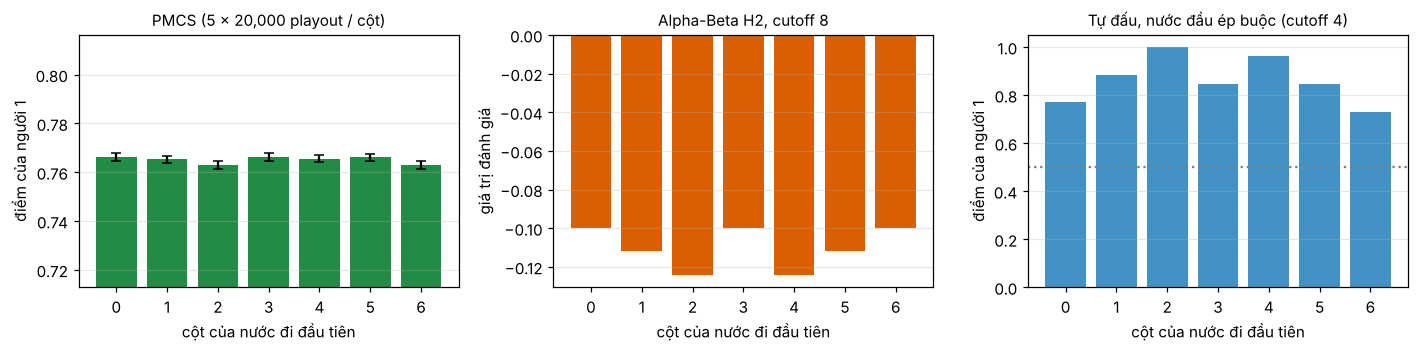

In [40]:
# Your code/ answer goes here.

FIRST_COLS = list(range(7))
# --- 1) PMCS ---
PM_FIRST_N, PM_FIRST_REPS = 20000, 5
g_ = MeanGeometry.get(6, 7)
t0 = time.time()
pm_first = {c: [] for c in FIRST_COLS}
for r in range(PM_FIRST_REPS):
    rng_r = random.Random(555 + r)
    for c in FIRST_COLS:
        cur, opp, val = apply_action(g_, 0, 0, ("drop", c))
        s = sum(random_playout(g_, cur, opp, rng_r) for _ in range(PM_FIRST_N))
        pm_first[c].append(0.5 - 0.5 * s / PM_FIRST_N)                    # điểm của người 1: thắng = 1, hòa = 0,5, thua = 0
pm_mean = {c: float(np.mean(pm_first[c])) for c in FIRST_COLS}
pm_se = math.sqrt(0.25 / (PM_FIRST_N * PM_FIRST_REPS))
print(f"PMCS: {PM_FIRST_REPS} x {PM_FIRST_N:,} playout cho mỗi cột ({7 * PM_FIRST_REPS * PM_FIRST_N:,} playout, {time.time() - t0:.0f} s); sai số chuẩn mỗi cột ≤ ±{pm_se:.3f}.")

# --- 2) Heuristic Alpha-Beta tìm sâu: giá trị của từng nước đi đầu ---
AB_FIRST_CUT = [4, 6, 8]
ab_first = {}
for hname, hf in H_FUNCS.items():
    for d in AB_FIRST_CUT:
        vals = HeuristicAlphaBetaPlayer(cutoff = d, evaluate = hf, symmetry_root = False).action_values(initial_state(), 1)
        ab_first[(hname.split(" ")[0], d)] = {c: float(vals[("drop", c)]) for c in FIRST_COLS}

# --- 3) Tự đấu với nước đầu ép buộc ---
SELF_CUT = 4
self_play, self_n = {}, {}
agent_sp = HeuristicAlphaBetaPlayer(cutoff = SELF_CUT, evaluate = heuristic_windows)
t0 = time.time()
for c in FIRST_COLS:
    b1 = result(initial_state(), 1, ("drop", c))
    outs = []
    for a2 in actions(b1, -1):                                              # mọi phản ứng hợp lệ của người 2 (kể cả chuyển quân đáy)
        b2 = result(b1, -1, a2)
        if terminal(b2): outs.append(-utility(b2, -1)); continue            # (chưa xảy ra ở nước 2)
        outs.append(play_game(agent_sp, agent_sp, b2, 1)["winner"])
    self_n[c] = len(outs)
    self_play[c] = float(np.mean([(w + 1) / 2 for w in outs]))              # điểm của người 1
print(f"Tự đấu (cutoff {SELF_CUT}, H1): {sum(self_n.values())} ván, {time.time() - t0:.0f} s.")

rows_out = []
for c in FIRST_COLS:
    row = {"Cột đầu tiên": c, "PMCS: điểm người 1": round(pm_mean[c], 3)}
    for key, v in ab_first.items(): row[f"Alpha-Beta {key[0]}, cutoff {key[1]}"] = round(v[c], 3)
    row[f"Tự đấu (cutoff {SELF_CUT}): điểm người 1"] = round(self_play[c], 3)
    rows_out.append(row)
first_table = pd.DataFrame(rows_out).set_index("Cột đầu tiên")
display(first_table)

fig, ax = plt.subplots(1, 3, figsize = (13, 3.3), dpi = 110)
ax[0].bar(FIRST_COLS, [pm_mean[c] for c in FIRST_COLS], yerr = pm_se, capsize = 3, color = "#238b45"); ax[0].set_ylim(min(pm_mean.values()) - 0.05, max(pm_mean.values()) + 0.05)
ax[0].set_title(f"PMCS ({PM_FIRST_REPS} x {PM_FIRST_N:,} playout / cột)", fontsize = 10); ax[0].set_ylabel("điểm của người 1")
key_last = [k for k in ab_first if k[0] == "H2"][-1] if any(k[0] == "H2" for k in ab_first) else list(ab_first)[-1]
ax[1].bar(FIRST_COLS, [ab_first[key_last][c] for c in FIRST_COLS], color = "#d95f02"); ax[1].set_title(f"Alpha-Beta {key_last[0]}, cutoff {key_last[1]}", fontsize = 10); ax[1].set_ylabel("giá trị đánh giá")
ax[2].bar(FIRST_COLS, [self_play[c] for c in FIRST_COLS], color = "#4292c6"); ax[2].set_title(f"Tự đấu, nước đầu ép buộc (cutoff {SELF_CUT})", fontsize = 10); ax[2].set_ylabel("điểm của người 1"); ax[2].axhline(0.5, color = "gray", ls = ":")
for a_ in ax: a_.set_xlabel("cột của nước đi đầu tiên"); a_.grid(axis = "y", alpha = .3)
plt.tight_layout(); plt.show()

In [41]:
tol_ab = 0.025                                                                       # chênh lệch giá trị đánh giá nhỏ hơn mức này coi như ngang nhau
se_sp = math.sqrt(0.25 / max(1, min(self_n.values())))
pm_sym = {c: (pm_mean[c] + pm_mean[6 - c]) / 2 for c in FIRST_COLS}                  # gộp hai cột đối xứng để giảm nhiễu
noise = max(abs(pm_mean[a] - pm_mean[6 - a]) for a in (0, 1, 2))
methods = {"PMCS": (pm_sym, 2 * pm_se)}
for k, v in ab_first.items(): methods[f"Alpha-Beta {k[0]}, cutoff {k[1]}"] = (v, tol_ab)
methods[f"Tự đấu (cutoff {SELF_CUT})"] = (self_play, 2 * se_sp)
tops = {name: sorted(c for c in FIRST_COLS if v[c] >= max(v.values()) - tol) for name, (v, tol) in methods.items()}
common = sorted(set.intersection(*[set(s) for s in tops.values()]))
def zs(v):
    arr = np.array([v[c] for c in FIRST_COLS], dtype = float); s = arr.std()
    return (arr - arr.mean()) / (s if s > 1e-9 else 1.0)
avg_z = np.mean([zs(v) for v, _ in methods.values()], axis = 0)
consensus = int(np.argmax(avg_z))
order_z = sorted(FIRST_COLS, key = lambda c: -avg_z[c])
display(Markdown(f"""
**Kết quả.** Cột nào được mỗi phương pháp xếp đầu (hoặc ngang đầu trong phạm vi nhiễu: PMCS ±{2 * pm_se:.3f}, Alpha-Beta ±{tol_ab}, tự đấu ±{2 * se_sp:.2f})?
{chr(10).join(f'* **{name}:** ' + ', '.join(map(str, s)) for name, s in tops.items())}

* **PMCS** gộp hai cột đối xứng; độ chênh lớn nhất giữa hai cột đối xứng là {noise:.3f} (sai số chuẩn lý thuyết ±{pm_se:.3f}) – đó là mức nhiễu của ước lượng; khoảng cách giữa các cột nhỏ hơn mức này thì không đáng tin. Điểm PMCS dao động trong khoảng {min(pm_sym.values()):.3f} – {max(pm_sym.values()):.3f} (người đi trước có ưu thế rõ so với 0,5 vì cả hai bên chơi ngẫu nhiên).
* **Nhóm tốt nhất chung của mọi phương pháp:** {('cột ' + ', '.join(map(str, common))) if common else 'không có – các phương pháp không có cột nào cùng xếp đầu'}.
* **Khuyến nghị** (cột có điểm chuẩn hóa z trung bình cao nhất qua các phương pháp, để mỗi phương pháp đóng góp ngang nhau): **cột {consensus}**; thứ tự: {' > '.join(f'{c} ({avg_z[c]:+.2f})' for c in order_z[:4])}.
* {'Cột giữa phù hợp với Connect 4 thường, nơi nước đầu ở cột giữa là nước duy nhất thắng (Allis, 1988), và với lập luận cột giữa tham gia nhiều cửa sổ 4 ô nhất.' if consensus == 3 else 'Kết quả không phải cột giữa như ở Connect 4 thường – với luật chuyển quân, giá trị các nước đi đầu có thể khác; nhưng chênh lệch giữa các cột nhỏ, nên kết luận chỉ mang tính gợi ý.'}

**Cách xác định nước đi đầu tốt nhất (và giới hạn của nó).** Không thể giải chính xác (cây vô hạn, chưa có lời giải), nên ta ước lượng: (i) PMCS cho giá trị *trung bình dưới chính sách ngẫu nhiên* (nhanh, không cần heuristic, nhưng nhiễu và chỉ phản ánh ván giữa hai người chơi yếu), (ii) Alpha-Beta cho giá trị dưới *chơi tốt trong tầm nhìn* nhưng phụ thuộc chất lượng heuristic, (iii) tự đấu đo trực tiếp kết quả khi hai bên chơi khá tốt. Mỗi phương pháp có thiên lệch riêng nên sự đồng thuận giữa chúng đáng tin hơn bất kỳ phương pháp nào riêng lẻ; khi chúng bất đồng, trung thực nhất là nói rằng các nước đi đầu gần ngang nhau.
"""))


**Kết quả.** Cột nào được mỗi phương pháp xếp đầu (hoặc ngang đầu trong phạm vi nhiễu: PMCS ±0.003, Alpha-Beta ±0.025, tự đấu ±0.28)?
* **PMCS:** 0, 1, 2, 3, 4, 5, 6
* **Alpha-Beta H1, cutoff 4:** 2, 3, 4
* **Alpha-Beta H1, cutoff 6:** 3
* **Alpha-Beta H1, cutoff 8:** 2, 3, 4
* **Alpha-Beta H2, cutoff 4:** 0, 1, 2, 3, 4, 5, 6
* **Alpha-Beta H2, cutoff 6:** 0, 1, 2, 3, 4, 5, 6
* **Alpha-Beta H2, cutoff 8:** 0, 1, 2, 3, 4, 5, 6
* **Tự đấu (cutoff 4):** 0, 1, 2, 3, 4, 5, 6

* **PMCS** gộp hai cột đối xứng; độ chênh lớn nhất giữa hai cột đối xứng là 0.003 (sai số chuẩn lý thuyết ±0.002) – đó là mức nhiễu của ước lượng; khoảng cách giữa các cột nhỏ hơn mức này thì không đáng tin. Điểm PMCS dao động trong khoảng 0.764 – 0.766 (người đi trước có ưu thế rõ so với 0,5 vì cả hai bên chơi ngẫu nhiên).
* **Nhóm tốt nhất chung của mọi phương pháp:** cột 3.
* **Khuyến nghị** (cột có điểm chuẩn hóa z trung bình cao nhất qua các phương pháp, để mỗi phương pháp đóng góp ngang nhau): **cột 3**; thứ tự: 3 (+1.17) > 1 (+0.15) > 5 (+0.10) > 2 (-0.11).
* Cột giữa phù hợp với Connect 4 thường, nơi nước đầu ở cột giữa là nước duy nhất thắng (Allis, 1988), và với lập luận cột giữa tham gia nhiều cửa sổ 4 ô nhất.

**Cách xác định nước đi đầu tốt nhất (và giới hạn của nó).** Không thể giải chính xác (cây vô hạn, chưa có lời giải), nên ta ước lượng: (i) PMCS cho giá trị *trung bình dưới chính sách ngẫu nhiên* (nhanh, không cần heuristic, nhưng nhiễu và chỉ phản ánh ván giữa hai người chơi yếu), (ii) Alpha-Beta cho giá trị dưới *chơi tốt trong tầm nhìn* nhưng phụ thuộc chất lượng heuristic, (iii) tự đấu đo trực tiếp kết quả khi hai bên chơi khá tốt. Mỗi phương pháp có thiên lệch riêng nên sự đồng thuận giữa chúng đáng tin hơn bất kỳ phương pháp nào riêng lẻ; khi chúng bất đồng, trung thực nhất là nói rằng các nước đi đầu gần ngang nhau.


In [42]:
sz = lambda c, d: size_data[(c, d)][0]
c_ref = 7 if 7 in SIZE_COLS else SIZE_COLS[-1]
d_ref = SIZE_DEPTHS[-1]
need = max((min_certain_depth(nm) or DEPTHS_TEST[-1] + 1) for nm in TEST_NAMES)
win_ab = lambda d: 100 * sum(play_stats[(d, r)][0]["thắng"] for r in ("đi trước (X)", "đi sau (O)")) / (2 * N_PLAY)
d_best = PLAY_DEPTHS[-1]
mid_ratio = order_data[(ORDER_VARIANTS[0][0], list(SETS)[1])][0] / order_data[(ORDER_VARIANTS[-1][0], list(SETS)[1])][0]
h1n, h2n = list(H_FUNCS)
cutC = CUTOFFS[-1]
best_man = max(MAN_CUTOFFS, key = lambda d: correct[(h1n, d)] + correct[(h2n, d)])
N_hi = PM_NS[-1]
pm_acc = np.mean([pm_stats[(N_hi, nm)]["acc"] for nm in TEST_BOARDS])
display(Markdown(f"""
## Tổng kết

| Thuật toán | Cách dùng trên bàn 6 × 7 | Chi phí mỗi nước | Chất lượng |
|---|---|---|---|
| Random (baseline) | chọn đều ngẫu nhiên giữa mọi hành động (cả thả quân và chuyển quân) | ≈ 0 | Random vs. Random: người đi trước thắng {100 * fast['res'][1] / NF:.0f} % |
| Alpha-Beta độ sâu cố định (Task 3) | tìm tới độ sâu `depth`; giá trị chính xác *trong tầm nhìn* | {sz(c_ref, SIZE_DEPTHS[0]):.1f} ms (d = {SIZE_DEPTHS[0]}) → {sz(c_ref, d_ref):.0f} ms (d = {d_ref}) | đúng và chắc chắn trên 7/7 bàn thử từ độ sâu {need}; thắng Random {win_ab(d_best):.0f} % (4 × 4, độ sâu {d_best}) |
| Heuristic Alpha-Beta (Task 4) | cắt ở `cutoff`, đánh giá lá bằng H1 / H2 | {cut_data[(h1n, CUTOFFS[0])]['ms']:.2f} ms (cutoff {CUTOFFS[0]}) → {cut_data[(h1n, cutC)]['ms']:.0f} ms (cutoff {cutC}) | đúng {max(correct[(h1n, d)] for d in MAN_CUTOFFS)}/{len(TEST_BOARDS)} bàn thử từ cutoff {first_all[h1n] if first_all[h1n] else '> ' + str(MAN_CUTOFFS[-1])} (H1) |
| Pure Monte Carlo (nâng cao) | N playout ngẫu nhiên chia đều cho các hành động | {np.mean([pm_stats[(PM_NS[0], nm)]['ms'] for nm in TEST_BOARDS]):.0f} ms (N = {PM_NS[0]}) → {np.mean([pm_stats[(N_hi, nm)]['ms'] for nm in TEST_BOARDS]):.0f} ms (N = {N_hi}) | chọn đúng {100 * pm_acc:.0f} % trên 7 bàn thử ở N = {N_hi} |

**Nhận xét chung**

1. **Luật chuyển quân biến bài toán thành tìm kiếm trên đồ thị có chu trình.** Cây trò chơi vô hạn nên không thể tìm "tới cuối ván" như Connect 4 thường: mọi thuật toán phải dùng độ sâu giới hạn, và giá trị Minimax chỉ là chính xác *trong tầm nhìn*. Vì thế chi phí được điều khiển bởi độ sâu (mỗi 2 nửa-nước thêm nhân thời gian lên cỡ ×{(sz(c_ref, d_ref) / sz(c_ref, SIZE_DEPTHS[0])) ** (1 / ((d_ref - SIZE_DEPTHS[0]) / 2)):.0f}) chứ không phải bởi kích thước bàn.
2. **Nước chuyển quân thay đổi cả chiến thuật lẫn cách đánh giá.** Có đòn thắng và đòn phòng thủ chỉ tồn tại nhờ chuyển quân (bàn thử 2, 4, 5, 6); một nước chặn quen thuộc ở Connect 4 thường (thả quân vào ô thắng của đối thủ) có thể thua ở "Mean" Connect 4 (bàn thử 4). Với Random, {100 * fast['gift_win'][1] / max(1, fast['res'][1]):.0f} % số ván người 1 thắng là do nước chuyển quân của đối thủ vô tình "tặng" hàng 4.
3. **Kỹ thuật cài đặt quan trọng không kém thuật toán.** Cùng một Alpha-Beta, việc xét nước thắng ngay và dùng bảng chuyển vị giảm số nút {mid_ratio:.0f} lần trên các thế cờ giữa ván so với duyệt thuần; riêng thứ tự cột chỉ cho cải thiện nhỏ và phụ thuộc thế cờ (xem phần Move ordering).
4. **Hàm heuristic:** hai hàm H1 (cửa sổ + cột giữa) và H2 (thêm hai thành phần riêng của luật "Mean") khác nhau ít về chi phí nhưng trong thí nghiệm thi đấu H2 đạt {h2_h1:.2f} điểm khi gặp H1 ở cùng cutoff (sai số chuẩn ≈ ±{se:.2f}) – {verdict}. Lý do trung thực: hệ số của H2 được chọn theo lập luận chứ không tối ưu hóa trên dữ liệu.
5. **Alpha-Beta so với Monte Carlo:** ở các bàn chiến thuật, Alpha-Beta xác định đúng từ độ sâu nhỏ với chi phí cỡ ms, còn PMCS ở N = {N_hi} mới đạt {100 * pm_acc:.0f} % và tốn nhiều thời gian hơn; PMCS đổi lại không cần heuristic và không phụ thuộc đòn thắng nằm trong tầm nhìn.

**Hạn chế.** Thời gian phụ thuộc máy chạy; các thí nghiệm thi đấu có số ván nhỏ nên sai số chuẩn lớn (đã ghi dưới mỗi bảng); luật chuyển quân được diễn giải bằng các quy ước ghi ở đầu bài (quân được chuyển giữ màu đối thủ, hòa khi cả hai cùng có 4 quân, hòa khi lặp thế 3 lần hoặc quá {MAX_PLIES} nửa-nước) – các quy ước khác sẽ cho kết quả khác.
"""))


## Tổng kết

| Thuật toán | Cách dùng trên bàn 6 × 7 | Chi phí mỗi nước | Chất lượng |
|---|---|---|---|
| Random (baseline) | chọn đều ngẫu nhiên giữa mọi hành động (cả thả quân và chuyển quân) | ≈ 0 | Random vs. Random: người đi trước thắng 76 % |
| Alpha-Beta độ sâu cố định (Task 3) | tìm tới độ sâu `depth`; giá trị chính xác *trong tầm nhìn* | 2.9 ms (d = 4) → 219 ms (d = 8) | đúng và chắc chắn trên 7/7 bàn thử từ độ sâu 5; thắng Random 96 % (4 × 4, độ sâu 6) |
| Heuristic Alpha-Beta (Task 4) | cắt ở `cutoff`, đánh giá lá bằng H1 / H2 | 22.03 ms (cutoff 1) → 959 ms (cutoff 8) | đúng 7/7 bàn thử từ cutoff 2 (H1) |
| Pure Monte Carlo (nâng cao) | N playout ngẫu nhiên chia đều cho các hành động | 4 ms (N = 100) → 418 ms (N = 10000) | chọn đúng 81 % trên 7 bàn thử ở N = 10000 |

**Nhận xét chung**

1. **Luật chuyển quân biến bài toán thành tìm kiếm trên đồ thị có chu trình.** Cây trò chơi vô hạn nên không thể tìm "tới cuối ván" như Connect 4 thường: mọi thuật toán phải dùng độ sâu giới hạn, và giá trị Minimax chỉ là chính xác *trong tầm nhìn*. Vì thế chi phí được điều khiển bởi độ sâu (mỗi 2 nửa-nước thêm nhân thời gian lên cỡ ×9) chứ không phải bởi kích thước bàn.
2. **Nước chuyển quân thay đổi cả chiến thuật lẫn cách đánh giá.** Có đòn thắng và đòn phòng thủ chỉ tồn tại nhờ chuyển quân (bàn thử 2, 4, 5, 6); một nước chặn quen thuộc ở Connect 4 thường (thả quân vào ô thắng của đối thủ) có thể thua ở "Mean" Connect 4 (bàn thử 4). Với Random, 42 % số ván người 1 thắng là do nước chuyển quân của đối thủ vô tình "tặng" hàng 4.
3. **Kỹ thuật cài đặt quan trọng không kém thuật toán.** Cùng một Alpha-Beta, việc xét nước thắng ngay và dùng bảng chuyển vị giảm số nút 5 lần trên các thế cờ giữa ván so với duyệt thuần; riêng thứ tự cột chỉ cho cải thiện nhỏ và phụ thuộc thế cờ (xem phần Move ordering).
4. **Hàm heuristic:** hai hàm H1 (cửa sổ + cột giữa) và H2 (thêm hai thành phần riêng của luật "Mean") khác nhau ít về chi phí nhưng trong thí nghiệm thi đấu H2 đạt 0.32 điểm khi gặp H1 ở cùng cutoff (sai số chuẩn ≈ ±0.06) – H2 thua H1 ở cùng cutoff. Lý do trung thực: hệ số của H2 được chọn theo lập luận chứ không tối ưu hóa trên dữ liệu.
5. **Alpha-Beta so với Monte Carlo:** ở các bàn chiến thuật, Alpha-Beta xác định đúng từ độ sâu nhỏ với chi phí cỡ ms, còn PMCS ở N = 10000 mới đạt 81 % và tốn nhiều thời gian hơn; PMCS đổi lại không cần heuristic và không phụ thuộc đòn thắng nằm trong tầm nhìn.

**Hạn chế.** Thời gian phụ thuộc máy chạy; các thí nghiệm thi đấu có số ván nhỏ nên sai số chuẩn lớn (đã ghi dưới mỗi bảng); luật chuyển quân được diễn giải bằng các quy ước ghi ở đầu bài (quân được chuyển giữ màu đối thủ, hòa khi cả hai cùng có 4 quân, hòa khi lặp thế 3 lần hoặc quá 200 nửa-nước) – các quy ước khác sẽ cho kết quả khác.
